# D gate analysis notebook

This notebook conducts all analyses and figure generation for the dCas9-driven NOT gates (D gates) in the manuscript "Quantitative measurement of synthetic repression curves reveals design challenges for genetic circuit engineering under growth arrest" by Marken JP et al. (2026).

Because the raw fcs data files are large and unwieldy to process, these notebooks read, process, and compress the fcs files and then convert them to a pickle object that is saved in the folder 'pickles'. When running the notebook in the future, one can skip the time-consuming fcs extraction and processing sections and go directly to the unpickling section to proceed with the downstream analysis. The same procedure is applied to the MCMC parameter estimation, where outputs from the MCMC runs are saved externally in a directory called 'MCMC_outputs' as pickle objects which are then loaded in for downstream analysis.

Note that this notebook assumes that folders called 'figs', 'pickles', and 'MCMC_outputs' are present in the same directory as this notebook, and that the raw fcs data files are stored in the same directory as this notebook following the naming provided in the Zenodo repository where they are housed (doi: 10.5281/zenodo.18415279 ).

Throughout this notebook, active growth conditions are referred to by the keyword 'M9' (for the M9CA growth media) and the growth arrest conditions are referred to by the kewyrod 'CL' (for Carbon Limitation). Similarly, each of the gates are referred to by numbered guide RNA values (g1, g2, etc.) which can be converted to the gate nomenclature presented in the manuscript by looking at the dictionary that relates each 'gi' label to the midpoint of the dCas9 binding footprint (this dictionary is called PAM_dict).

## Imports

In [1]:
import os
import pickle
import pandas as pd
import numpy as np
import collections
import glob
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.backends.backend_pdf import PdfPages
import scipy.stats as stats
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
from cycler import cycler
import numpy as np
import pylab
import FlowCal
import copy
from matplotlib.lines import Line2D
import warnings
import corner
from matplotlib.colors import ListedColormap

import emcee

# Set default parameters for plots
sns.set_context("talk", font_scale=1, rc={"lines.linewidth": 2.0, 'lines.markersize': 5})
sns.set_style("ticks")
sns.set_style({"xtick.direction": "in","ytick.direction": "in"})
mpl.rc('axes', prop_cycle=(cycler('color', ['r', 'k', 'b','g','y','m','c']) ))
mpl.rc('text', usetex=False)
#mpl.rc('font',**{'family':'sans-serif','sans-serif':['HelveticaNeueThin']})
#plt.tick_params(top=False, bottom=False, right=False, left=False)
tw = 1.5
sns.set_style({"xtick.major.size": 6, "ytick.major.size": 6,
               "xtick.minor.size": 4, "ytick.minor.size": 4,
               'axes.labelsize': 24,
               'xtick.major.width': tw, 'xtick.minor.width': tw,
               'ytick.major.width': tw, 'ytick.minor.width': tw})

mpl.rc('xtick', labelsize=18) 
mpl.rc('ytick', labelsize=18)
mpl.rc('axes', linewidth=1.75)
plt.gcf().subplots_adjust(bottom=0.15)
sns.set_style({'axes.labelsize': 24, 'axes.titlesize': 24})

# %matplotlib inline
# warnings.filterwarnings(action='once')
warnings.filterwarnings('ignore')

<Figure size 640x480 with 0 Axes>

## Function setup

In [2]:
# gRNA properties

# This is a new PAM dict that shows the position of the central
# bp of the 33bp dCas9 footprint, which is the 5th bp upstream of PAM.
# Positions are given in absolute values, as in 0 is immediately before +1.
# To convert to genomic position, subtract 1 from all negative values.
PAM_dict = {'g1': -27,
            'g2': -22,
            'g3': -5,
            'g4': 12,
            'g5': 23,
            'g6': 25,
            'g8': 43,
            'g9': 50,
            'g10': 67,
            'g11': 101,
            'g12': 156,
            'g13': 160,
           }

strand_dict = {'g1': 'right',
               'g2': 'left',
               'g3': 'right',
               'g4': 'right',
               'g5': 'left',
               'g6': 'right',
               'g8': 'right',
               'g9': 'left',
               'g10': 'left',
               'g11': 'right',
               'g12': 'right',
               'g13': 'left',
              }

def strand_to_footprint(PAM, strand):
    '''
    PAM is an integer.
    strand is a string that is 'right' or 'left'.
    '''
    if strand == 'right':
        rightwindow = PAM + 8 # 9bp overhang beyond gRNA. N in NGG already included.
        leftwindow = PAM - 20 - 1 #1bp overhang beyond gRNA.
    elif strand == 'left':
        rightwindow = PAM + 20 + 1
        leftwindow = PAM - 8
    else:
        raise('Problem with strand')
    return leftwindow, rightwindow

In [3]:
# Helper functions

def Hill_rep_fun(x, params):
    '''
    Hill repression function that returns y for input x.
    Written in numerically stable form.
    '''
    b, a, K, n = params
    return b / (1 + np.exp(n*(np.log(x) - np.log(K)))) + a

def Hill_act_fun(x, params):
    '''
    Hill activation function that returns y for input x.
    Written in numerically stable form.
    '''
    b, a, K, n = params
    return b * np.exp(n*(np.log(x) - np.log(K))) / (1 + np.exp(n*(np.log(x) - np.log(K)))) + a

def symlog_transform(x, linthresh=1.0):
    return np.sign(x) * (np.log1p(np.abs(x / linthresh)))
def symlog_inverse(y, linthresh=1.0):
    return np.sign(y) * linthresh * (np.expm1(np.abs(y)))

def log_lognormal(x, mu, sigma):
    '''
    Returns the log prior for a lognormal distribution.
    Takes x as input in non-log-scaled value.
    To obtain a median of M for the distribution, must input mu = ln(M).
    '''
    return -np.log(x) - np.log(sigma) - 0.5 * np.log(2 * np.pi) - ((np.log(x) - mu) ** 2) / (2 * sigma**2)


In [4]:
# functions for emcee

def log_prior(theta, prior_params):     
    '''
    Lognormal priors for all four parameters.
    '''
    b, a, K, n = theta
    b_params, a_params, K_params, n_params = prior_params
    mub, sigmab = b_params
    mua, sigmaa = a_params
    muK, sigmaK = K_params
    mun, sigman = n_params
    
    # log-normal prior on beta
    logbprior = -np.log(b) - np.log(sigmab) - 0.5 * np.log(2 * np.pi) - ((np.log(b) - mub) ** 2) / (2 * sigmab**2)
    # log-normal prior on alpha
    logaprior = -np.log(a) - np.log(sigmaa) - 0.5 * np.log(2 * np.pi) - ((np.log(a) - mua) ** 2) / (2 * sigmaa**2)
    # log-normal prior on K
    logKprior = -np.log(K) - np.log(sigmaK) - 0.5 * np.log(2 * np.pi) - ((np.log(K) - muK) ** 2) / (2 * sigmaK**2)
    # log-normal prior on n
    lognprior =  -np.log(n) - np.log(sigman) - 0.5 * np.log(2 * np.pi) - ((np.log(n) - mun) ** 2) / (2 * sigman**2)
    
    return logbprior + logaprior + logKprior + lognprior

def log_likelihood(theta, x, y):
    '''
    Model is a Hill repression function, with output in ln() scale.
    This requires data, y, to also be in ln() scale.
    '''
    b, a, K, n = theta

    model = np.log(b / (1 + np.exp(n*(np.log(x) - np.log(K)))) + a) # <- this is ln(Hill rep function), written in numerically stable form
    
    cost = - np.linalg.norm(y - model) # <- Make sure the model and the data are appropriately log-transformed   
    cost_progress.append(cost)
    return cost


def log_probability(theta, x, y, prior_params):
    lp = log_prior(theta, prior_params)
    if not np.isfinite(lp):
        return -np.inf
    return lp + log_likelihood(theta, x, y)

In [5]:
def make_2D_plot(fcs_dict_ls, media, grna, rep, atcs, fill=False, savefig=False, linthresh=1, filetype='png'):
    '''
    Inputs:
        fcs_dict_ls: list of gated fcs dictionaries arranged by replicate
        media: string, 'M9' or 'CL'
        grna: string, 'gN' where N is an integer
        rep: integer, 1,2,3
        atcs: list of strings of labels of atc concentrations (ng/mL).
              First entry is 'Blank'.
        fill: Boolean to determine if margin KDEs are filled or not.
    '''
    cmap = plt.get_cmap('viridis',len(atcs)-1)
    
    fcs_gated_dict = fcs_dict_ls[rep-1]
    
    plt.figure(figsize=(4,4))
    g = sns.JointGrid(space=0)

    med_gfps = np.empty(len(atcs))
    med_rfps = np.empty(len(atcs))
    for n in range(len(atcs)):
        fcs = fcs_gated_dict[media+'_'+grna+'_'+atcs[n]]
        gfps = np.array(fcs[:,5])
        rfps = np.array(fcs[:,7])
        
        # calculate median gfp, rfp values for later
        med_gfps[n] = np.median(gfps)
        med_rfps[n] = np.median(rfps)
    
        # transform gfp, rfp values into symlog space
        symlog_gfps = symlog_transform(gfps, linthresh=linthresh)
        symlog_rfps = symlog_transform(rfps, linthresh=linthresh)
    
        # start filling plots
        if n==0:
            color = 'grey'
        else:
            color = cmap(n-1)
            
        sns.scatterplot(x=rfps, y=gfps, color=color,
                        s=2, alpha=0.1, ax=g.ax_joint,
                        legend=False)
        
        rfp_kde = stats.gaussian_kde(symlog_rfps)
        rfp_xrange = np.linspace(min(symlog_rfps), max(symlog_rfps), 1000)
        rfp_kde_y = rfp_kde(rfp_xrange)
        g.ax_marg_x.plot(symlog_inverse(rfp_xrange, linthresh=linthresh), rfp_kde_y, c=color)
        if fill:
            g.ax_marg_x.fill_between(symlog_inverse(rfp_xrange, linthresh=linthresh), np.zeros(len(rfp_kde_y)), rfp_kde_y, color=color, alpha=0.2)
        
        gfp_kde = stats.gaussian_kde(symlog_gfps)
        gfp_xrange = np.linspace(min(symlog_gfps), max(symlog_gfps), 1000)
        gfp_kde_y = gfp_kde(gfp_xrange)
        g.ax_marg_y.plot(gfp_kde_y, symlog_inverse(gfp_xrange, linthresh=linthresh), c=color)
        if fill:
            g.ax_marg_y.fill_between(gfp_kde_y, symlog_inverse(gfp_xrange, linthresh=linthresh), np.zeros(len(gfp_kde_y)), color=color, alpha=0.2)
    
    # plot medians
    g.ax_joint.scatter(med_rfps[0], med_gfps[0], c='k')
    g.ax_joint.scatter(med_rfps[1:], med_gfps[1:], c='r')
    
    g.ax_joint.set_xscale('symlog', linthresh=linthresh)
    g.ax_joint.set_yscale('log')
    g.ax_joint.axvspan(-linthresh, linthresh, facecolor='grey', alpha=0.1, edgecolor=None)
    g.ax_marg_x.axvspan(-linthresh, linthresh, facecolor='grey', alpha=0.1, edgecolor=None)
    g.ax_joint.set_ylim((1e0,5e6))
    g.ax_joint.set_xlim((-2e1,2e3))
    # g.ax_joint.set_ylim(bottom=1e0)
    g.ax_joint.set_xlabel('Repressor:RFP')
    g.ax_joint.set_ylabel('GFP')
    # g.ax_marg_x.set_title(grna + ', ' + media + ', Rep '+str(rep))
    print(grna + ', ' + media + ', Rep '+str(rep))
    
    if savefig:
        filename = grna + '_' + media + '_rep' + str(rep) + '_2Dplot.'+ filetype
        plt.savefig('./figs/2Dplots/'+filename, bbox_inches='tight')

    plt.show()

## Import FCS data (you can skip this and go to pickle imports if those are there)

### Replicate 1

Beads

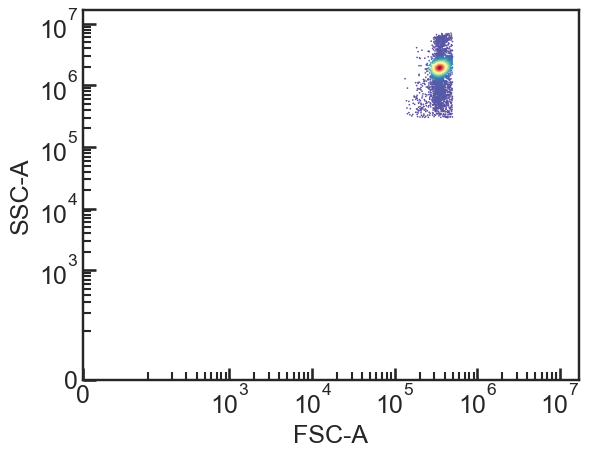

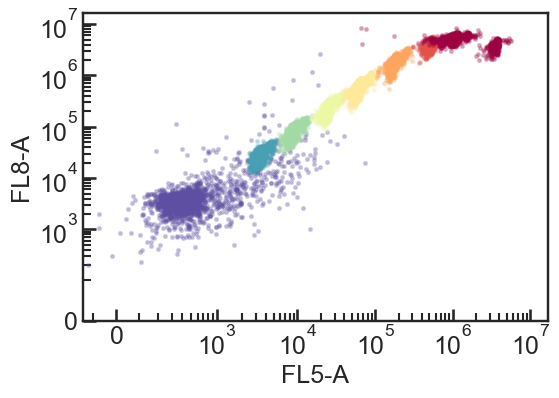

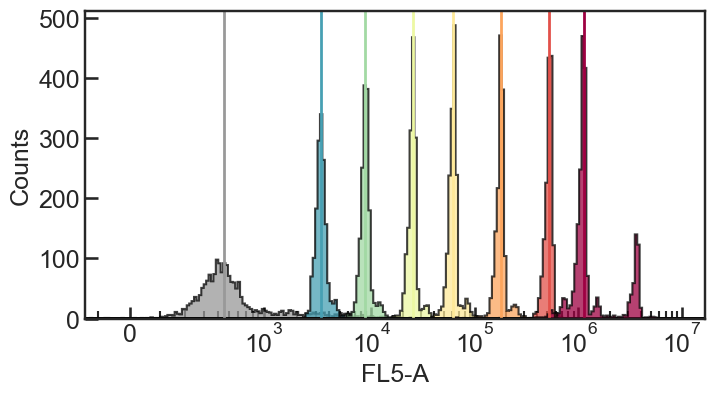

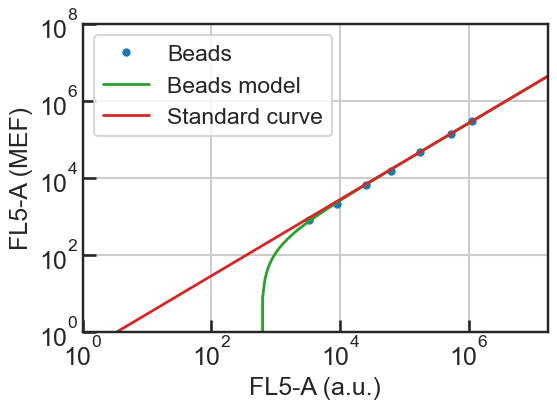

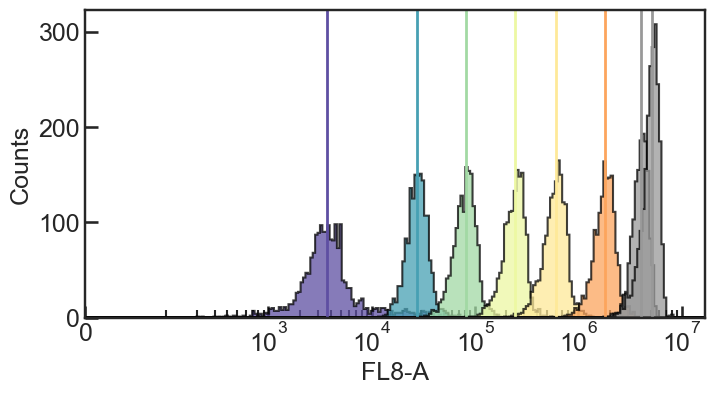

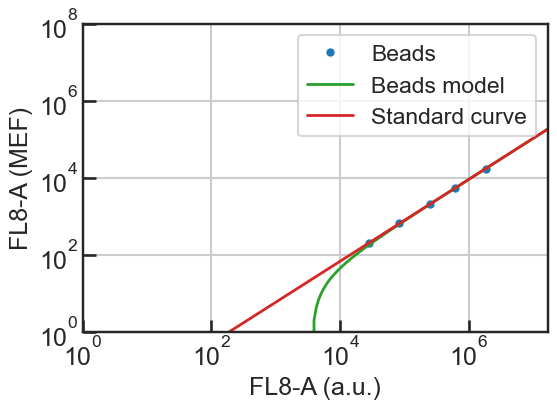

In [20]:
# import FCS data

fileprefix = '../20241130/'

fileext = '.fcs'

m9beads = FlowCal.io.FCSData(fileprefix + '01-Beads-G2' + fileext)

# gate on FSC-A and SSC-A
m9beads_gated = m9beads[(m9beads[:,1] > 1e5) &
                    (m9beads[:,1] < 5e5) &
                    (m9beads[:,3] > 3e5)]
# beads_gated = beads_gated[(beads_gated[:,1] < 8e5) & (beads_gated[:,3] < 3e6)]

FlowCal.plot.density2d(m9beads_gated,
                      channels=['FSC-A','SSC-A'],
                      mode='scatter')

mefl_vals = np.array([0,771,2106,6262,15183,45292,136258,291042])
# meptr_vals = np.array([0,205,643,2021,5278,17018,62451,198933])

# use this because RFP gain is so high that the brightest bead subpopulations overflow.
meptr_vals_low = np.array([0,205,643,2021,5278,17018,np.nan,np.nan]) 

mef_vals = np.array([mefl_vals, meptr_vals_low])

to_mef_m9 = FlowCal.mef.get_transform_fxn(
    m9beads_gated,
    mef_values = mef_vals,
    mef_channels=['FL5-A','FL8-A'],
    plot=True,
)


import FCS files

In [24]:
fcs_dict = dict()

plates = ['04','06','07','08']
rows6 = ['A','B','C','D','E','F']
rows7 = ['A','B','C','D','E','F','G']
grnas6 = ['g1','g2','g3','g4','g5','g6']
grnas7 = ['g8','g9','g10','g11','g12','g13','g14']
cols = [str(i) for i in range(1,13)]

atcs = ['Blank','0','0.02','0.06','0.2','0.43','0.93','2','6','20','60','200']

for plate in plates:
    if (plate=='04') | (plate=='07'):
        rows = rows6
        grnas = grnas6
    else:
        rows = rows7
        if plate == '06':
            grnas = ['g8','g9','g10','g11','g13','g12','g14'] # <- well swap in M9 condition
        else:
            grnas = grnas7
        
    if (plate=='04') | (plate=='06'):
        media = 'M9'
        media_for_key = 'M9'
    else:
        media = 'CLim'
        media_for_key = 'CL'
        
    prefix = plate+'-'+media+'-'
    for r in range(len(rows)):
        for c in range(len(cols)):
            well = rows[r]+cols[c]
            cond = media_for_key+'_'+grnas[r]+'_'+atcs[c]
            
            fcs_dict[cond] = to_mef_m9(FlowCal.transform.to_rfi(FlowCal.io.FCSData(fileprefix + prefix + well + fileext)), channels=['FL5-A','FL8-A'])

        

Replicate 1 specifically had pruning that needed to be done on events

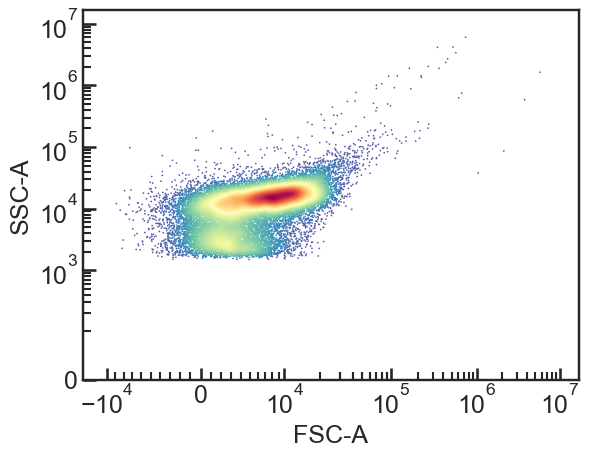

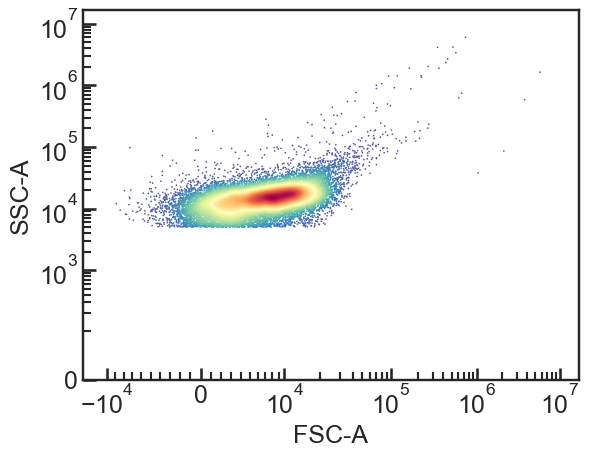

In [25]:
1# example FSC/SSC plot
fcs = fcs_dict['CL_g14_0.02']

FlowCal.plot.density2d(fcs, channels=['FSC-A', 'SSC-A'], mode='scatter')
plt.show()

cl_ssc_thresh = 5e3
fcs_thresh = fcs[fcs[:,3] > cl_ssc_thresh]

# cl_fsc_thresh = 2e3
# fcs_thresh = fcs_thresh[fcs_thresh[:,1] > cl_fsc_thresh]

FlowCal.plot.density2d(fcs_thresh, channels=['FSC-A', 'SSC-A'], mode='scatter')
plt.show()

In [26]:
# iterate through all plots and remove sub-threshold events

for key in fcs_dict.keys():
    fcs = fcs_dict[key]
    fcs = fcs[fcs[:,3] > cl_ssc_thresh]
    # fcs = fcs[fcs[:,1] > cl_fsc_thresh]
    fcs_dict[key] = fcs

Density gating (keep densest 40% on FSC/SSC plot)

In [27]:
# This may take a while to run.
frac_to_keep = 0.4

fcs_gated_dict = dict()

for key in fcs_dict.keys():
    fcs = fcs_dict[key]
    
    fcs_gated = FlowCal.gate.density2d(fcs,
                                       channels=['FSC-A','SSC-A'],
                                       gate_fraction=frac_to_keep,
                                      )
    fcs_gated_dict[key] = fcs_gated

In [28]:
# pickle the resulting dictionary

with open('./pickles/241130_fcs_gated_dict.pkl', 'wb') as f:  # open a text file
    pickle.dump(fcs_gated_dict, f) # serialize the list
f.close()

### Replicate 2

Beads

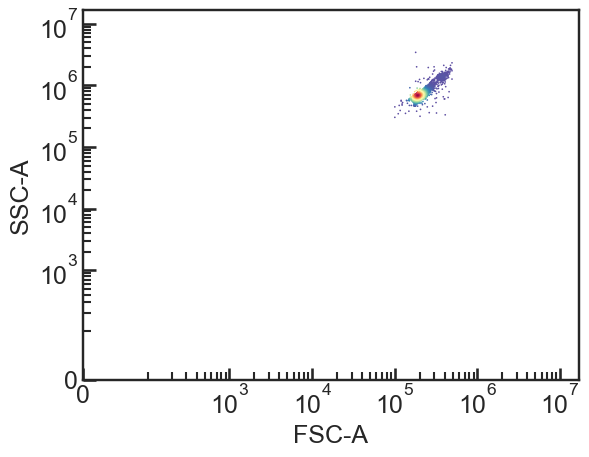

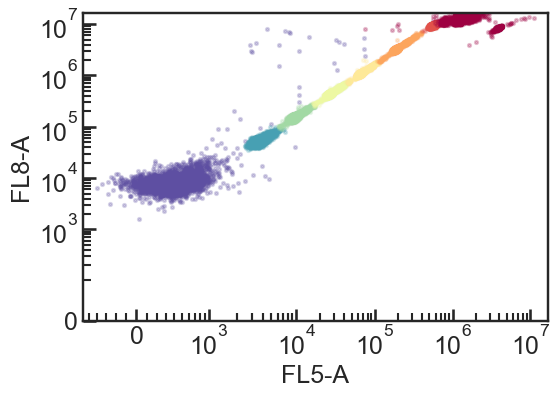

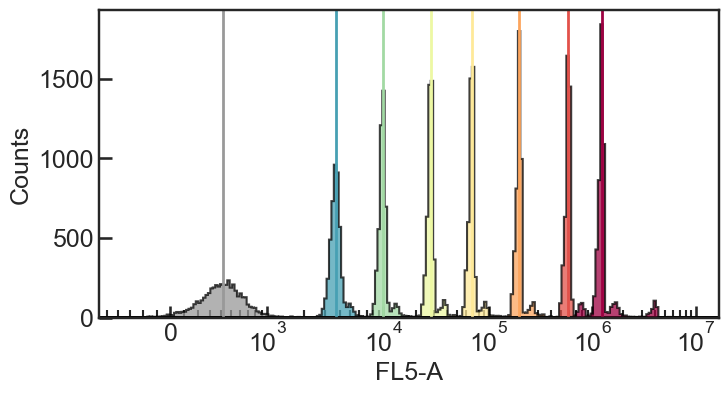

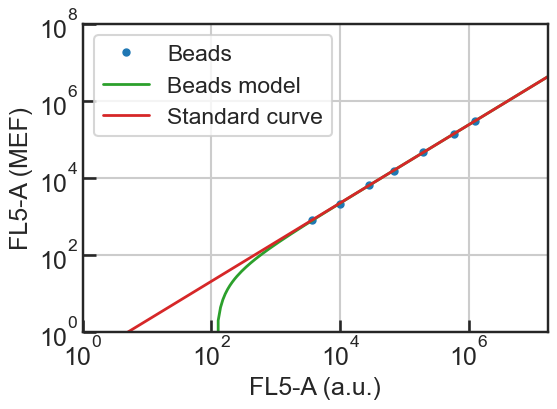

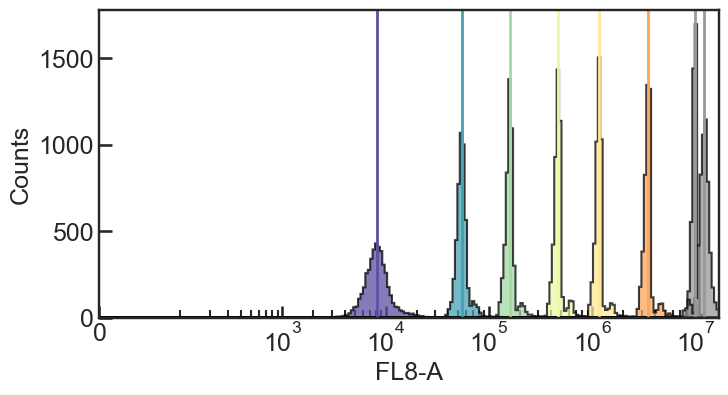

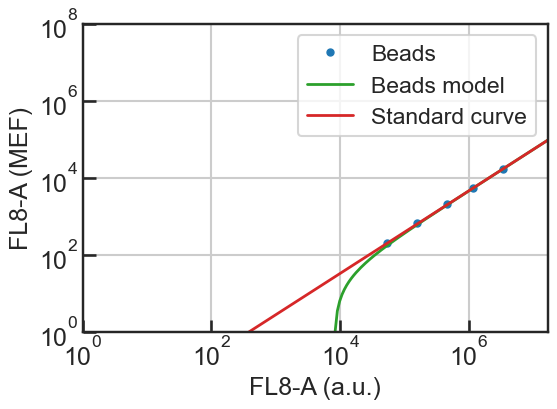

In [29]:
# import FCS data

fileprefix = '../20241205/'

fileext = '.fcs'

m9beads = FlowCal.io.FCSData(fileprefix + '02-Beads-G1' + fileext)

# gate on FSC-A and SSC-A
m9beads_gated = m9beads[(m9beads[:,1] > 1e5) &
                    (m9beads[:,1] < 5e5) &
                    (m9beads[:,3] > 3e5)]
# beads_gated = beads_gated[(beads_gated[:,1] < 8e5) & (beads_gated[:,3] < 3e6)]

FlowCal.plot.density2d(m9beads_gated,
                      channels=['FSC-A','SSC-A'],
                      mode='scatter')

mefl_vals = np.array([0,771,2106,6262,15183,45292,136258,291042])
# meptr_vals = np.array([0,205,643,2021,5278,17018,62451,198933])

# use this because RFP gain is so high that the brightest bead subpopulations overflow.
meptr_vals_low = np.array([0,205,643,2021,5278,17018,np.nan,np.nan]) 

mef_vals = np.array([mefl_vals, meptr_vals_low])

to_mef_m9 = FlowCal.mef.get_transform_fxn(
    m9beads_gated,
    mef_values = mef_vals,
    mef_channels=['FL5-A','FL8-A'],
    plot=True,
)


import FCS files

In [30]:
fcs_dict = dict()

plates = ['04','05','06','07']
rows6 = ['A','B','C','D','E','F']
rows7 = ['A','B','C','D','E','F','G']
grnas6 = ['g1','g2','g3','g4','g5','g6']
grnas7 = ['g8','g9','g10','g11','g12','g13','g14']
cols = [str(i) for i in range(1,13)]

atcs_cl = ['Blank','0','0.02','0.06','0.2','0.43','0.93','2','6','20','60','200']
atcs_m9 = ['Blank','0','0.02','0.2','0.43','0.93','2','3.5','6.3','11.3','20','200']

for plate in plates:
    if (plate=='04') | (plate=='06'):
        rows = rows6
        grnas = grnas6
    else:
        rows = rows7
        grnas = grnas7        
    if (plate=='04') | (plate=='05'):
        media = 'M9'
        media_for_key = 'M9'
        atcs = atcs_m9
    else:
        media = 'CLim'
        media_for_key = 'CL'
        atcs = atcs_cl
        
    prefix = plate+'-'+media+'-'
    for r in range(len(rows)):
        for c in range(len(cols)):
            well = rows[r]+cols[c]
            cond = media_for_key+'_'+grnas[r]+'_'+atcs[c]
            
            fcs_dict[cond] = to_mef_m9(FlowCal.transform.to_rfi(FlowCal.io.FCSData(fileprefix + prefix + well + fileext)), channels=['FL5-A','FL8-A'])

        

Density gating

In [31]:
# This may take a while to run.
frac_to_keep = 0.4

fcs_gated_dict = dict()

for key in fcs_dict.keys():
    fcs = fcs_dict[key]
    
    fcs_gated = FlowCal.gate.density2d(fcs,
                                       channels=['FSC-A','SSC-A'],
                                       gate_fraction=frac_to_keep,
                                      )
    fcs_gated_dict[key] = fcs_gated

Pickle file

In [32]:
# pickle the resulting dictionary

with open('./pickles/241205_fcs_gated_dict.pkl', 'wb') as f:  # open a text file
    pickle.dump(fcs_gated_dict, f) # serialize the list
f.close()

### Replicate 3

Beads

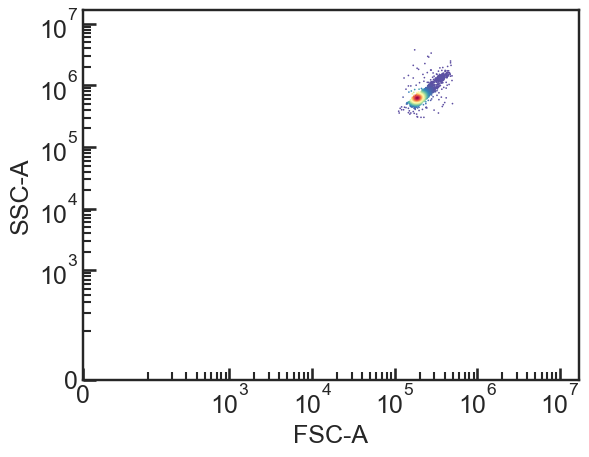

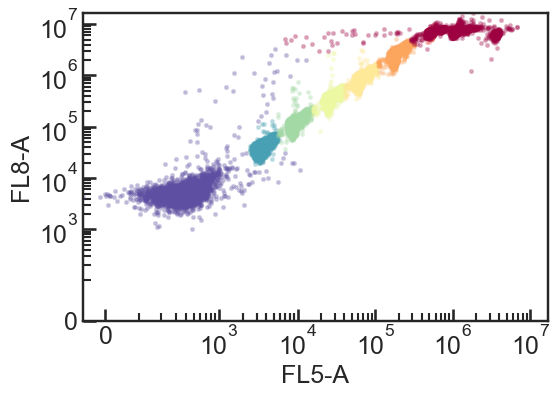

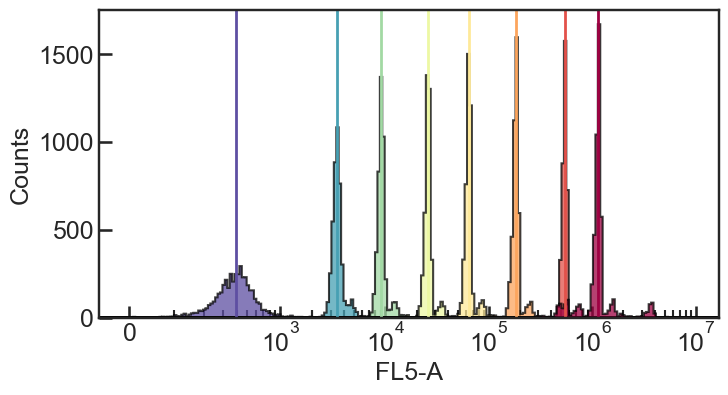

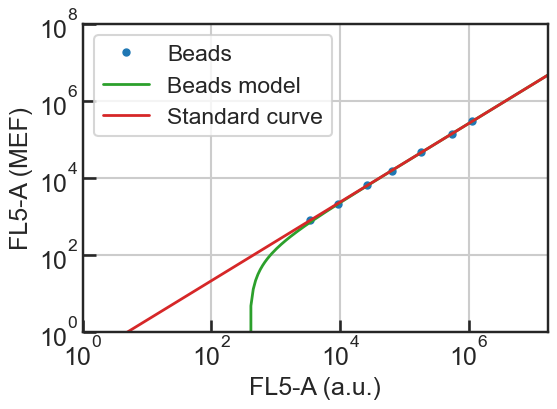

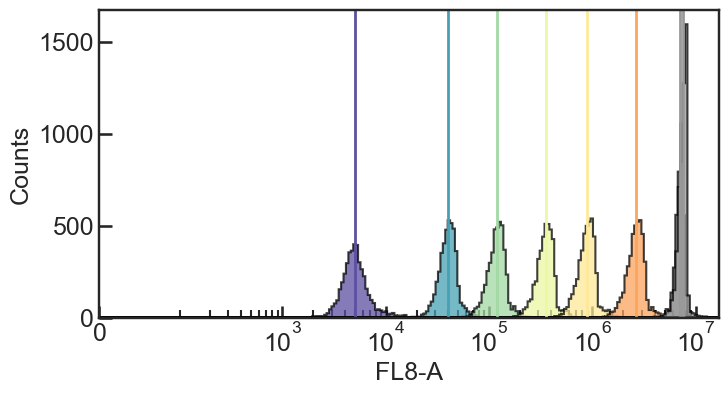

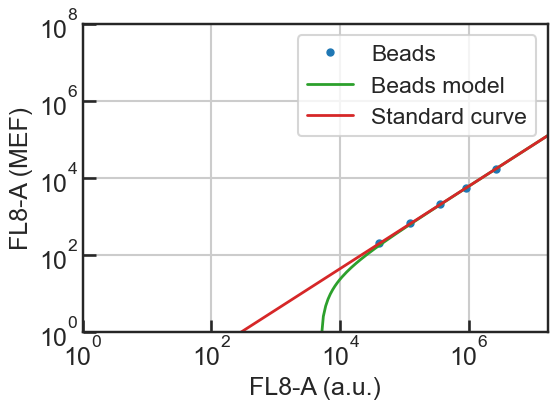

In [33]:
# import FCS data

fileprefix = '../20241208/'

fileext = '.fcs'

m9beads = FlowCal.io.FCSData(fileprefix + '02-Beads-H11' + fileext)

# gate on FSC-A and SSC-A
m9beads_gated = m9beads[(m9beads[:,1] > 1e5) &
                    (m9beads[:,1] < 5e5) &
                    (m9beads[:,3] > 3e5)]
# beads_gated = beads_gated[(beads_gated[:,1] < 8e5) & (beads_gated[:,3] < 3e6)]

FlowCal.plot.density2d(m9beads_gated,
                      channels=['FSC-A','SSC-A'],
                      mode='scatter')

mefl_vals = np.array([0,771,2106,6262,15183,45292,136258,291042])
# meptr_vals = np.array([0,205,643,2021,5278,17018,62451,198933])

# use this because RFP gain is so high that the brightest bead subpopulations overflow.
meptr_vals_low = np.array([0,205,643,2021,5278,17018,np.nan,np.nan]) 

mef_vals = np.array([mefl_vals, meptr_vals_low])

to_mef_m9 = FlowCal.mef.get_transform_fxn(
    m9beads_gated,
    mef_values = mef_vals,
    mef_channels=['FL5-A','FL8-A'],
    plot=True,
)


fcs files

In [34]:
fcs_dict = dict()

plates = ['04','05','06','07']
rows6 = ['A','B','C','D','E','F']
rows7 = ['A','B','C','D','E','F','G']
grnas6 = ['g1','g2','g3','g4','g5','g6']
grnas7 = ['g8','g9','g10','g11','g12','g13','g14']
cols = [str(i) for i in range(1,13)]

atcs_cl = ['Blank','0','0.02','0.06','0.2','0.43','0.93','2','6','20','60','200']
atcs_m9 = ['Blank','0','0.2','0.43','0.93','2','2.6','3.5','6.3','11.3','20','200']

for plate in plates:
    if (plate=='04') | (plate=='06'):
        rows = rows6
        grnas = grnas6
    else:
        rows = rows7
        grnas = grnas7        
    if (plate=='04') | (plate=='05'):
        media = 'M9'
        media_for_key = 'M9'
        atcs = atcs_m9
    else:
        media = 'CLim'
        media_for_key = 'CL'
        atcs = atcs_cl
        
    prefix = plate+'-'+media+'-'
    for r in range(len(rows)):
        for c in range(len(cols)):
            well = rows[r]+cols[c]
            cond = media_for_key+'_'+grnas[r]+'_'+atcs[c]
            
            fcs_dict[cond] = to_mef_m9(FlowCal.transform.to_rfi(FlowCal.io.FCSData(fileprefix + prefix + well + fileext)), channels=['FL5-A','FL8-A'])

        

density gating

In [35]:
# This may take a while to run.
frac_to_keep = 0.4

fcs_gated_dict = dict()

for key in fcs_dict.keys():
    fcs = fcs_dict[key]
    
    fcs_gated = FlowCal.gate.density2d(fcs,
                                       channels=['FSC-A','SSC-A'],
                                       gate_fraction=frac_to_keep,
                                      )
    fcs_gated_dict[key] = fcs_gated

pickle

In [36]:
# pickle the resulting dictionary

with open('./pickles/241208_fcs_gated_dict.pkl', 'wb') as f:  # open a text file
    pickle.dump(fcs_gated_dict, f) # serialize the list
f.close()

## Unpickle FCS files

In [6]:
with open('./pickles/241130_fcs_gated_dict.pkl', 'rb') as f:
    fcs_gated_dict_1 = pickle.load(f)
f.close()

with open('./pickles/241205_fcs_gated_dict.pkl', 'rb') as f:
    fcs_gated_dict_2 = pickle.load(f)
f.close()

with open('./pickles/241208_fcs_gated_dict.pkl', 'rb') as f:
    fcs_gated_dict_3 = pickle.load(f)
f.close()

## Make plots

In [9]:
plot_inds_cl_1 = [0, 0.02, 0.06, 0.2, 0.43, 0.93, 2, 6, 20, 60, 200]
plot_inds_m9_1 = [0, 0.02, 0.06, 0.2, 0.43, 0.93, 2, 6, 20, 60, 200]
plot_inds_cl_2 = [0, 0.02, 0.06, 0.2, 0.43, 0.93, 2, 6, 20, 60, 200]
plot_inds_m9_2 = [0, 0.02, 0.2, 0.43, 0.93, 2, 3.5, 6.3, 11.3, 20, 200]
plot_inds_cl_3 = [0, 0.02, 0.06, 0.2, 0.43, 0.93, 2, 6, 20, 60, 200]
plot_inds_m9_3 = [0, 0.2, 0.43, 0.93, 2, 2.6, 3.5, 6.3, 11.3, 20, 200]

plot_inds_ls = [[plot_inds_m9_1, plot_inds_cl_1],
                [plot_inds_m9_2, plot_inds_cl_2],
                [plot_inds_m9_3, plot_inds_cl_3],
               ]

atcs_cl_1 = ['Blank','0','0.02','0.06','0.2','0.43','0.93','2','6','20','60','200']
atcs_m9_1 = ['Blank','0','0.02','0.06','0.2','0.43','0.93','2','6','20','60','200']
atcs_cl_2 = ['Blank','0','0.02','0.06','0.2','0.43','0.93','2','6','20','60','200']
atcs_m9_2 = ['Blank','0','0.02','0.2','0.43','0.93','2','3.5','6.3','11.3','20','200']
atcs_cl_3 = ['Blank','0','0.02','0.06','0.2','0.43','0.93','2','6','20','60','200']
atcs_m9_3 = ['Blank','0','0.2','0.43','0.93','2','2.6','3.5','6.3','11.3','20','200']

atcs_ls = [[atcs_m9_1, atcs_cl_1],
            [atcs_m9_2, atcs_cl_2],
            [atcs_m9_3, atcs_cl_3],
          ]


medias = ['M9', 'CL']
reps = [1,2,3]
grnas = ['g1','g2','g3','g4','g5','g6',
         'g8','g9','g10','g11','g12','g13','g14']

fcs_dict_ls = [fcs_gated_dict_1,
          fcs_gated_dict_2,
          fcs_gated_dict_3,
         ]

g1, M9, Rep 1


<Figure size 400x400 with 0 Axes>

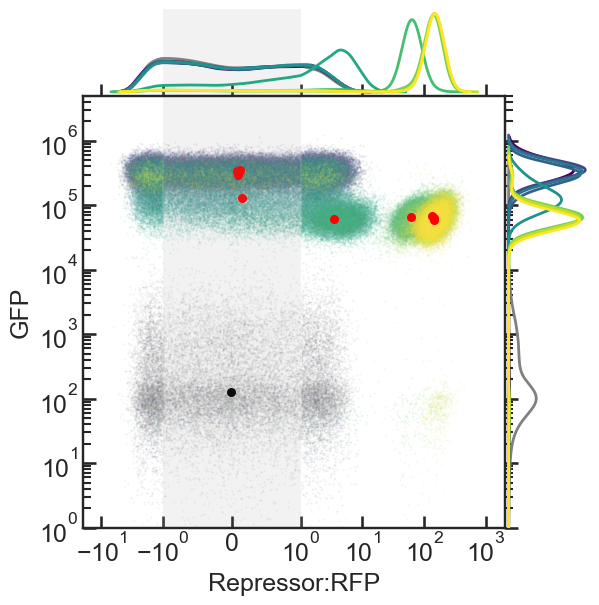

KeyboardInterrupt: 

<Figure size 400x400 with 0 Axes>

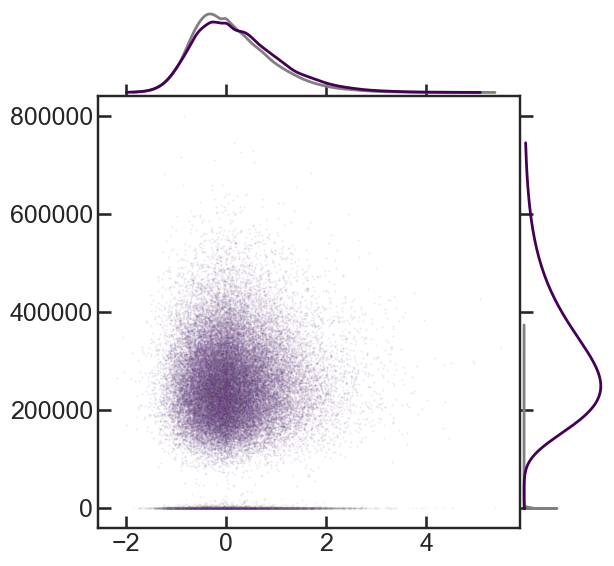

In [10]:
for grna in grnas:
    for m in range(len(medias)):
        media = medias[m]
        for rep in reps:
            atcs = atcs_ls[rep-1][m]

            make_2D_plot(fcs_dict_ls, media, grna, rep, atcs, savefig=True, filetype='png')


## Do Parameter Estimation (Skip this section and go to unpickle if you want)


### Run MCMC and pickle outputs

In [315]:
nwalkers = 32
ndim = 4
chain_length = 10000

sigmaB = 0.5
sigmaA = 1
sigmaK = 1
sigmaN = 0.5
muK = np.log(0.1) + sigmaK**2
muN = np.log(1.0) + sigmaN**2

        
for grna in grnas:
    for m in range(len(medias)):
        media = medias[m]

        med_gfps = []
        med_rfps = []
        unrep_gfps = []
        rep_gfps = []
        for rep in reps:
            fcs_gated_dict = fcs_dict_ls[rep-1]
            plot_inds = plot_inds_ls[rep-1][m]
            atcs = atcs_ls[rep-1][m]
            for n in range(len(plot_inds)):
                fcs = fcs_gated_dict[media+'_'+grna+'_'+atcs[n+1]]
                gfps = np.array(fcs[:,5])
                rfps = np.array(fcs[:,7])
                med_gfps.append(np.median(gfps))
                med_rfps.append(np.median(rfps))
                if n == 0:
                    unrep_gfps.append(np.median(gfps))
                if n == len(plot_inds)-1:
                    rep_gfps.append(np.median(gfps))

        # band-aid fix: set negative values to 1e-6 for fitting
        med_gfps = np.array(med_gfps)
        med_rfps = np.array(med_rfps)
        
        med_gfps[med_gfps < 0] = 1e-6
        med_rfps[med_rfps < 0] = 1e-6

        # prepare for emcee

        # take geomean of repressed GFP values from each replicate
        alpha_guess = stats.gmean(rep_gfps)
        # take geomean of unrepressed GFP values from each replicate
        unrepressed_guess = stats.gmean(unrep_gfps)
        
        beta_guess = unrepressed_guess - alpha_guess
        # what if beta is negative? for now, bandaid fix of set it to 1e-6
        if beta_guess < 0:
            beta_guess = 1e-6

        # ln-scale everything for comparison to ln-scaled model
        med_gfps = np.log(med_gfps)
        alpha_guess = np.log(alpha_guess)
        beta_guess = np.log(beta_guess)
        
        # set prior scale parameters
        muB = beta_guess + sigmaB**2 # <- note that the 'guess' values are already in ln() scale.
        muA = alpha_guess + sigmaA**2
        theta0 = np.exp(np.array([beta_guess, alpha_guess, muK, muN])) # <- initial parameter position is in standard scale
        prior_params = np.array([np.array([muB, sigmaB]),
                                 np.array([muA, sigmaA]),
                                 np.array([muK, sigmaK]),
                                 np.array([muN, sigmaN]),
                                ])

        # random initialization of walkers
        pos = theta0 * (1 + 1e-4 * np.random.randn(nwalkers, ndim))
        pos = 10**(np.log10(theta0) + np.random.randn(nwalkers,ndim)*1e-4) 

        not_long_enough = True
        length_factor = 1        
        while not_long_enough:        
            cost_progress = []
            print('Starting MCMC for '+grna+' , '+media+' for '+str(chain_length*length_factor)+' steps...')
            sampler = emcee.EnsembleSampler(nwalkers, ndim, log_probability, args=(med_rfps, med_gfps, prior_params))
            sampler.run_mcmc(pos, chain_length*length_factor, progress=True);

            autocorr_vec = sampler.get_autocorr_time()
            max_tau = np.max(autocorr_vec)
            if max_tau*50 <= chain_length*length_factor:
                not_long_enough = False
            else:
                length_factor *= 10

            if length_factor >= 100:
                print('******* Chain length too long! aborting. ********')
                not_long_enough = False

        # pickle the sampler output
        filename = grna + '_' + media + '_' + str(nwalkers) + '_' + str(chain_length*length_factor) + '.pkl'
        with open('./MCMC_outputs/'+filename, 'wb') as f:
            pickle.dump(sampler, f)
        f.close()


Starting MCMC for g1 , M9 for 10000 steps...


100%|█████████████████████████████████████| 10000/10000 [00:05<00:00, 1686.34it/s]


Starting MCMC for g1 , CL for 10000 steps...


100%|█████████████████████████████████████| 10000/10000 [00:06<00:00, 1634.61it/s]


Starting MCMC for g2 , M9 for 10000 steps...


...

100%|█████████████████████████████████████| 10000/10000 [00:06<00:00, 1624.52it/s]


Starting MCMC for g14 , M9 for 10000 steps...


100%|█████████████████████████████████████| 10000/10000 [00:06<00:00, 1636.77it/s]


Starting MCMC for g14 , CL for 10000 steps...


100%|█████████████████████████████████████| 10000/10000 [00:06<00:00, 1487.11it/s]


## Unpickle MCMC results and plot

In [8]:
# generate a dataframe of just median (RFP,GFP) values, grouping replicates
medias = ['M9', 'CL']

df_ls = []
for grna in grnas:
    for m in range(len(medias)):
        media = medias[m]
        med_gfps = []
        med_rfps = []
        for rep in reps:
            fcs_gated_dict = fcs_dict_ls[rep-1]
            plot_inds = plot_inds_ls[rep-1][m]
            atcs = atcs_ls[rep-1][m]
            for n in range(len(plot_inds)):
                fcs = fcs_gated_dict[media+'_'+grna+'_'+atcs[n+1]]
                gfps = np.array(fcs[:,5])
                rfps = np.array(fcs[:,7])

                # #bandaid fix: set negative values to epsilon
                # med_gfp = np.max([np.median(gfps), 1e-6])
                # med_rfp = np.max([np.median(rfps), 1e-6])
                med_gfp = np.median(gfps)
                med_rfp = np.median(rfps)
                
                row_to_append = [grna, media, np.log(med_gfp), med_rfp] #<- ln() the GFP values
                df_ls.append(row_to_append)

        df_medians = pd.DataFrame(df_ls, columns=['gRNA','Media','ln median GFP', 'median RFP'])

g1


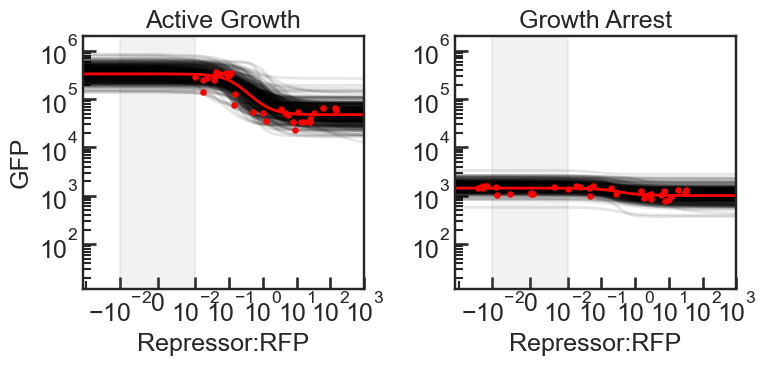

g2


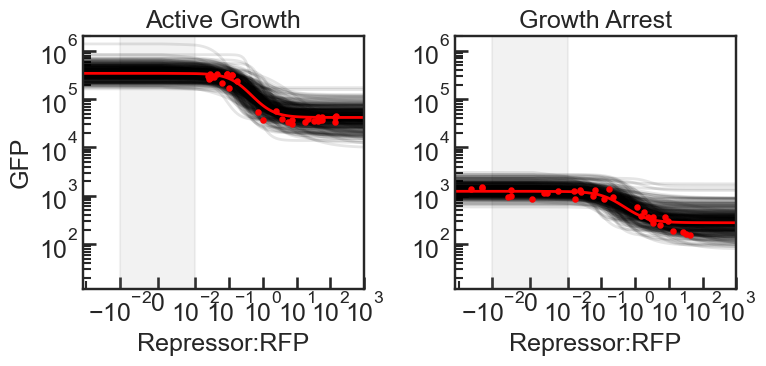

g3


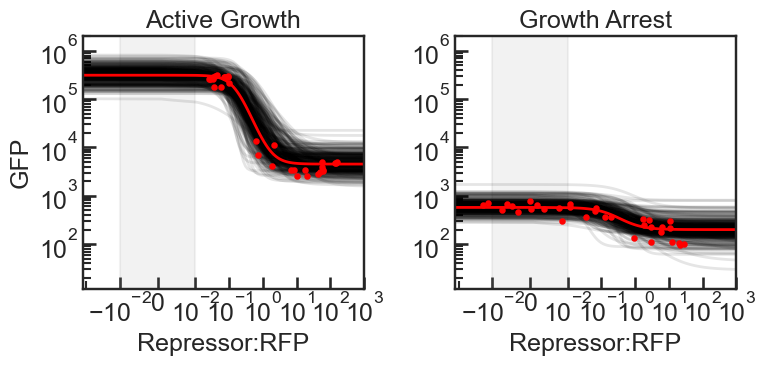

g4


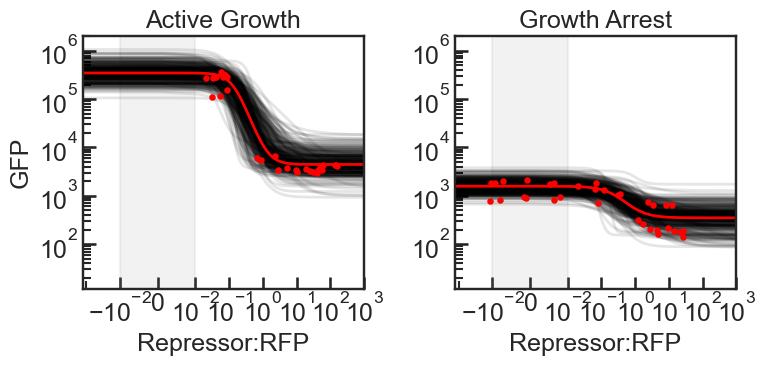

g5


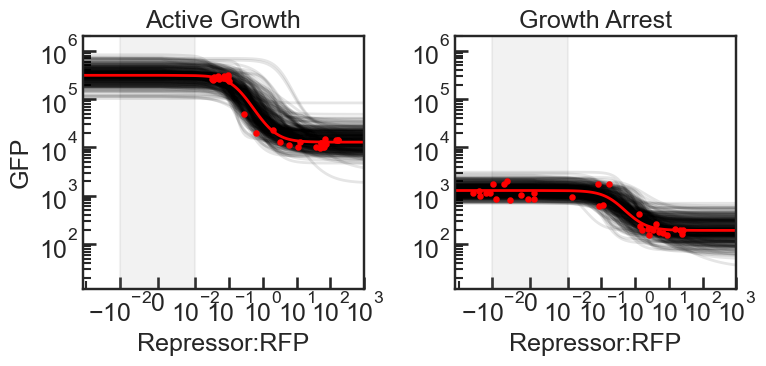

g6


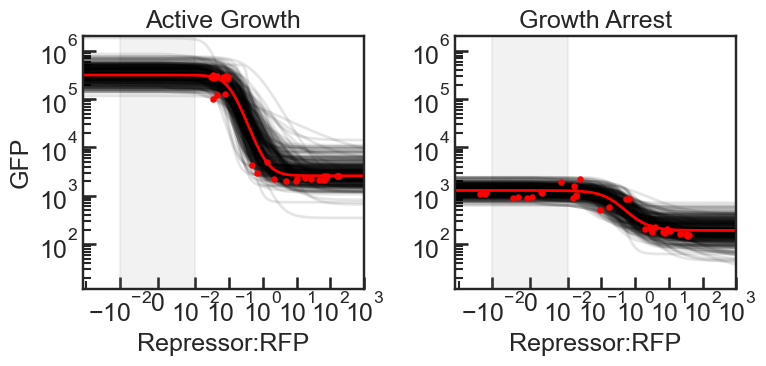

g8


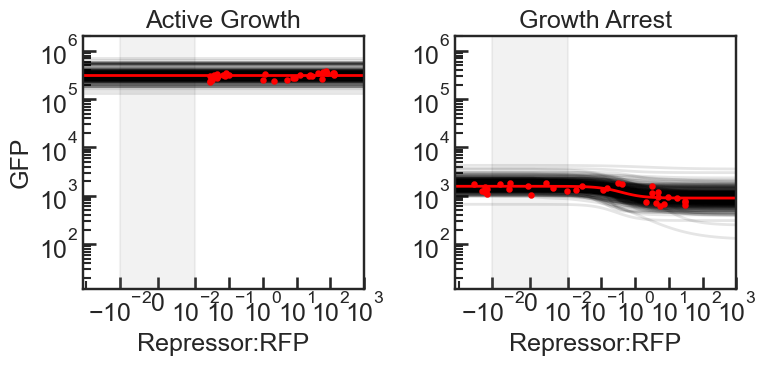

g9


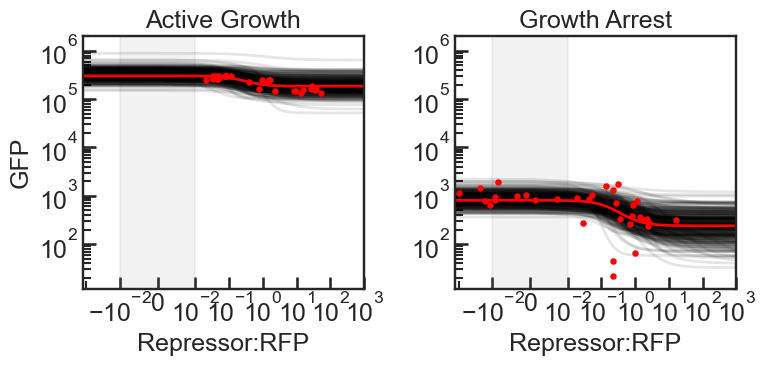

g10


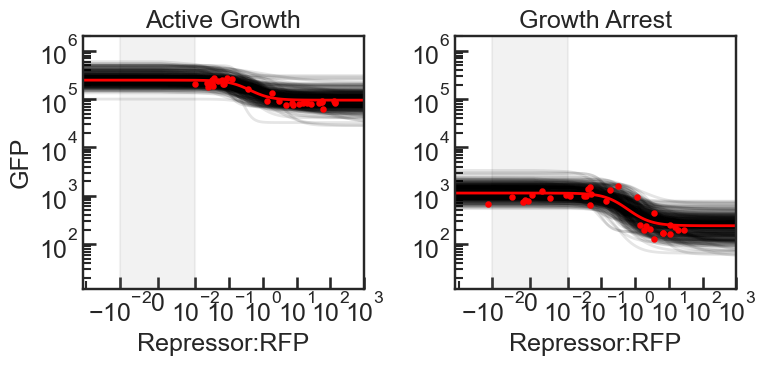

g11


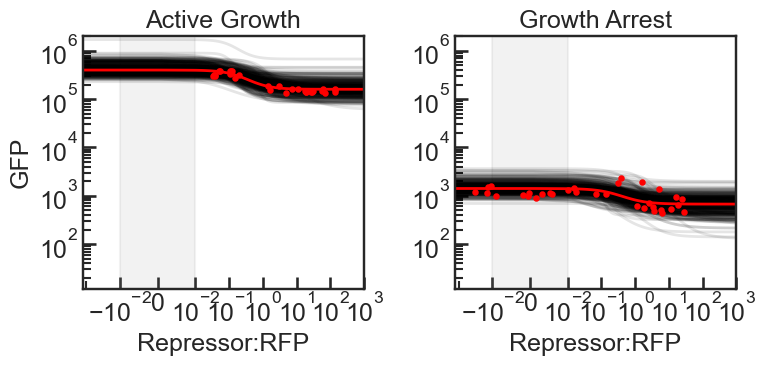

g12


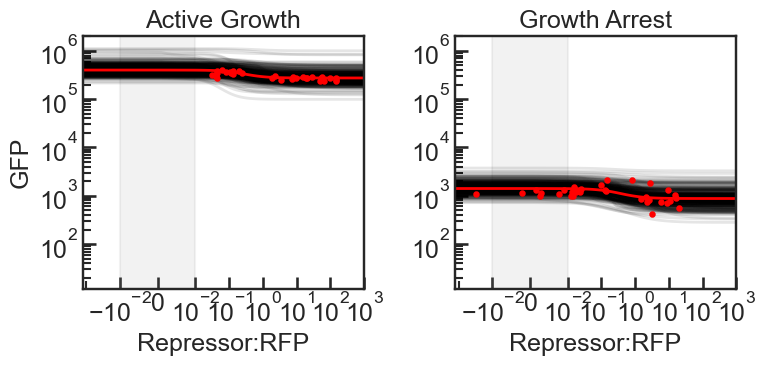

g13


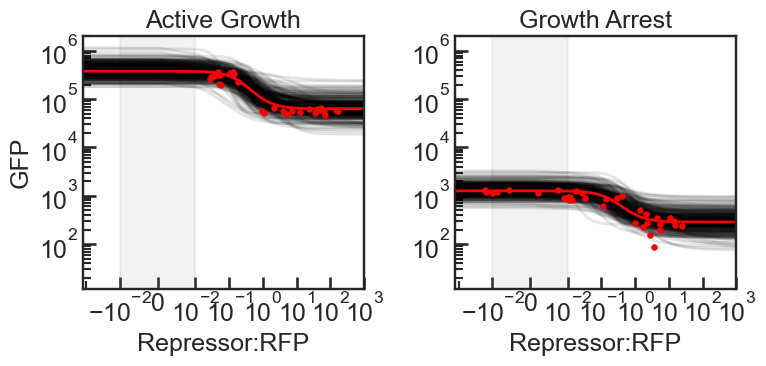

g14


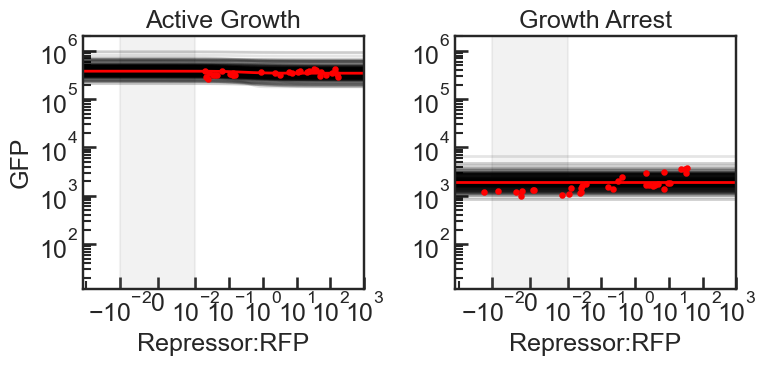

In [11]:

trajectories_to_plot = 300

med_sample_ls = []

for grna in grnas:
    med_sample_one = []
    print(grna)
    fig, ax = plt.subplots(1,2, figsize=(8,4), sharey=False, sharex=True)
    for m in range(len(medias)):
        media = medias[m]

        dfslice = df_medians[(df_medians['gRNA'] == grna) &
                             (df_medians['Media'] == media)]
        
        filename = './MCMC_outputs/'+grna+'_'+media+'_32_10000.pkl'

        with open(filename, 'rb') as f:
            sampler = pickle.load(f)
        f.close()

        flat_samples = sampler.get_chain(discard=9000, flat=True)

        inds = np.random.randint(len(flat_samples), size=trajectories_to_plot)
        
        betas = np.empty(trajectories_to_plot)
        alphas = np.empty(trajectories_to_plot)
        Ks = np.empty(trajectories_to_plot)
        ns = np.empty(trajectories_to_plot)
        for i in range(len(inds)):
            ind = inds[i]
            sample = flat_samples[ind]
            xsmooth = np.logspace(-3,3,100)
            ysmooth = np.log(Hill_rep_fun(xsmooth, sample))
            # append a negative point on the far left for plotting
            xsmooth = np.insert(xsmooth, 0, -10)
            ysmooth = np.insert(ysmooth, 0, np.log(Hill_rep_fun(0, sample)))
            
            ax[m].plot(xsmooth, np.exp(ysmooth), c='k', alpha=0.1)

            betas[i] = sample[0]
            alphas[i] = sample[1]
            Ks[i] = sample[2]
            ns[i] = sample[3]

        # Plot curve with medians of all parameter values
        xsmooth = np.logspace(-3,3,100)
        med_sample = [np.median(betas),
                       np.median(alphas),
                       np.median(Ks),
                       np.median(ns)]
        med_sample_one.append(med_sample)
        ysmooth = np.log(Hill_rep_fun(xsmooth,med_sample))
        xsmooth = np.insert(xsmooth, 0, -10)
        ysmooth = np.insert(ysmooth, 0, np.log(Hill_rep_fun(0, med_sample)))
        ax[m].plot(xsmooth, np.exp(ysmooth), c='r')

        rfp_scatters = dfslice['median RFP'].values
        gfp_scatters = dfslice['ln median GFP'].values
        ax[m].scatter(rfp_scatters, np.exp(gfp_scatters), color='r', s=10, zorder=100)
        
        ax[m].set_xscale('symlog', linthresh=.01)
        ax[m].set_yscale('log')
        ax[m].axvspan(-.01,.01, color='grey', alpha=0.1)
        ax[m].set_xlim((-.13,1e3))
        xticks = ax[m].get_xticks()
        xticklabels = ax[m].get_xticklabels()
        ax[m].set_xticks(xticks[2:])
        ax[m].set_xticklabels(xticklabels[2:])

    med_sample_ls.append(med_sample_one)

    yminmin = 1.2e1
    ymaxmax = 2e6
    ax[0].set_ylim((yminmin, ymaxmax))
    ax[1].set_ylim((yminmin, ymaxmax))

    ax[0].set_title('Active Growth')
    ax[1].set_title('Growth Arrest')
    ax[0].set_ylabel('GFP')
    ax[0].set_xlabel('Repressor:RFP')
    ax[1].set_xlabel('Repressor:RFP')
    # plt.suptitle(grna)
    plt.tight_layout()
    # plt.savefig('./figs/BPEplots/D_'+grna+'.pdf')
    plt.show()
        
        
        

### Plot one corner plot to use in main text figure

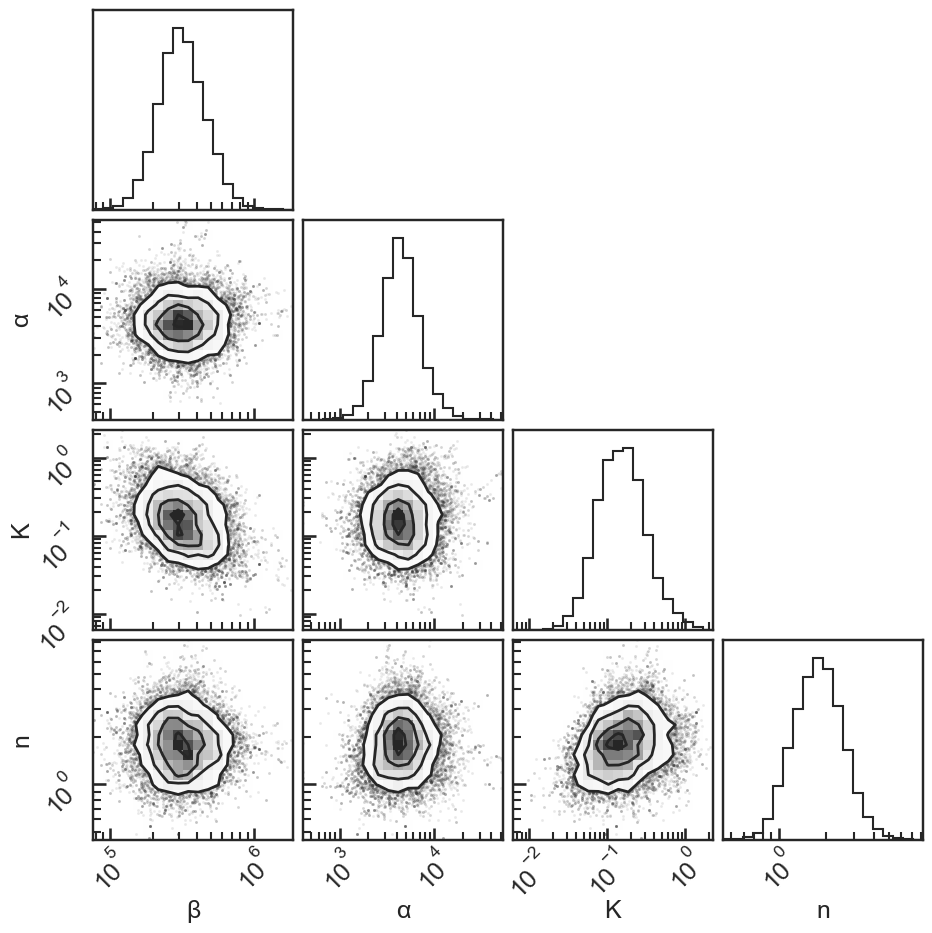

In [10]:
filename = './MCMC_outputs/'+'g3'+'_'+'M9'+'_32_10000.pkl'
with open(filename, 'rb') as f:
    sampler = pickle.load(f)
f.close()
flat_samples = sampler.get_chain(discard=9000, flat=True)

import corner
fig = corner.corner(flat_samples,
                   labels=['β',
                           'α',
                           'K',
                           'n'],
    axes_scale=['log', 'log', 'log', 'log'],
                   )


# Summary statistics and analysis

## GFP levels assocaited with blank, uninduced, max induced conditions

First we want to compare the GFP, RFP levels associated with the 0/0 condition, the 0/1 condition, and the max/1 condition for atc/IPTG. This tells us whether things are working as we expect with regard to things not being leaky etc.

Note that we'll do this directly from the data and not using parameter fits.

In [11]:
#recreate another df_medians-like dataframe but only with the relevant conditions

df_ls = []
for grna in grnas:
    for m in range(len(medias)):
        media = medias[m]
        med_gfps = []
        med_rfps = []
        for rep in reps:
            fcs_gated_dict = fcs_dict_ls[rep-1]
            plot_inds = plot_inds_ls[rep-1][m]
            atcs = atcs_ls[rep-1][m]

            # get Blank condition
            fcs = fcs_gated_dict[media+'_'+grna+'_'+'Blank']
            gfps = np.array(fcs[:,5])
            rfps = np.array(fcs[:,7])
            med_gfp = np.median(gfps)
            med_rfp = np.median(rfps)
            
            row_to_append = ['IPTG –, atc –', grna, rep, media, med_gfp, med_rfp]
            df_ls.append(row_to_append)

            # get no-atc condition
            fcs = fcs_gated_dict[media+'_'+grna+'_'+'0']
            gfps = np.array(fcs[:,5])
            rfps = np.array(fcs[:,7])
            med_gfp = np.median(gfps)
            med_rfp = np.median(rfps)
            
            row_to_append = ['IPTG +, atc –', grna, rep, media, med_gfp, med_rfp]
            df_ls.append(row_to_append)

            # get max-atc condition
            fcs = fcs_gated_dict[media+'_'+grna+'_'+atcs[-1]]
            gfps = np.array(fcs[:,5])
            rfps = np.array(fcs[:,7])
            med_gfp = np.median(gfps)
            med_rfp = np.median(rfps)
            
            row_to_append = ['IPTG +, atc +', grna, rep, media, med_gfp, med_rfp] 
            df_ls.append(row_to_append)

        df_3cond_medians = pd.DataFrame(df_ls, columns=['Condition','gRNA','Replicate','Media','median GFP', 'median RFP'])

# throw out g9 rep1 because it's weird
df_3cond_medians = df_3cond_medians[(df_3cond_medians.gRNA != 'g9') | (df_3cond_medians.Replicate != 1)]

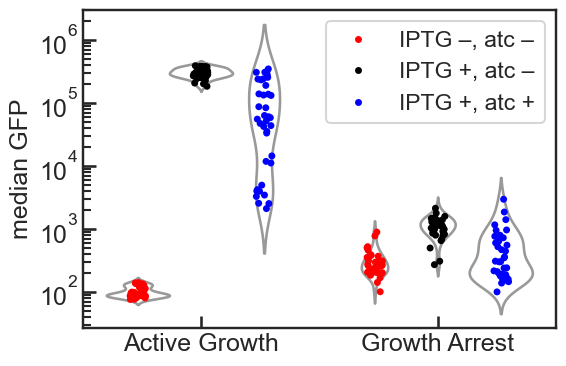

In [12]:
fig, ax = plt.subplots(figsize=(6,4))
sns.stripplot(data=df_3cond_medians,
              x='Media', y='median GFP',
              hue='Condition', dodge=True,
              ax=ax,
             )
sns.violinplot(data=df_3cond_medians,
               x='Media', y='median GFP',
               hue='Condition', dodge=True,
               ax=ax, legend=False, log_scale=True,
               inner=None,
               palette=['w','w','w']
              )
plt.gca().set_yscale('log')
plt.gca().set_xticklabels(['Active Growth', 'Growth Arrest'])
plt.xlabel('')

handles, labels = ax.get_legend_handles_labels()
ax.legend(title='')

plt.tight_layout()
plt.savefig('./figs/251127_leak_and_stuff_v2.pdf')
plt.show()

Let's compute some summary statistics on the above data.

In [50]:
# is there a statistically significant difference between IPTG- and IPTG+ conditions?

m9_blank = df_3cond_medians[(df_3cond_medians.Condition=='IPTG –, atc –') & (df_3cond_medians.Media=='M9')]['median GFP'].values
m9_high = df_3cond_medians[(df_3cond_medians.Condition=='IPTG +, atc –') & (df_3cond_medians.Media=='M9')]['median GFP'].values
cl_blank = df_3cond_medians[(df_3cond_medians.Condition=='IPTG –, atc –') & (df_3cond_medians.Media=='CL')]['median GFP'].values
cl_high = df_3cond_medians[(df_3cond_medians.Condition=='IPTG +, atc –') & (df_3cond_medians.Media=='CL')]['median GFP'].values

m9_ttest = stats.ttest_rel(np.log10(m9_blank), np.log10(m9_high))
cl_ttest = stats.ttest_rel(np.log10(cl_blank), np.log10(cl_high))

print(m9_ttest)
print(cl_ttest)
print()

# what is the difference in geometric means between the distributions?
print(stats.gmean(m9_blank))
print(stats.gmean(m9_high))
print(stats.gmean(m9_high)/stats.gmean(m9_blank))
print()
print(stats.gmean(cl_blank))
print(stats.gmean(cl_high))
print(stats.gmean(cl_high)/stats.gmean(cl_blank))
print()
print(stats.gmean(cl_blank)/stats.gmean(m9_blank))
print(stats.gmean(m9_high)/stats.gmean(cl_high))

TtestResult(statistic=-261.05764442947975, pvalue=5.048247983526915e-62, df=37)
TtestResult(statistic=-17.130090099672383, pvalue=3.530344383025601e-19, df=37)

99.09292359124308
298708.3098236205
3014.426247587447

276.5297550863116
1038.1514542610564
3.754212467794015

2.7906105205553624
287.7309554377472


## Analysis of noise


In [13]:
# make a KDE of GFP values for each experimental condition

kdes_dict = dict()
var_ls_m9 = []
var_ls_cl = []
highvar_keys_ls = []

for m in range(len(medias)):
    media = medias[m]
    for grna in grnas:
        for rep in reps:
            fcs_gated_dict = fcs_dict_ls[rep-1]
            atcs = atcs_ls[rep-1][m]
            plot_inds = plot_inds_ls[rep-1][m]
            for a in range(1,len(atcs)): # ignore Blank values
                atc = atcs[a]

                fcs = fcs_gated_dict[media+'_'+grna+'_'+atc]
                loggfps = np.log10(np.array(fcs[:,5]))
                loggfps = loggfps[~np.isnan(loggfps)] # remove nan values
                loggfps = loggfps[~np.isinf(loggfps)] # remove inf values

                # rescale values by median
                loggfps /= np.median(loggfps)
                
                # do a KDE of the gfp values
                kde = stats.gaussian_kde(loggfps)

                kdes_dict[media+'_'+grna+'_'+atc] = kde

                if media == 'M9':
                    var_ls_m9.append(np.var(loggfps))
                elif media == 'CL':
                    var_ls_cl.append(np.var(loggfps))
                else:
                    print('problem!')

                if np.var(loggfps) > 0.08:
                    highvar_keys_ls.append(media+'_'+grna+'_'+atc+'r'+str(rep))

print(highvar_keys_ls)


['CL_g2_20r2', 'CL_g2_60r2', 'CL_g2_6r3', 'CL_g2_20r3', 'CL_g2_60r3', 'CL_g2_200r3', 'CL_g3_60r1', 'CL_g3_6r2', 'CL_g3_20r2', 'CL_g3_60r2', 'CL_g3_200r2', 'CL_g3_6r3', 'CL_g3_20r3', 'CL_g3_60r3', 'CL_g3_200r3', 'CL_g4_20r2', 'CL_g4_60r2', 'CL_g4_6r3', 'CL_g4_20r3', 'CL_g4_60r3', 'CL_g4_200r3', 'CL_g5_60r2', 'CL_g5_200r2', 'CL_g5_6r3', 'CL_g5_20r3', 'CL_g5_60r3', 'CL_g9_0r1', 'CL_g9_0.02r1', 'CL_g9_0.93r1', 'CL_g9_2r1', 'CL_g9_6r1', 'CL_g9_20r1', 'CL_g9_60r1', 'CL_g9_200r1', 'CL_g9_0r3', 'CL_g9_0.02r3', 'CL_g9_0.06r3', 'CL_g9_0.2r3', 'CL_g9_0.43r3', 'CL_g9_2r3', 'CL_g9_6r3', 'CL_g9_20r3', 'CL_g9_60r3', 'CL_g10_60r1', 'CL_g10_60r2', 'CL_g12_60r2', 'CL_g13_60r1', 'CL_g13_60r2', 'CL_g13_20r3', 'CL_g13_60r3']


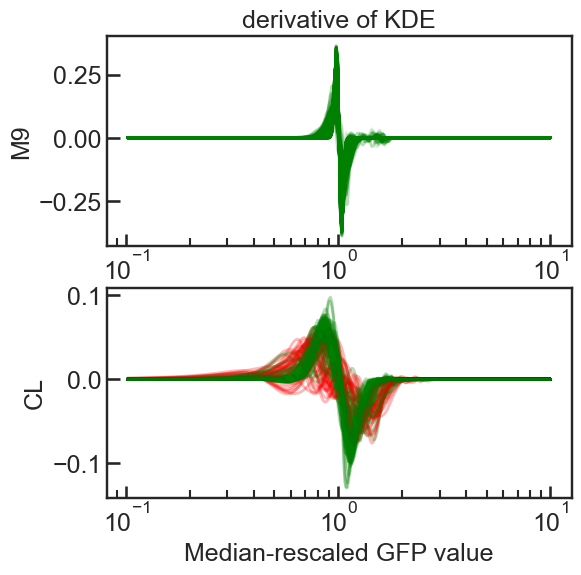

90


In [14]:
# Plot derivative of KDE of GFP values for each experimental condition to look for multimodality

multimodal_key_ls=[]

xrange = np.logspace(-1,1,300)

cross_ls_m9 = []
cross_ls_cl = []
width_ls_m9 = []
width_ls_cl = []
# Plot all non-Blank conditions
fig, ax = plt.subplots(2, 1, figsize=(6,6))
for m in range(len(medias)):
    media = medias[m]
    for grna in grnas:
        for rep in reps:
            atcs = atcs_ls[rep-1][m]            
            for a in range(1,len(atcs)):
                atc = atcs[a]
                kde = kdes_dict[media+'_'+grna+'_'+atc]
                yvals = kde(xrange)
                yvals /= np.max(yvals)
                c='g'

                ydervals = np.diff(yvals)

                # find points that have negative derivative prior to when they're "supposed to"
                lefthalf_ydervals = ydervals[:145] # index corresponding to 0.9 on x scale
                if np.min(lefthalf_ydervals) < -0.005:
                    multimodal_key_ls.append(media+'_'+grna+'_'+atc+'r'+str(rep))
                    c='r'

                ax[m].plot(xrange[1:], ydervals, alpha=0.1, c=c)
                # ax[m].plot(xrange[156:], ydervals[155:], alpha=0.1, c=c) # index corresponding to 1.1 on x scale


ax[0].set_title('derivative of KDE')
ax[0].set_xscale('log')
ax[1].set_xscale('log')
ax[0].set_ylabel('M9')
ax[1].set_ylabel('CL')
ax[1].set_xlabel('Median-rescaled GFP value')

plt.show()

print(len(multimodal_key_ls))

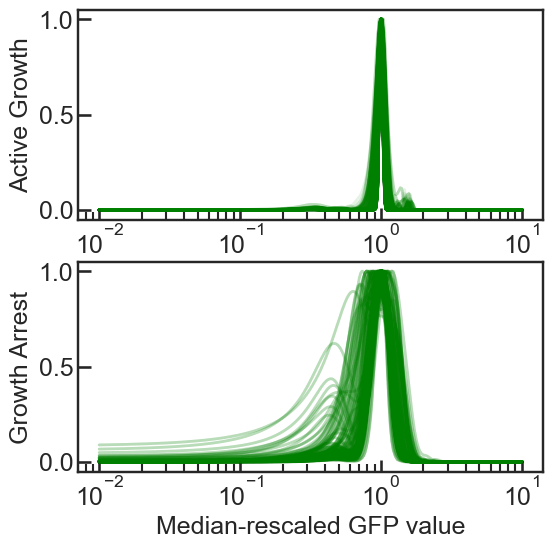

In [15]:
# Plot KDE of GFP values for each experimental condition

xrange = np.logspace(-2,1,300)

num_m9_multimodals = 0
num_cl_multimodals = 0

multimodal_key_ls = []
cross_ls_m9 = []
cross_ls_cl = []
width_ls_m9 = []
width_ls_cl = []
# Plot all non-Blank conditions
fig, ax = plt.subplots(2, 1, figsize=(6,6))
for m in range(len(medias)):
    media = medias[m]
    for grna in grnas:
        for rep in reps:
            atcs = atcs_ls[rep-1][m]            
            for a in range(1,len(atcs)):
                atc = atcs[a]
                kde = kdes_dict[media+'_'+grna+'_'+atc]
                yvals = kde(xrange)
                yvals /= np.max(yvals)
                c='g'
                
                # does it appear to be multimodal?
                ydervals = np.diff(yvals)
                lefthalfind = np.where(xrange>0.9)[0][0] 
                lefthalf_ydervals = ydervals[:lefthalfind]
                if np.min(lefthalf_ydervals) < -0.005:
                    if media == 'M9':
                        num_m9_multimodals += 1
                    elif media == 'CL':
                        num_cl_multimodals += 1
                        
                    multimodal_key_ls.append(media+'_'+grna+'_'+atc+'r'+str(rep))
                    c='g'
                    ax[m].plot(xrange, yvals, alpha=0.1, c=c)
                else:
                    ax[m].plot(xrange, yvals, alpha=0.1, c=c)
                    # pass


                # store x values at which KDE crosses 0.2 on the up and the down
                left_x = np.where(yvals > 0.2)[0][0]
                right_x = np.where(yvals > 0.2)[0][-1]

                if media == 'M9':
                    cross_ls_m9.append((xrange[left_x], xrange[right_x]))
                    width_ls_m9.append(xrange[right_x]/xrange[left_x])
                elif media == 'CL':
                    cross_ls_cl.append((xrange[left_x], xrange[right_x]))
                    width_ls_cl.append(xrange[right_x]/xrange[left_x])
                else:
                    print('problem!')
                

ax[0].set_xscale('log')
ax[1].set_xscale('log')
ax[0].set_ylabel('Active Growth')
ax[1].set_ylabel('Growth Arrest')
ax[1].set_xlabel('Median-rescaled GFP value')

plt.savefig('./figs/251127_KDEs_all.pdf')
plt.show()


In [16]:
print(num_m9_multimodals/len(cross_ls_m9))
print(num_cl_multimodals/len(cross_ls_cl))

0.0
0.23776223776223776


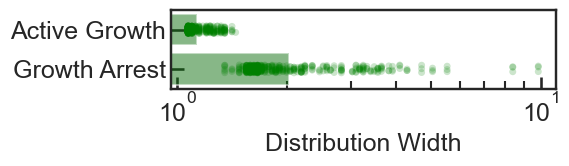

In [17]:
plt.figure(figsize=(6,2))
sns.barplot([stats.gmean(width_ls_m9), stats.gmean(width_ls_cl)], palette=['g','g'], alpha=0.5, orient='h')
sns.stripplot([width_ls_m9, width_ls_cl], palette=['g','g'], alpha=0.2, orient='h')
plt.gca().set_xscale('log')
plt.gca().set_yticklabels(['Active Growth','Growth Arrest'])
plt.xlabel('Distribution Width')
plt.tight_layout()
plt.savefig('./figs/251127_KDE_width.pdf')
plt.show()

In [20]:
print('Gmeans of distribution widths')
print(stats.gmean(width_ls_m9))
print(stats.gmean(width_ls_cl))
print(stats.gmean(width_ls_cl)/stats.gmean(width_ls_m9))
print()
print('Fraction of CL distribtions width within 2X the width of average M9 distribution:')
truth_array = width_ls_cl > stats.gmean(width_ls_m9)*2
print(1 - len(np.where(truth_array)[0])/len(width_ls_cl))

Gmeans of distribution widths
1.1332008643740603
2.0317927745636983
1.7929679004313044

Fraction of CL distribtions width within 2X the width of average M9 distribution:
0.7552447552447552


In [182]:
# make a KDE of RFP values for each experimental condition

kdes_dict = dict()

for m in range(len(medias)):
    media = medias[m]
    for grna in grnas:
        for rep in reps:
            fcs_gated_dict = fcs_dict_ls[rep-1]
            atcs = atcs_ls[rep-1][m]
            plot_inds = plot_inds_ls[rep-1][m]
            for a in range(len(atcs)):
                atc = atcs[a]

                fcs = fcs_gated_dict[media+'_'+grna+'_'+atc]
                rfps = np.array(fcs[:,7])
                rfps += 100 # shift everything to the right to get rid of negative values <- ACTUALLY THIS IS NOT THE RIGHT APPROACH I SHOULD DO A SYMLOG TRANSFORM ON THE RFP VALUES.
                logrfps = np.log10(rfps)
                logrfps = logrfps[~np.isnan(logrfps)] # remove nan values
                logrfps = logrfps[~np.isinf(logrfps)] # remove inf values

                # rescale values by median
                logrfps /= np.median(logrfps)
                
                # do a KDE of the gfp values
                kde = stats.gaussian_kde(logrfps)

                kdes_dict[media+'_'+grna+'_'+atc] = kde


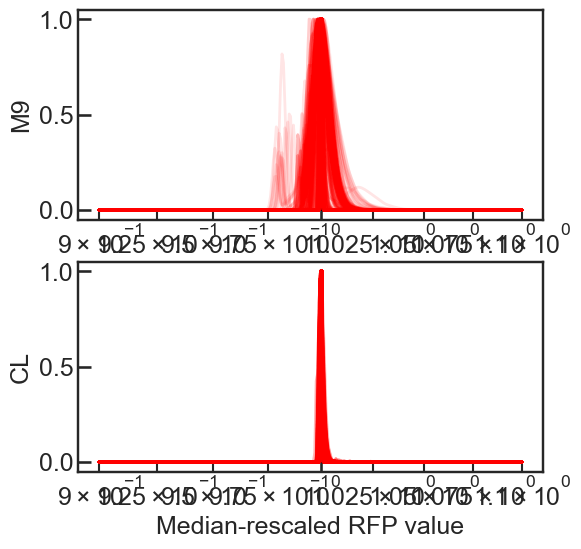

In [186]:
# Plot KDE of RFP values for each experimental condition

# xrange = np.logspace(-0.1,0.1,300)
xrange = np.linspace(0.9,1.1,300)

cross_ls_m9 = []
cross_ls_cl = []
width_ls_m9 = []
width_ls_cl = []
# Plot all non-Blank conditions
fig, ax = plt.subplots(2, 1, figsize=(6,6))
for m in range(len(medias)):
    media = medias[m]
    for grna in grnas:
        for rep in reps:
            atcs = atcs_ls[rep-1][m]            
            for a in range(1,len(atcs)):
                atc = atcs[a]
                kde = kdes_dict[media+'_'+grna+'_'+atc]
                yvals = kde(xrange)
                yvals /= np.max(yvals)
                c='r'
                    
                ax[m].plot(xrange, yvals, alpha=0.1, c=c)


                # # store x values at which KDE crosses 0.2 on the up and the down
                # left_x = np.where(yvals > 0.2)[0][0]
                # right_x = np.where(yvals > 0.2)[0][-1]

                # if media == 'M9':
                #     cross_ls_m9.append((xrange[left_x], xrange[right_x]))
                #     width_ls_m9.append(xrange[right_x]/xrange[left_x])
                # elif media == 'CL':
                #     cross_ls_cl.append((xrange[left_x], xrange[right_x]))
                #     width_ls_cl.append(xrange[right_x]/xrange[left_x])
                # else:
                #     print('problem!')
                

ax[0].set_xscale('log')
ax[1].set_xscale('log')
ax[0].set_ylabel('M9')
ax[1].set_ylabel('CL')
ax[1].set_xlabel('Median-rescaled RFP value')
plt.show()


In [ ]:
plt.figure(figsize=(3,6))
sns.barplot([stats.gmean(width_ls_m9), stats.gmean(width_ls_cl)], palette=['r','r'], alpha=0.5)
sns.stripplot([width_ls_m9, width_ls_cl], palette=['r','r'], alpha=0.2)
plt.gca().set_yscale('log')
plt.gca().set_xticklabels(['M9','CL'])
plt.ylabel('Distribution Width')
plt.show()

plt.figure(figsize=(6,3))
sns.stripplot([[c[0] for c in cross_ls_m9], [c[1] for c in cross_ls_m9],
               [c[0] for c in cross_ls_cl], [c[1] for c in cross_ls_cl],
              ],
             orient='h', palette=['r','r','r','r'],
              alpha=0.2
             )
plt.gca().set_xscale('log')
plt.xlabel('Median-rescaled RFP value')
plt.title('Distribution width left,right locations')
plt.gca().set_yticklabels(['M9','M9','CL','CL'])
plt.show()

## More analysis

### Plot out fit parameter values

First we will make a dataframe collecting the fit parameter values

In [13]:
# width for violin plots so that distributions
# represent 33bp dCas9 footprint width
vw = 15

In [14]:
medias = ['M9', 'CL']

data = []
for grna in grnas:
    if grna != 'g14':
        strand = strand_dict[grna]
        PAM = PAM_dict[grna]
        foldrep_ls = []
        betas_ls = []
        alphas_ls = []
        Ks_ls = []
        ns_ls = []
        for m in range(len(medias)):
            media = medias[m]
            
            filename = './MCMC_outputs/'+grna+'_'+media+'_32_10000.pkl'
            with open(filename, 'rb') as f:
                sampler = pickle.load(f)
            f.close()
            flat_samples = sampler.get_chain(discard=9000, flat=True)
            
            betas = flat_samples[:,0]
            alphas = flat_samples[:,1]
            Ks = flat_samples[:,2]
            ns = flat_samples[:,3]
            foldreps = betas/alphas + 1 # <- Fold Change is (beta+alpha)/alpha

            foldrep_ls.append(foldreps)
            betas_ls.append(betas)
            alphas_ls.append(alphas)
            Ks_ls.append(Ks)
            ns_ls.append(ns)
            
            for i in range(len(foldreps)):
                data.append([media, PAM, strand, foldreps[i],
                             betas[i], alphas[i],Ks[i], ns[i]])
        
        foldreps_delta = foldrep_ls[1]/foldrep_ls[0]
        betas_delta = betas_ls[1]/betas_ls[0]
        alphas_delta = alphas_ls[1]/alphas_ls[0]
        Ks_delta = Ks_ls[1]/Ks_ls[0]
        ns_delta = ns_ls[1]/ns_ls[0]
        for i in range(len(foldreps_delta)):
            data.append(['Delta', PAM, strand, foldreps_delta[i],
                         betas_delta[i], alphas_delta[i],
                         Ks_delta[i], ns_delta[i]])

df = pd.DataFrame(data, columns=['Media','Location','Orientation',
                                 'Fold Repression', 'Beta', 'Alpha',
                                 'K', 'n'])

Let's start by plotting just beta, alpha.

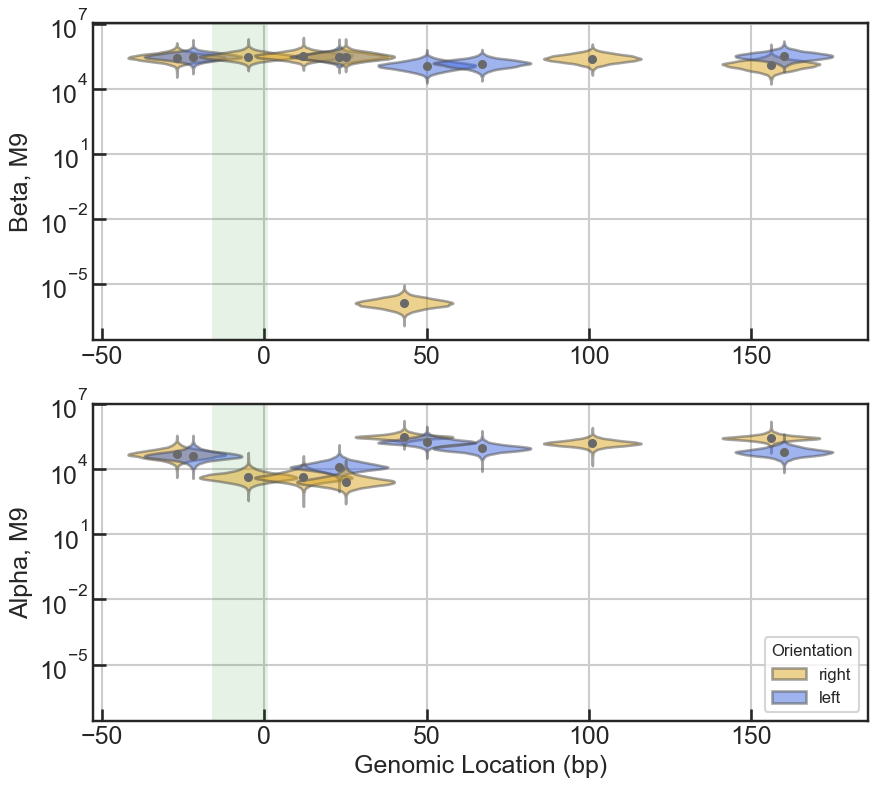

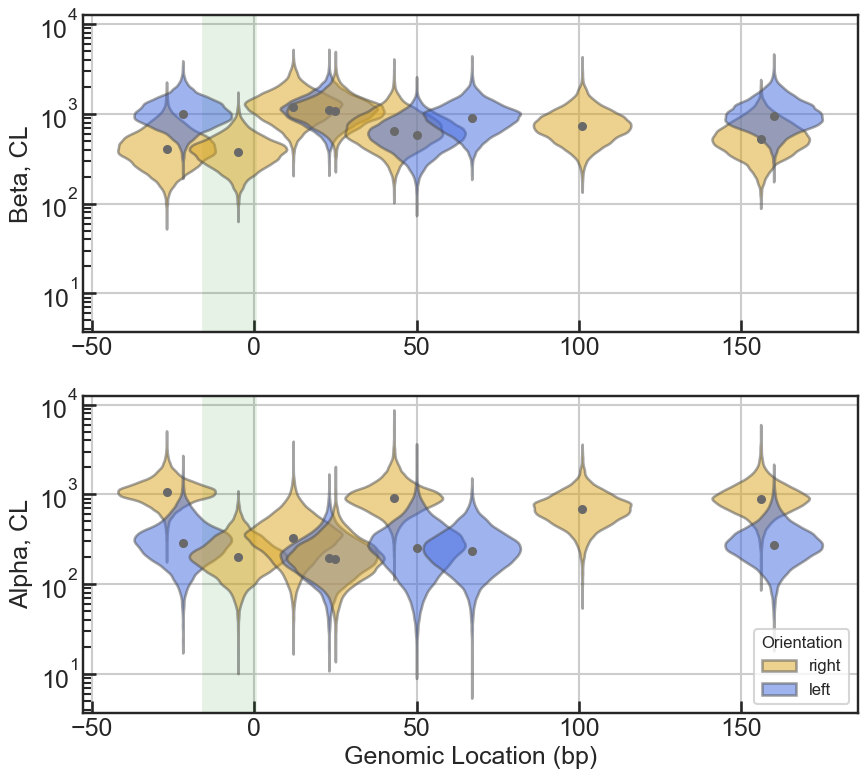

In [15]:
# Plot just M9 beta, alpha

fig = plt.figure(figsize=(10,14))
ax1 = fig.add_subplot(3,1,1)
ax2 = fig.add_subplot(3,1,2, sharey=ax1)
# Plot T7 promoter window
ax1.axvspan(-16,1, facecolor='g', alpha=0.1)
ax2.axvspan(-16,1, facecolor='g', alpha=0.1)

sns.violinplot(data=df[df.Media == 'M9'],
               x='Location', y='Beta', hue='Orientation',
               palette=['goldenrod','royalblue'],
               native_scale=True, ax=ax1,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
              )

sns.violinplot(data=df[df.Media == 'M9'],
               x='Location', y='Alpha', hue='Orientation',
               palette=['goldenrod','royalblue'],
               native_scale=True, ax=ax2,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw,
               saturation=1,
               alpha=0.5,
               legend=True,
               scale='width',
              )

# plot medians
beta_medians = df[df.Media=='M9'].groupby('Location')['Beta'].median()
alpha_medians = df[df.Media=='M9'].groupby('Location')['Alpha'].median()
ax1.scatter(np.array(beta_medians.index), np.array(beta_medians), c='dimgrey')
ax2.scatter(np.array(alpha_medians.index), np.array(alpha_medians), c='dimgrey')


ax1.set_ylabel('Beta, M9')
ax2.set_ylabel('Alpha, M9')
ax1.set_xlabel('')
ax2.set_xlabel('Genomic Location (bp)')
ax2.legend(loc='lower right', title='Orientation', fontsize=12, title_fontsize=12)
ax1.grid()
ax2.grid()

# # check that violin widths are right
# ax1.axvline(-27, linestyle='--')
# ax1.axvline(-27-16, linestyle='--')
# ax1.axvline(-27+16, linestyle='--')

plt.show()

# CLim Beta, Alpha

fig = plt.figure(figsize=(10,14))
ax1 = fig.add_subplot(3,1,1)
ax2 = fig.add_subplot(3,1,2, sharey=ax1)
# Plot T7 promoter window
ax1.axvspan(-16,1, facecolor='g', alpha=0.1)
ax2.axvspan(-16,1, facecolor='g', alpha=0.1)

sns.violinplot(data=df[df.Media == 'CL'],
               x='Location', y='Beta', hue='Orientation',
               palette=['goldenrod','royalblue'],
               native_scale=True, ax=ax1,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
              )

sns.violinplot(data=df[df.Media == 'CL'],
               x='Location', y='Alpha', hue='Orientation',
               palette=['goldenrod','royalblue'],
               native_scale=True, ax=ax2,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw,
               saturation=1,
               alpha=0.5,
               legend=True,
               scale='width',
              )

# plot medians
beta_medians = df[df.Media=='CL'].groupby('Location')['Beta'].median()
alpha_medians = df[df.Media=='CL'].groupby('Location')['Alpha'].median()
ax1.scatter(np.array(beta_medians.index), np.array(beta_medians), c='dimgrey')
ax2.scatter(np.array(alpha_medians.index), np.array(alpha_medians), c='dimgrey')


ax1.set_ylabel('Beta, CL')
ax2.set_ylabel('Alpha, CL')
ax1.set_xlabel('')
ax2.set_xlabel('Genomic Location (bp)')
ax2.legend(loc='lower right', title='Orientation', fontsize=12, title_fontsize=12)
ax1.grid()
ax2.grid()

plt.show()

Let's do a quick spot-check. How do the beta and alpha values compare between M9 and CL, and do these match what we saw for raw unrepressed and repressed GFP values without parameter estimation?

Note that we can't compare $\alpha$ to uninduced condition because $\alpha$ will correspond to the acctual curve itself, not the dynamic range of PT7 expressino. But $\beta$ should be comparable.

In [16]:
beta_medians_m9 = np.array(df[df.Media=='M9'].groupby('Location')['Beta'].median())
alpha_medians_m9 = np.array(df[df.Media=='M9'].groupby('Location')['Alpha'].median())
beta_medians_cl = np.array(df[df.Media=='CL'].groupby('Location')['Beta'].median())
alpha_medians_cl = np.array(df[df.Media=='CL'].groupby('Location')['Alpha'].median())

# remove the gate that didn't repress in M9
beta_medians_m9 = np.delete(beta_medians_m9, 6)
alpha_medians_m9 = np.delete(alpha_medians_m9, 6)

gmbm9 = stats.gmean(beta_medians_m9)
gmam9 = stats.gmean(alpha_medians_m9)
gmbcl = stats.gmean(beta_medians_cl)
gmacl = stats.gmean(alpha_medians_cl)

print(gmbm9)
print()
print(gmbcl)
print()
print(gmbm9/gmbcl)

240687.94379382752

740.989987640584

324.81942780389204


We see that $\beta$ experiences a 300-fold reduction between active growth and growth arrest, as we observed for unrepressed GFP expression level.

Now let's plot fold repression, K, n for M9 and for CL

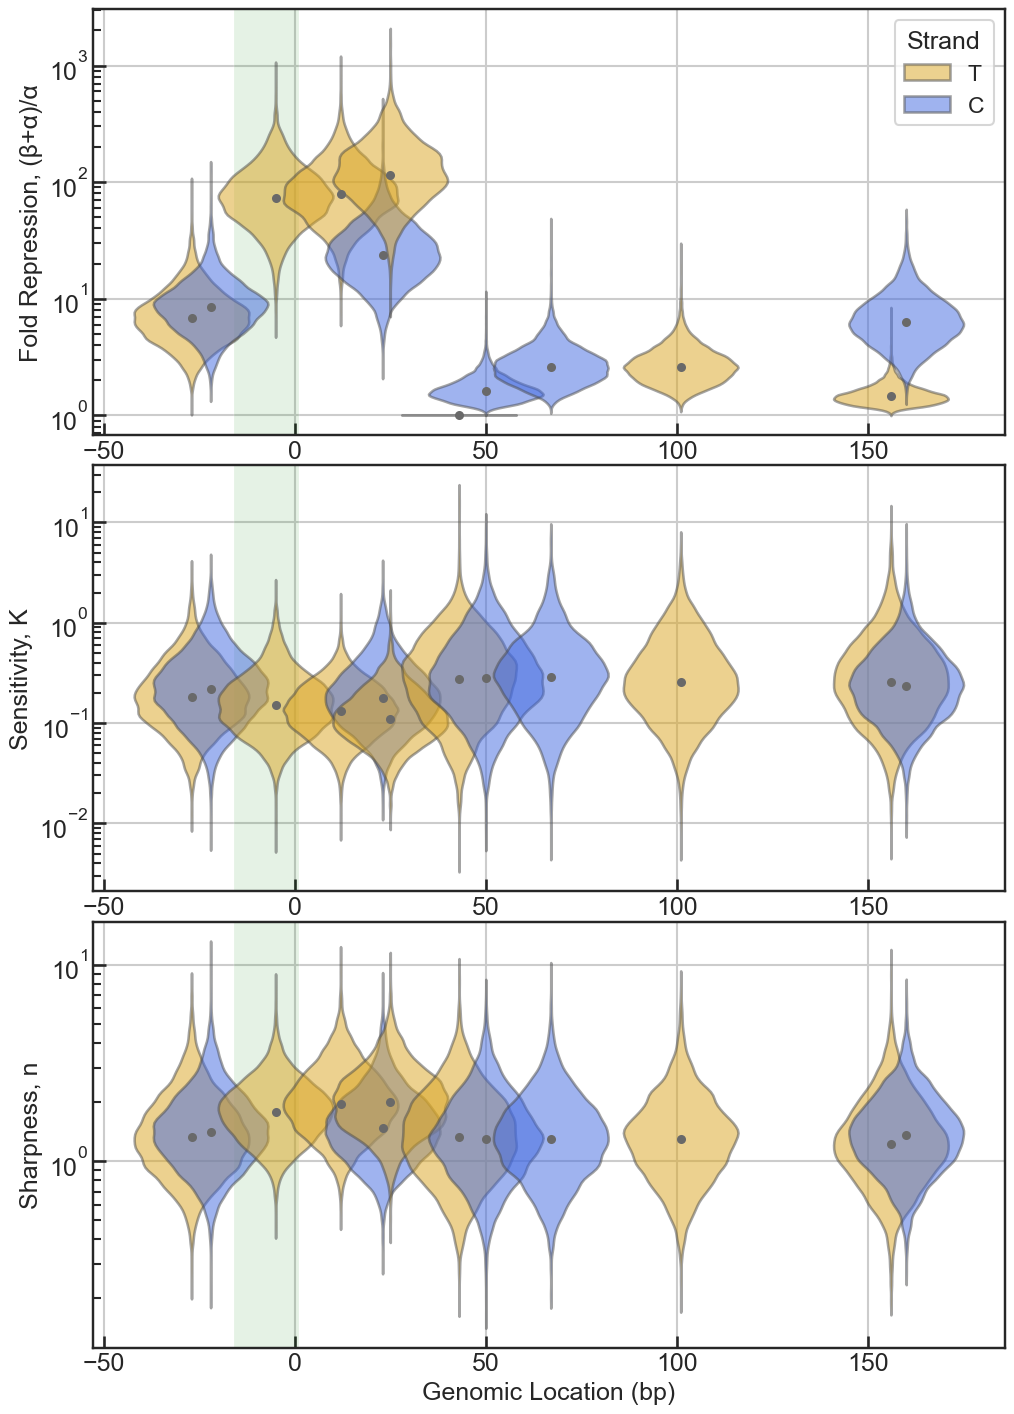

In [17]:
# Plot out fold change, K, and n for M9

fig = plt.figure(figsize=(10,14))
ax1 = fig.add_subplot(3, 1, 1)
ax2 = fig.add_subplot(3, 1, 2)
ax3 = fig.add_subplot(3, 1, 3)

# Plot T7 promoter window
ax1.axvspan(-16,1, facecolor='g', alpha=0.1)
ax2.axvspan(-16,1, facecolor='g', alpha=0.1)
ax3.axvspan(-16,1, facecolor='g', alpha=0.1)

sns.violinplot(data=df[df.Media == 'M9'],
               x='Location', y='Fold Repression', hue='Orientation',
               palette=['goldenrod','royalblue'],
               native_scale=True, ax=ax1,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw,
               saturation=1,
               alpha=0.5,
               legend='brief',
               scale='width',
              )
sns.violinplot(data=df[df.Media == 'M9'],
               x='Location', y='K', hue='Orientation',
               palette=['goldenrod','royalblue'],
               # palette=['navajowhite','lavender'],
               native_scale=True, ax=ax2,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
              )
sns.violinplot(data=df[df.Media == 'M9'],
               x='Location', y='n', hue='Orientation',
               palette=['goldenrod','royalblue'],
               # palette=['navajowhite','lavender'],
               native_scale=True, ax=ax3,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
               # inner_kws=dict(linestyle='-',linewidth=vw,
              )

# plot medians
m9_medians = df[df.Media=='M9'].groupby('Location')['Fold Repression'].median()
cl_medians = df[df.Media=='M9'].groupby('Location')['K'].median()
delta_medians = df[df.Media=='M9'].groupby('Location')['n'].median()
ax1.scatter(np.array(m9_medians.index), np.array(m9_medians), c='dimgrey')
ax2.scatter(np.array(cl_medians.index), np.array(cl_medians), c='dimgrey')
ax3.scatter(np.array(delta_medians.index), np.array(delta_medians), c='dimgrey')

handles, labels = ax1.get_legend_handles_labels()
ax1.legend(title='Strand', handles=handles, labels=['T','C'])

# ax1.axhline(1, c='k', linestyle='-', alpha=0.5)
# ax2.axhline(1, c='k', linestyle='-', alpha=0.5)
# ax3.axhline(1, c='k', linestyle='-', alpha=0.5)
ax1.set_ylabel('Fold Repression, (β+α)/α')
ax2.set_ylabel('Sensitivity, K')
ax3.set_ylabel('Sharpness, n')
ax1.set_xlabel('')
ax2.set_xlabel('')
ax3.set_xlabel('Genomic Location (bp)')
# ax3.legend(loc='lower right', title='Orientation', fontsize=12, title_fontsize=12)
ax1.grid()
ax2.grid()
ax3.grid()
plt.tight_layout(pad=0.1)
plt.savefig('./figs/20251204_D_M9.pdf')
plt.show()

Let's look into whether the Hill coefficient $n$ is actually 'consistent across gates'. How would you test this? Just do a bunch of statistical tests? Or just state the median values?

In [18]:
n_medians_m9 = np.array(df[df.Media=='M9'].groupby('Location')['n'].median())
n_medians_cl = np.array(df[df.Media=='CL'].groupby('Location')['n'].median())

print(n_medians_m9)
print(min(n_medians_m9))
print(max(n_medians_m9))
print(n_medians_cl)
print(min(n_medians_cl))
print(max(n_medians_cl))

[1.32597538 1.40092284 1.78799758 1.95261014 1.4725828  2.00630727
 1.32971867 1.30275096 1.30036325 1.29922527 1.22090094 1.35496679]
1.2209009381999711
2.006307271542033
[1.277054   1.21380822 1.24303181 1.33425325 1.33452254 1.30347948
 1.23857612 1.20723448 1.28575712 1.28949681 1.25247577 1.29923731]
1.2072344758320859
1.334522544820795


Let's do this again but look at the per-gate shift.

In [19]:
n_medians_delta = n_medians_m9/n_medians_cl
n_medians_delta

array([1.03830799, 1.15415501, 1.43841659, 1.46344791, 1.10345292,
       1.5391936 , 1.07358655, 1.07912007, 1.01135995, 1.00754438,
       0.97479007, 1.04289399])

Let's also look at the range across which $K$ values span.

In [28]:
K_medians_m9 = np.array(df[df.Media=='M9'].groupby('Location')['K'].median())
K_medians_cl = np.array(df[df.Media=='CL'].groupby('Location')['K'].median())

print(K_medians_m9)
print(max(K_medians_m9)/min(K_medians_m9))
print()
print(K_medians_cl)
print(max(K_medians_cl)/min(K_medians_cl))
print()
print(stats.gmean(K_medians_m9[:6]), stats.gmean(K_medians_m9[6:]))

[0.18214715 0.21788721 0.15066248 0.13200893 0.177614   0.11079983
 0.27719196 0.2782191  0.2866199  0.25579138 0.25892541 0.23310865]
2.586826094328692

[0.2681266  0.28067377 0.25174612 0.28490749 0.24786609 0.23846287
 0.29541286 0.23814632 0.31174499 0.29637934 0.28529568 0.22592654]
1.3798511157927535

0.15795976219826685 0.2643517225045665


Once again let's look at the per-gate shift

In [21]:
K_medians_delta = K_medians_m9/K_medians_cl
1/np.mean(K_medians_delta)

1.259569536753309

Let's make a plot that plots the shifts in parameter values due to growth arrest on a single plot.

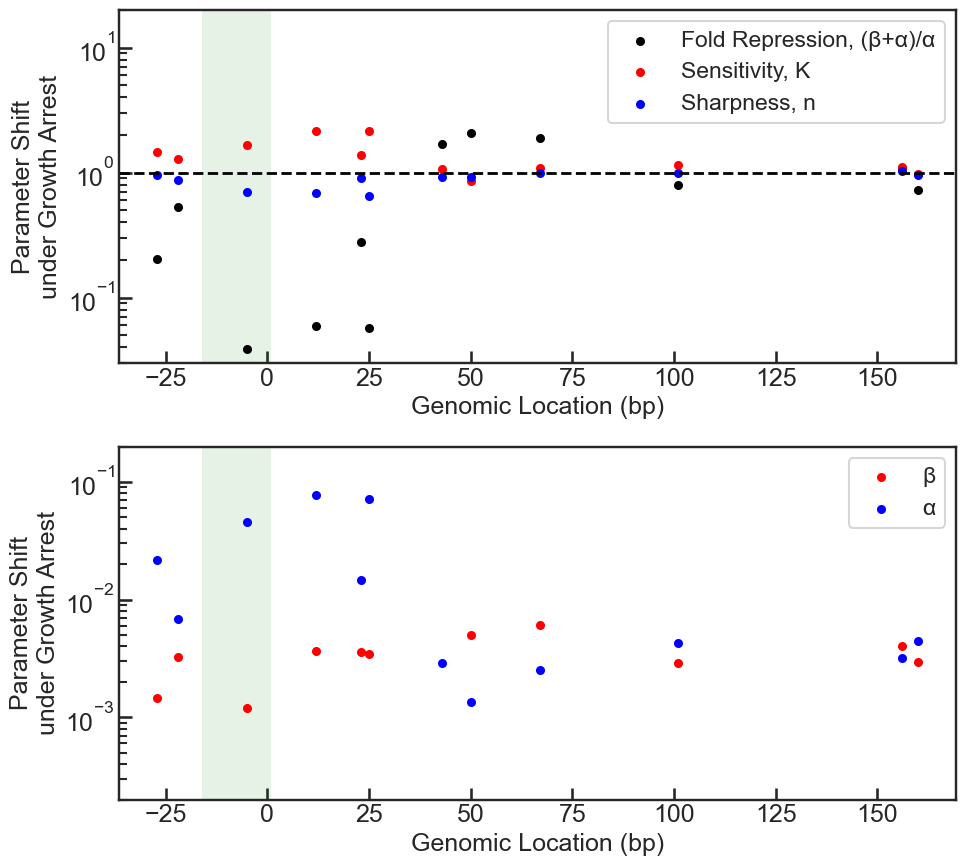

In [42]:
m9_FCs = df[df.Media=='M9'].groupby('Location')['Fold Repression'].median()
m9_betas = df[df.Media=='M9'].groupby('Location')['Beta'].median()
m9_alphas = df[df.Media=='M9'].groupby('Location')['Alpha'].median()
m9_Ks = df[df.Media=='M9'].groupby('Location')['K'].median()
m9_ns = df[df.Media=='M9'].groupby('Location')['n'].median()
cl_FCs = df[df.Media=='CL'].groupby('Location')['Fold Repression'].median()
cl_betas = df[df.Media=='CL'].groupby('Location')['Beta'].median()
cl_alphas = df[df.Media=='CL'].groupby('Location')['Alpha'].median()
cl_Ks = df[df.Media=='CL'].groupby('Location')['K'].median()
cl_ns = df[df.Media=='CL'].groupby('Location')['n'].median()

# calculate delta directly as ratio of medians
delta_FCs = cl_FCs/m9_FCs
delta_Ks = cl_Ks/m9_Ks
delta_ns = cl_ns/m9_ns
delta_betas = cl_betas/m9_betas
delta_alphas = cl_alphas/m9_alphas

fig, ax = plt.subplots(2, 1, figsize=(10,9))
ax[0].axvspan(-16,1, facecolor='g', alpha=0.1)
ax[0].axhline(1, c='k', linestyle='--', lw=2)
ax[0].scatter(np.array(delta_FCs.index), np.array(delta_FCs), label='Fold Repression, (β+α)/α', c='k')
ax[0].scatter(np.array(delta_Ks.index), np.array(delta_Ks), label='Sensitivity, K', c='r')
ax[0].scatter(np.array(delta_ns.index), np.array(delta_ns), label='Sharpness, n', c='b')
ax[0].set_yscale('log')
ax[0].set_ylim((3e-2,2e1))
ax[0].legend()
ax[0].set_xlabel('Genomic Location (bp)')
ax[0].set_ylabel('Parameter Shift\nunder Growth Arrest')

ax[1].axvspan(-16,1, facecolor='g', alpha=0.1)
ax[1].axhline(1, c='k', linestyle='--', lw=2)
ax[1].scatter(np.array(delta_betas.index), np.array(delta_betas), label='β', c='r')
ax[1].scatter(np.array(delta_alphas.index), np.array(delta_alphas), label='α', c='b')
ax[1].set_yscale('log')
ax[1].set_ylim((2e-4,2e-1))
ax[1].legend()
ax[1].set_xlabel('Genomic Location (bp)')
ax[1].set_ylabel('Parameter Shift\nunder Growth Arrest')
plt.tight_layout()
plt.savefig('./figs/param_shift_dCas9.pdf')
plt.show()



In [33]:
delta_Ks = np.array(delta_Ks)
delta_FCs = np.array(delta_FCs)
delta_ns = np.array(delta_ns)
delta_betas = np.array(delta_betas)
delta_alphas = np.array(delta_alphas)

# delete the gate that didn't repress
delta_Ks = np.delete(delta_Ks, 6)
# delta_FCs = np.delete(delta_FCs, 6) # you can calculate FC here so it's ok
delta_ns = np.delete(delta_ns, 6)
delta_betas = np.delete(delta_betas, 6)
delta_alphas = np.delete(delta_alphas, 6)


In [36]:

print(delta_Ks)
print(stats.gmean(delta_Ks[:6]))
print(1/stats.gmean(delta_Ks[6:]))
print(stats.gmean(delta_Ks))
print()
print(delta_FCs)
print(1/stats.gmean(delta_FCs[:6]))
print(stats.gmean(delta_FCs[6:]))
print()
print(delta_ns)
print(1/delta_ns)
print(1/stats.gmean(delta_ns))
print()
print(1/stats.gmean(delta_betas))
print(1/stats.gmean(delta_alphas))

[1.47203297 1.28816086 1.67092777 2.15824398 1.39553238 2.15219524
 0.85596684 1.08765996 1.15867604 1.10184506 0.96918987]
1.654859927691936
0.9721016952051552
1.333244814573456

[0.20243918 0.53420595 0.03912434 0.05940327 0.27786102 0.05686473
 1.70258822 2.06961546 1.89014237 0.79295548 1.08355224 0.72112091]
7.946540975442351
1.266485121724365

[0.96310536 0.86643474 0.69520889 0.6833178  0.90624618 0.64969085
 0.92668094 0.98876765 0.99251211 1.02586191 0.95887023]
[1.03830799 1.15415501 1.43841659 1.46344791 1.10345292 1.5391936
 1.07912007 1.01135995 1.00754438 0.97479007 1.04289399]
1.1530405331794134

320.9024028988177
98.72700163083653


In [39]:
print(1/delta_betas)
print(1/delta_alphas)

[688.2391349  309.19728002 825.71712578 275.76284692 280.70117423
 291.53204221 201.06939301 163.73107453 342.94784998 245.63423996
 337.93719307]
[ 45.83619087 145.81409054  21.81986577  12.9222668   67.88610528
  14.08800479 738.65907821 395.50155564 233.98966167 311.91140773
 226.01959082]


In [35]:
print(np.array(m9_FCs))
print(np.array(cl_FCs))

[  6.78363583   8.47205616  73.48024189  78.38763374  23.69570536
 116.18438563   1.           1.61746158   2.60966122   2.60425741
   1.45369085   6.30980733]
[1.37327369 4.52582285 2.87486592 4.65648171 6.58411286 6.60679323
 1.70258822 3.3475235  4.93263124 2.06506018 1.57514998 4.550134  ]


In [333]:
print(np.median(df[df.Media=='M9']['K'].values))
print(np.median(df[df.Media=='CL']['K'].values))
print(np.median(df[df.Media=='CL']['K'].values)/np.median(df[df.Media=='M9']['K'].values))

0.19626826419816717
0.2661412464667795
1.356007541790166


In [334]:
print(np.median(df[df.Media=='M9']['Fold Repression'].values))
print(np.median(df[df.Media=='CL']['Fold Repression'].values))
print(np.median(df[df.Media=='CL']['Fold Repression'].values)/np.median(df[df.Media=='M9']['Fold Repression'].values))

5.824227914529141
3.257604200365746
0.5593194923295007


In [336]:
print(np.median(df[df.Media=='M9']['n'].values))
print(np.median(df[df.Media=='CL']['n'].values))
print(np.median(df[df.Media=='M9']['n'].values)/np.median(df[df.Media=='CL']['n'].values))

1.4728633323995703
1.2730412717687951
1.156964322415987


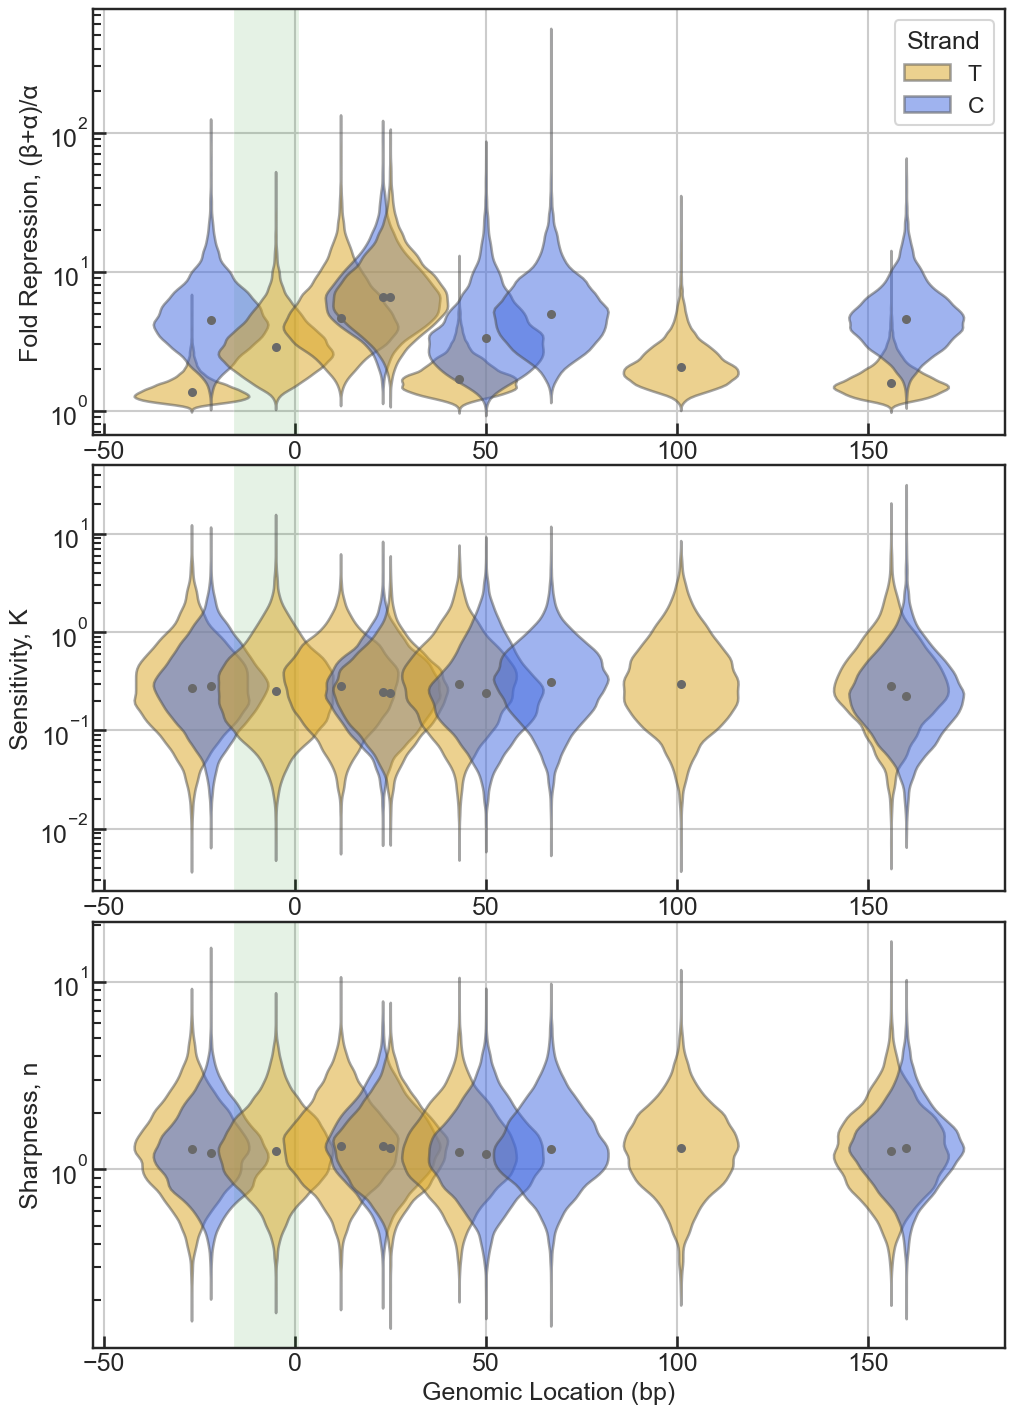

In [337]:
# Plot out fold change, K, and n for CL

fig = plt.figure(figsize=(10,14))
ax1 = fig.add_subplot(3, 1, 1)
ax2 = fig.add_subplot(3, 1, 2)
ax3 = fig.add_subplot(3, 1, 3)

# Plot T7 promoter window
ax1.axvspan(-16,1, facecolor='g', alpha=0.1)
ax2.axvspan(-16,1, facecolor='g', alpha=0.1)
ax3.axvspan(-16,1, facecolor='g', alpha=0.1)

sns.violinplot(data=df[df.Media == 'CL'],
               x='Location', y='Fold Repression', hue='Orientation',
               palette=['goldenrod','royalblue'],
               native_scale=True, ax=ax1,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw,
               saturation=1,
               alpha=0.5,
               legend='brief',
               scale='width',
              )
sns.violinplot(data=df[df.Media == 'CL'],
               x='Location', y='K', hue='Orientation',
               palette=['goldenrod','royalblue'],
               # palette=['navajowhite','lavender'],
               native_scale=True, ax=ax2,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
              )
sns.violinplot(data=df[df.Media == 'CL'],
               x='Location', y='n', hue='Orientation',
               palette=['goldenrod','royalblue'],
               # palette=['navajowhite','lavender'],
               native_scale=True, ax=ax3,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
               # inner_kws=dict(linestyle='-',linewidth=vw,
              )

# plot medians
m9_medians = df[df.Media=='CL'].groupby('Location')['Fold Repression'].median()
cl_medians = df[df.Media=='CL'].groupby('Location')['K'].median()
delta_medians = df[df.Media=='CL'].groupby('Location')['n'].median()
ax1.scatter(np.array(m9_medians.index), np.array(m9_medians), c='dimgrey')
ax2.scatter(np.array(cl_medians.index), np.array(cl_medians), c='dimgrey')
ax3.scatter(np.array(delta_medians.index), np.array(delta_medians), c='dimgrey')

handles, labels = ax1.get_legend_handles_labels()
ax1.legend(title='Strand', handles=handles, labels=['T','C'])

# ax1.axhline(1, c='k', linestyle='-', alpha=0.5)
# ax2.axhline(1, c='k', linestyle='-', alpha=0.5)
# ax3.axhline(1, c='k', linestyle='-', alpha=0.5)
ax1.set_ylabel('Fold Repression, (β+α)/α')
ax2.set_ylabel('Sensitivity, K')
ax3.set_ylabel('Sharpness, n')
ax1.set_xlabel('')
ax2.set_xlabel('')
ax3.set_xlabel('Genomic Location (bp)')
# ax3.legend(loc='lower right', title='Orientation', fontsize=12, title_fontsize=12)
ax1.grid()
ax2.grid()
ax3.grid()
plt.tight_layout(pad=0.1)
plt.savefig('./figs/20251204_D_CL.pdf')
plt.show()

In [338]:
FR_medians_m9 = np.array(df[df.Media=='M9'].groupby('Location')['Fold Repression'].median())
FR_medians_cl = np.array(df[df.Media=='CL'].groupby('Location')['Fold Repression'].median())

print(FR_medians_m9)
print(FR_medians_cl)

[  6.78363583   8.47205616  73.48024189  78.38763374  23.69570536
 116.18438563   1.           1.61746158   2.60966122   2.60425741
   1.45369085   6.30980733]
[1.37327369 4.52582285 2.87486592 4.65648171 6.58411286 6.60679323
 1.70258822 3.3475235  4.93263124 2.06506018 1.57514998 4.550134  ]


In [339]:
np.median(df[(df.Media=='CL') & (df.Location==25)]['Fold Repression'].values)

6.606793229679424

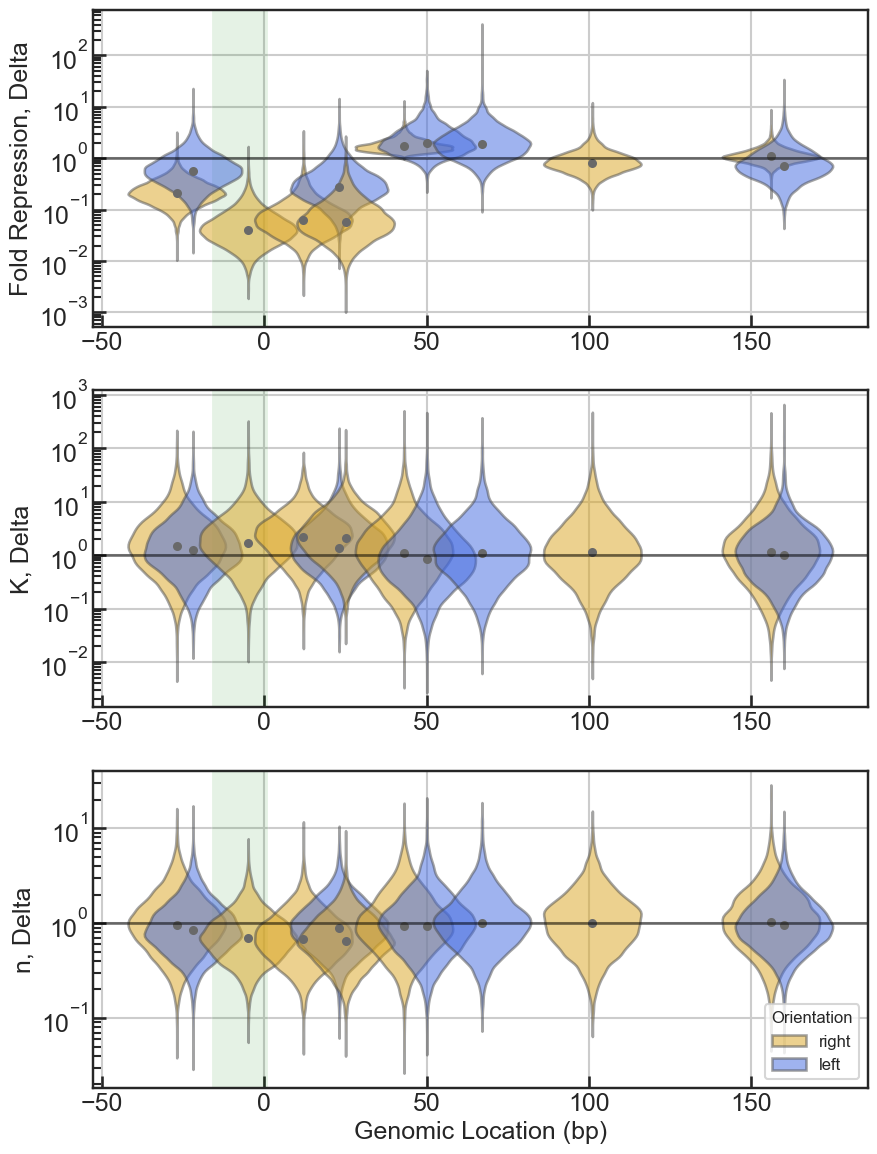

In [340]:
# Plot out fold change, K, and n for Delta

fig = plt.figure(figsize=(10,14))
ax1 = fig.add_subplot(3, 1, 1)
ax2 = fig.add_subplot(3, 1, 2)
ax3 = fig.add_subplot(3, 1, 3)
# Plot T7 promoter window
ax1.axvspan(-16,1, facecolor='g', alpha=0.1)
ax2.axvspan(-16,1, facecolor='g', alpha=0.1)
ax3.axvspan(-16,1, facecolor='g', alpha=0.1)

sns.violinplot(data=df[df.Media == 'Delta'],
               x='Location', y='Fold Repression', hue='Orientation',
               palette=['goldenrod','royalblue'],
               native_scale=True, ax=ax1,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
              )
sns.violinplot(data=df[df.Media == 'Delta'],
               x='Location', y='K', hue='Orientation',
               palette=['goldenrod','royalblue'],
               # palette=['navajowhite','lavender'],
               native_scale=True, ax=ax2,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
              )
sns.violinplot(data=df[df.Media == 'Delta'],
               x='Location', y='n', hue='Orientation',
               palette=['goldenrod','royalblue'],
               # palette=['navajowhite','lavender'],
               native_scale=True, ax=ax3,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw,
               saturation=1,
               alpha=0.5,
               legend='brief',
               scale='width',
               # inner_kws=dict(linestyle='-',linewidth=vw,
              )
# plot medians
m9_medians = df[df.Media=='Delta'].groupby('Location')['Fold Repression'].median()
cl_medians = df[df.Media=='Delta'].groupby('Location')['K'].median()
delta_medians = df[df.Media=='Delta'].groupby('Location')['n'].median()
ax1.scatter(np.array(m9_medians.index), np.array(m9_medians), c='dimgrey')
ax2.scatter(np.array(cl_medians.index), np.array(cl_medians), c='dimgrey')
ax3.scatter(np.array(delta_medians.index), np.array(delta_medians), c='dimgrey')


ax1.axhline(1, c='k', linestyle='-', alpha=0.5)
ax2.axhline(1, c='k', linestyle='-', alpha=0.5)
ax3.axhline(1, c='k', linestyle='-', alpha=0.5)
ax1.set_ylabel('Fold Repression, Delta')
ax2.set_ylabel('K, Delta')
ax3.set_ylabel('n, Delta')
ax1.set_xlabel('')
ax2.set_xlabel('')
ax3.set_xlabel('Genomic Location (bp)')
ax3.legend(loc='lower right', title='Orientation', fontsize=12, title_fontsize=12)
ax1.grid()
ax2.grid()
ax3.grid()
plt.show()

### How to compute fold change?

Fold change is $\beta / \alpha + 1$ and I need to make sure things make sense if I just directly divide these parameters on a per-sample basis.

<Figure size 400x400 with 0 Axes>

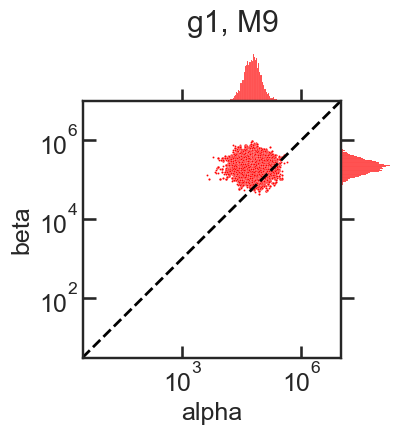

<Figure size 400x400 with 0 Axes>

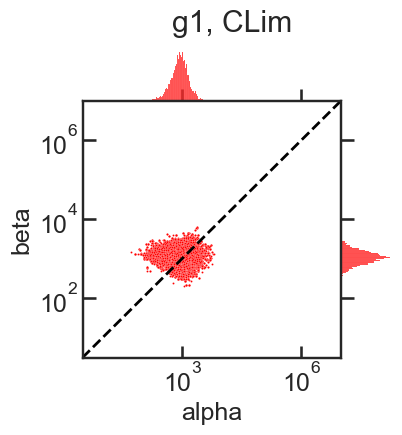

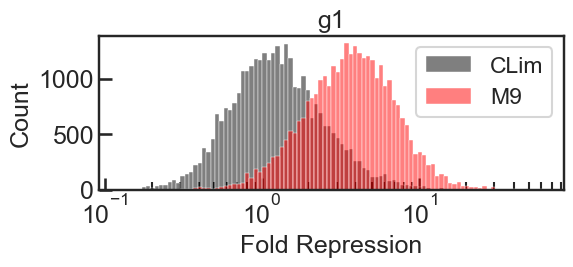

<Figure size 400x400 with 0 Axes>

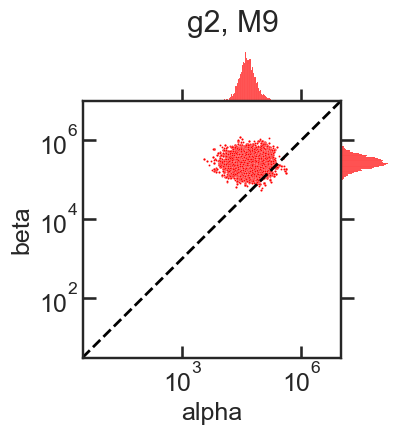

<Figure size 400x400 with 0 Axes>

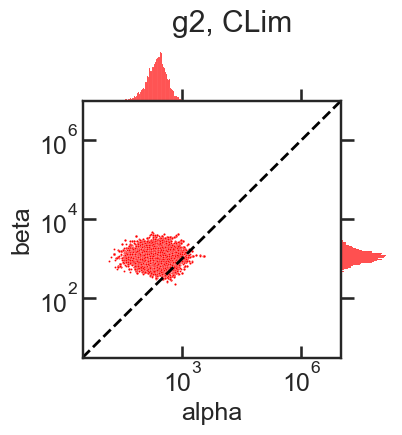

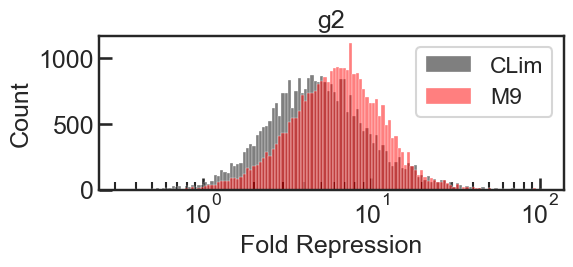

<Figure size 400x400 with 0 Axes>

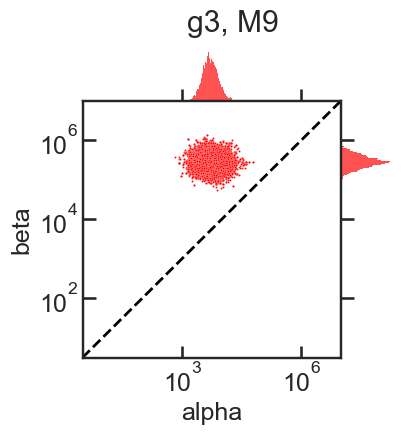

<Figure size 400x400 with 0 Axes>

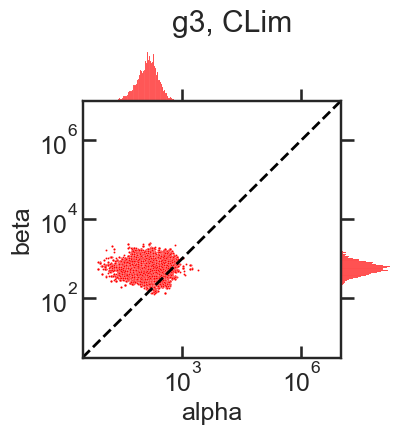

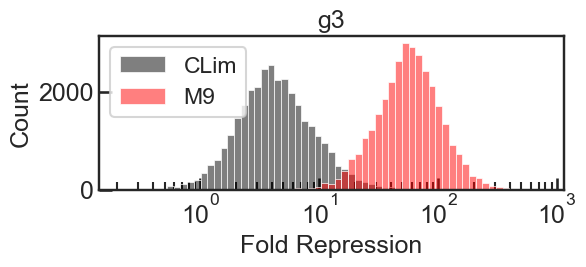

<Figure size 400x400 with 0 Axes>

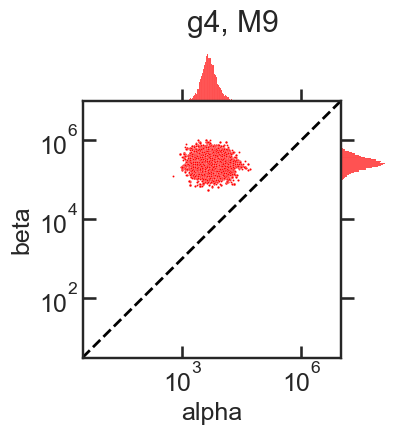

<Figure size 400x400 with 0 Axes>

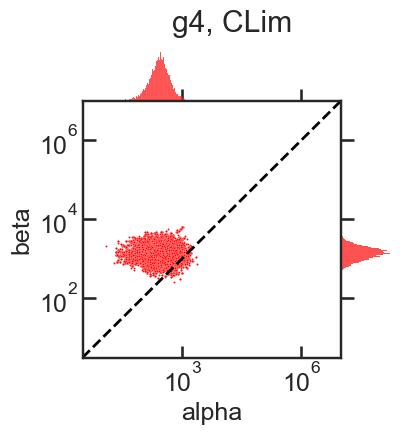

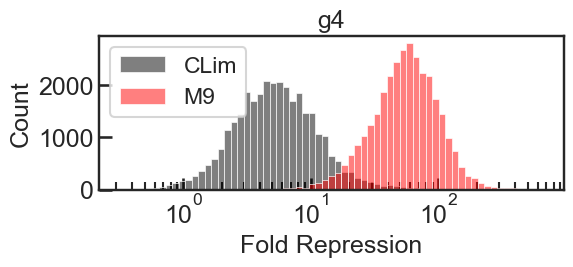

<Figure size 400x400 with 0 Axes>

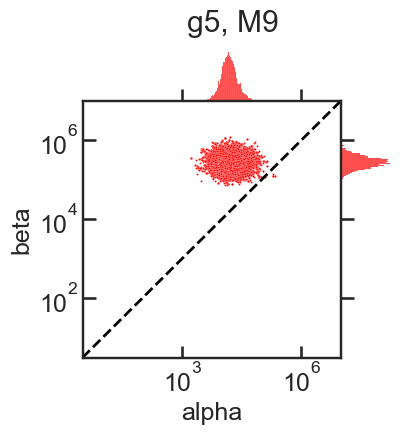

<Figure size 400x400 with 0 Axes>

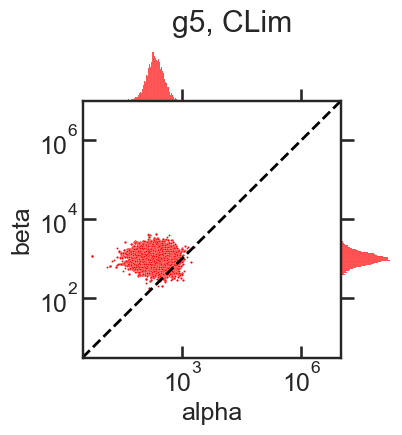

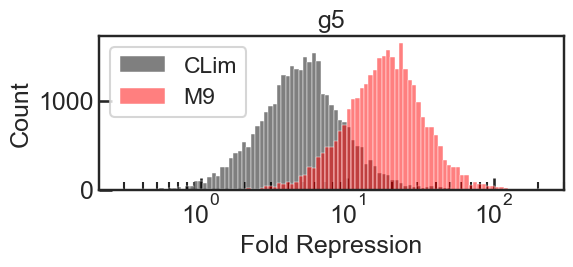

<Figure size 400x400 with 0 Axes>

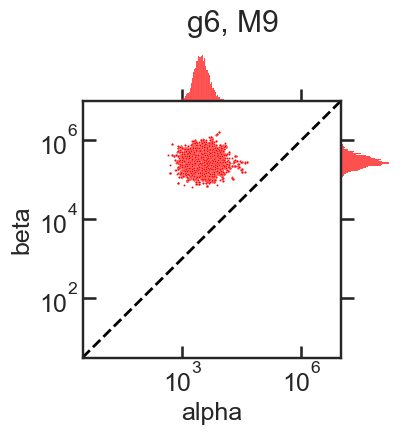

<Figure size 400x400 with 0 Axes>

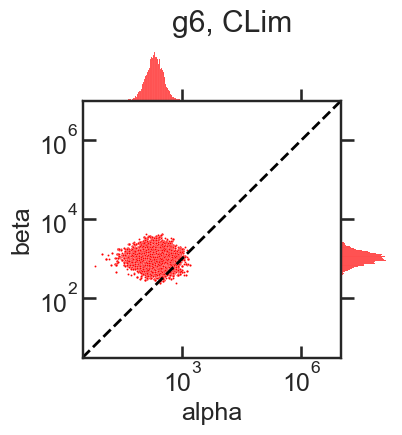

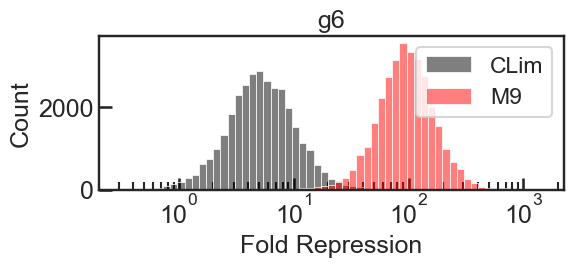

<Figure size 400x400 with 0 Axes>

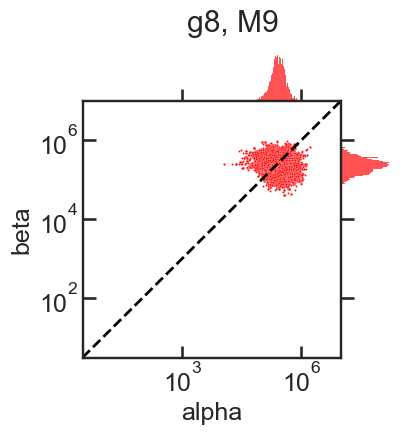

<Figure size 400x400 with 0 Axes>

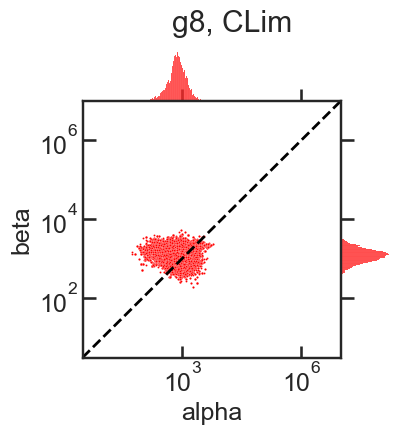

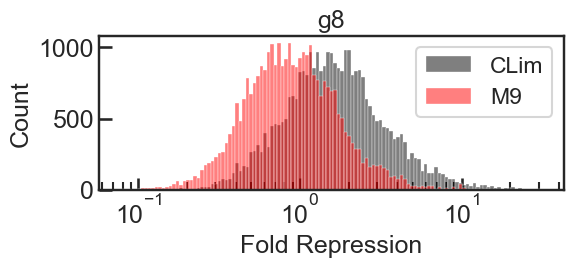

<Figure size 400x400 with 0 Axes>

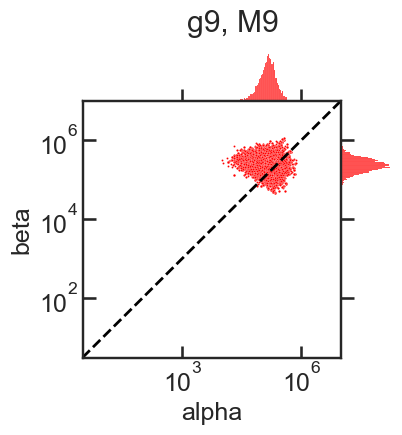

<Figure size 400x400 with 0 Axes>

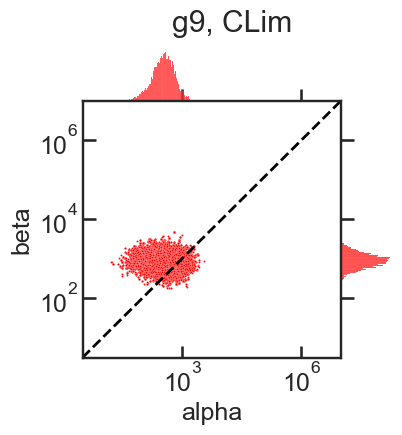

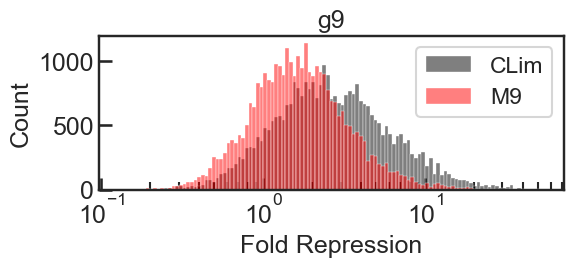

<Figure size 400x400 with 0 Axes>

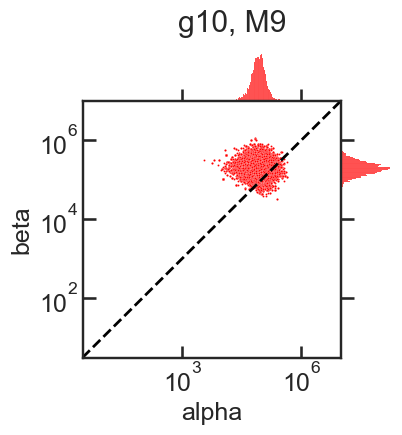

<Figure size 400x400 with 0 Axes>

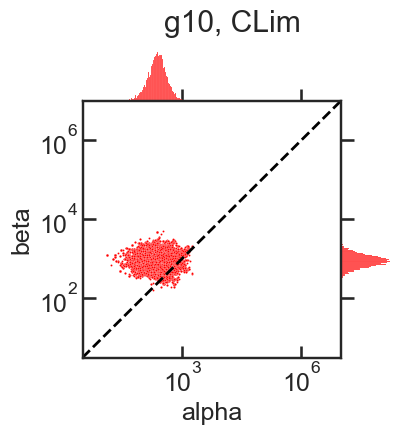

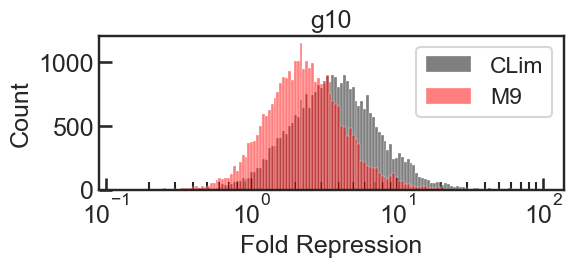

<Figure size 400x400 with 0 Axes>

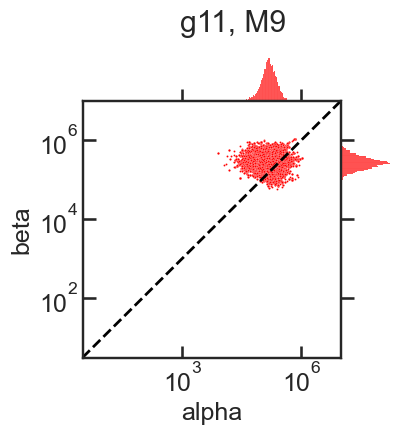

<Figure size 400x400 with 0 Axes>

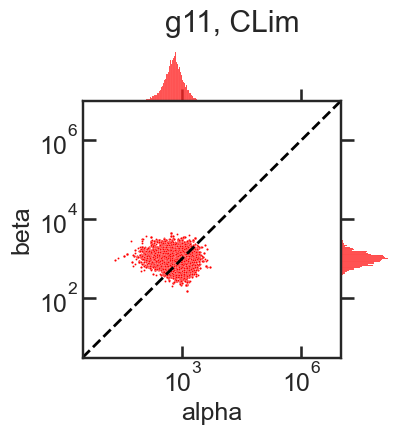

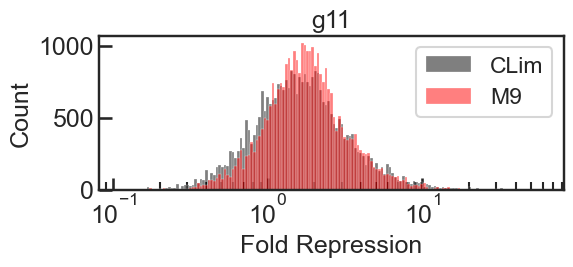

<Figure size 400x400 with 0 Axes>

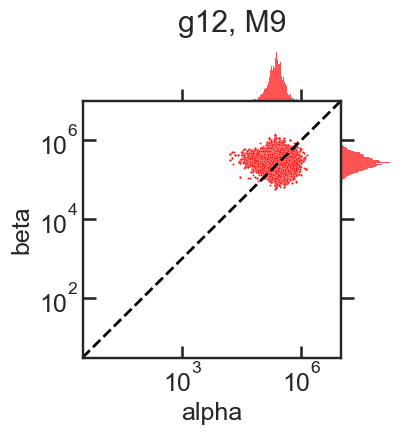

<Figure size 400x400 with 0 Axes>

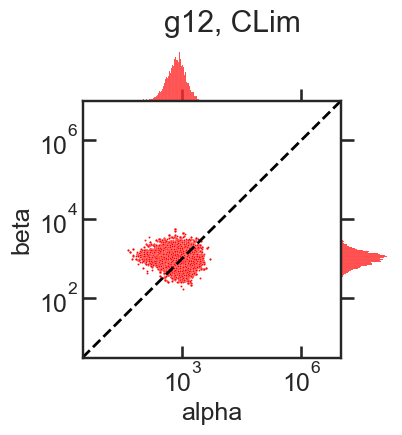

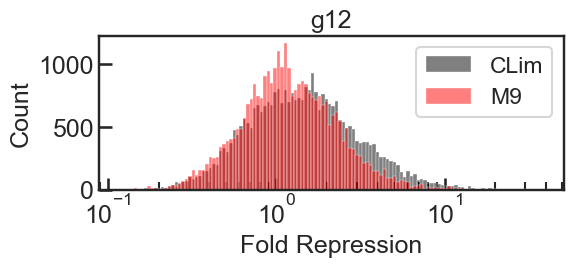

<Figure size 400x400 with 0 Axes>

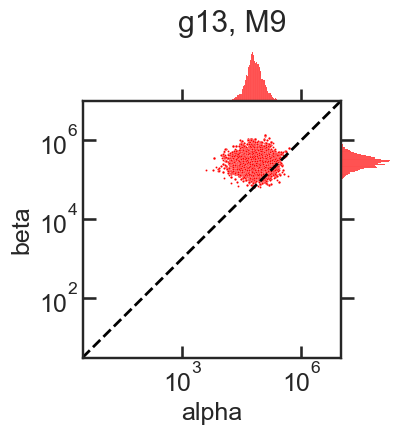

<Figure size 400x400 with 0 Axes>

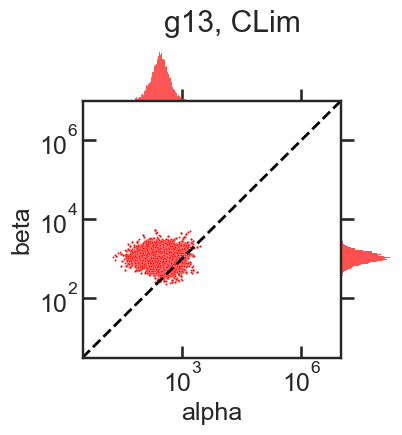

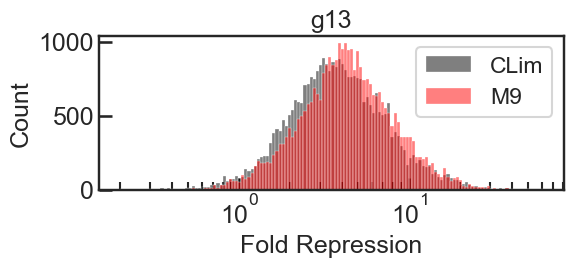

<Figure size 400x400 with 0 Axes>

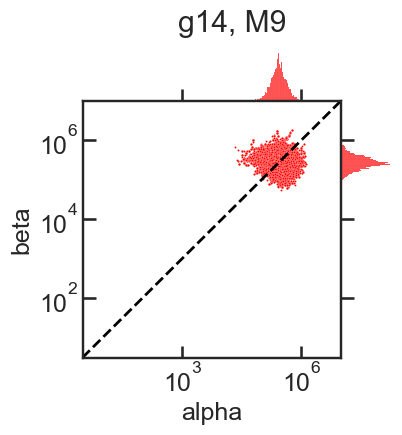

<Figure size 400x400 with 0 Axes>

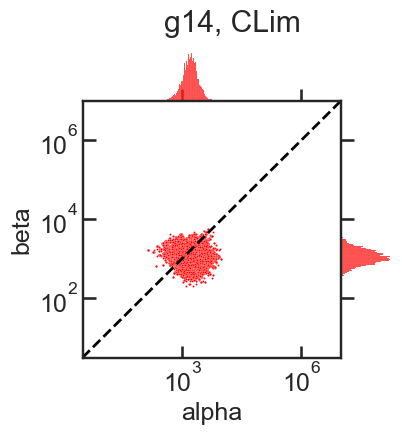

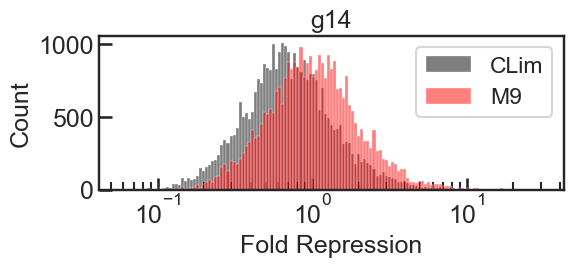

In [131]:
for grna in grnas:
    fold_rep_ls = []
    for m in range(len(medias)):
        media = medias[m]

        dfslice = df_medians[(df_medians['gRNA'] == grna) &
                             (df_medians['Media'] == media)]
        
        filename = './MCMC_outputs/'+grna+'_'+media+'_32_10000.pkl'

        with open(filename, 'rb') as f:
            sampler = pickle.load(f)
        f.close()

        flat_samples = sampler.get_chain(discard=9000, flat=True)

        plt.figure(figsize=(4,4))
        g = sns.jointplot(x=flat_samples[:,1], # alpha
                      y=flat_samples[:,0], # beta
                      space=0,
                      height=4,
                      xlim=((3e0,1e7)),
                      ylim=((3e0,1e7)),
                      joint_kws=dict(s=2,
                                    ),
                      marginal_kws=dict(log_scale=True,
                                       ),
                     )
        g.ax_joint.axline((3e0,3e0), (1e7,1e7), linestyle='--', color='k')
        plt.suptitle(grna +', '+media)
        plt.xlabel('alpha')
        plt.ylabel('beta')
        plt.show()

        fold_rep_ls.append(flat_samples[:,0]/flat_samples[:,1])

    fig, ax = plt.subplots(1,1, figsize=(6,2))
    sns.histplot(fold_rep_ls, log_scale=True)
    ax.legend(labels=['CLim','M9']) # <- for some reason the list elements are plotted in reverse order
    plt.xlabel('Fold Repression')
    plt.title(grna)
    plt.show()

OK, doing entry-wise division of the beta, alpha vectors seems like it gives consistent results.

Now let's make a plot showing the fold repression distribution grouped by genomic location for both M9 and CLim...

In [15]:
medias = ['M9', 'CLim']

data = []
for grna in grnas:
    if grna != 'g14':
        strand = strand_dict[grna]
        PAM = PAM_dict[grna]
        foldrep_ls = []
        betas_ls = []
        alphas_ls = []
        Ks_ls = []
        ns_ls = []
        for m in range(len(medias)):
            media = medias[m]
            
            filename = './MCMC_outputs/'+grna+'_'+media+'_32_10000.pkl'
            with open(filename, 'rb') as f:
                sampler = pickle.load(f)
            f.close()
            flat_samples = sampler.get_chain(discard=9000, flat=True)
            
            betas = flat_samples[:,0]
            alphas = flat_samples[:,1]
            Ks = flat_samples[:,2]
            ns = flat_samples[:,3]
            foldreps = betas/alphas + 1

            foldrep_ls.append(foldreps)
            betas_ls.append(betas)
            alphas_ls.append(alphas)
            Ks_ls.append(Ks)
            ns_ls.append(ns)
            
            for i in range(len(foldreps)):
                data.append([media, PAM, strand, foldreps[i],
                             betas[i], alphas[i],Ks[i], ns[i]])
        
        foldreps_delta = foldrep_ls[1]/foldrep_ls[0]
        betas_delta = betas_ls[1]/betas_ls[0]
        alphas_delta = alphas_ls[1]/alphas_ls[0]
        Ks_delta = Ks_ls[1]/Ks_ls[0]
        ns_delta = ns_ls[1]/ns_ls[0]
        for i in range(len(foldreps_delta)):
            data.append(['Delta', PAM, strand, foldreps_delta[i],
                         betas_delta[i], alphas_delta[i],
                         Ks_delta[i], ns_delta[i]])

df = pd.DataFrame(data, columns=['Media','Location','Orientation',
                                 'Fold Repression', 'Beta', 'Alpha',
                                 'K', 'n'])

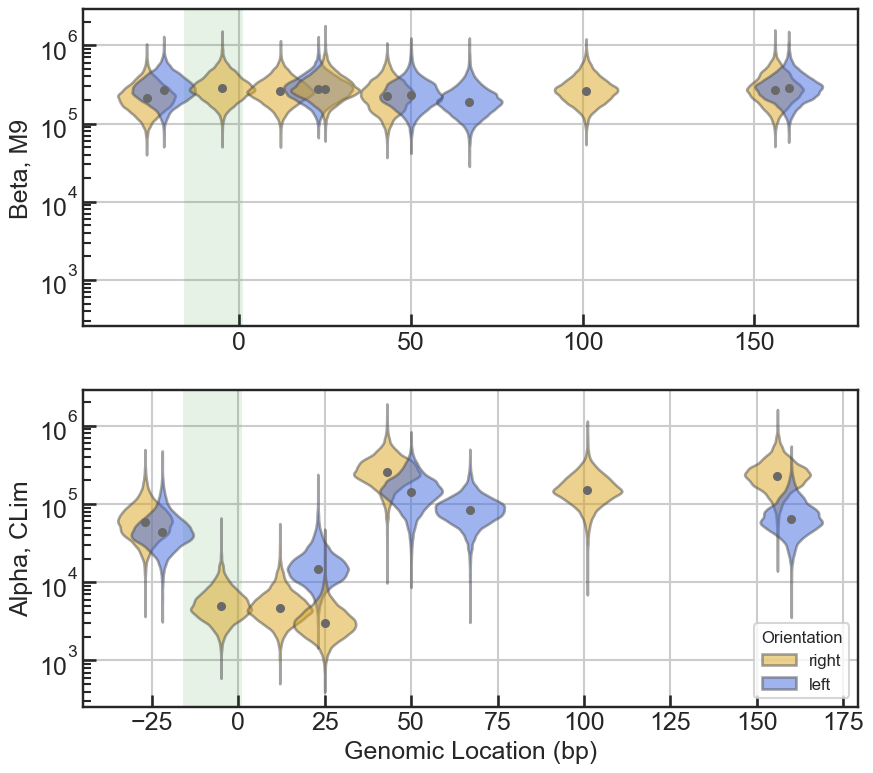

In [16]:
# Plot just M9 beta, alpha

fig = plt.figure(figsize=(10,14))
ax1 = fig.add_subplot(3,1,1)
ax2 = fig.add_subplot(3,1,2, sharey=ax1)
# Plot T7 promoter window
ax1.axvspan(-16,1, facecolor='g', alpha=0.1)
ax2.axvspan(-16,1, facecolor='g', alpha=0.1)

sns.violinplot(data=df[df.Media == 'M9'],
               x='Location', y='Beta', hue='Orientation',
               palette=['goldenrod','royalblue'],
               native_scale=True, ax=ax1,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=10,
               saturation=1,
               alpha=0.5,
               legend=False,
              )

sns.violinplot(data=df[df.Media == 'M9'],
               x='Location', y='Alpha', hue='Orientation',
               palette=['goldenrod','royalblue'],
               native_scale=True, ax=ax2,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=10,
               saturation=1,
               alpha=0.5,
               legend=True,
              )

# plot medians
beta_medians = df[df.Media=='M9'].groupby('Location')['Beta'].median()
alpha_medians = df[df.Media=='M9'].groupby('Location')['Alpha'].median()
ax1.scatter(np.array(beta_medians.index), np.array(beta_medians), c='dimgrey')
ax2.scatter(np.array(alpha_medians.index), np.array(alpha_medians), c='dimgrey')


ax1.set_ylabel('Beta, M9')
ax2.set_ylabel('Alpha, CLim')
ax1.set_xlabel('')
ax2.set_xlabel('Genomic Location (bp)')
ax2.legend(loc='lower right', title='Orientation', fontsize=12, title_fontsize=12)
ax1.grid()
ax2.grid()
plt.show()

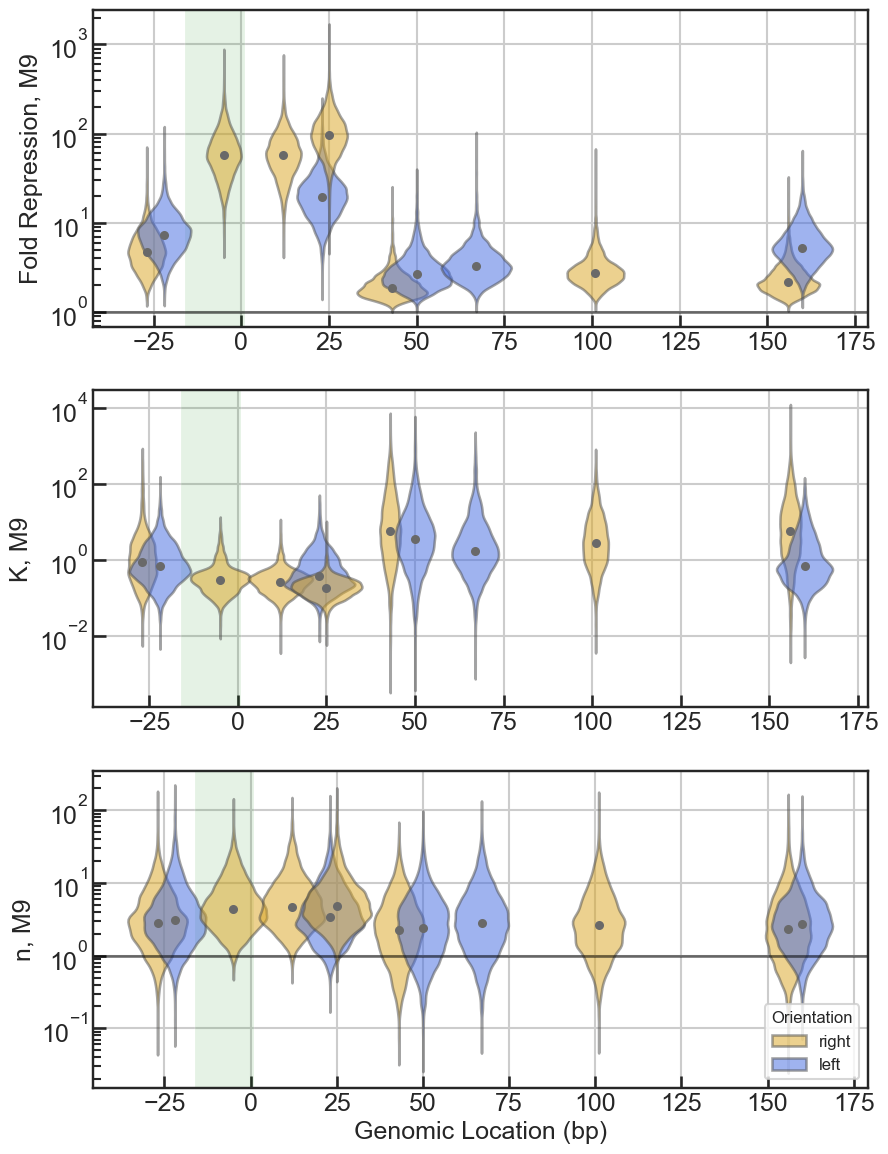

In [17]:
# Plot out fold change, K, and n for M9

fig = plt.figure(figsize=(10,14))
ax1 = fig.add_subplot(3, 1, 1)
ax2 = fig.add_subplot(3, 1, 2)
ax3 = fig.add_subplot(3, 1, 3)
# Plot T7 promoter window
ax1.axvspan(-16,1, facecolor='g', alpha=0.1)
ax2.axvspan(-16,1, facecolor='g', alpha=0.1)
ax3.axvspan(-16,1, facecolor='g', alpha=0.1)

sns.violinplot(data=df[df.Media == 'M9'],
               x='Location', y='Fold Repression', hue='Orientation',
               palette=['goldenrod','royalblue'],
               native_scale=True, ax=ax1,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=10,
               saturation=1,
               alpha=0.5,
               legend=False,
              )
sns.violinplot(data=df[df.Media == 'M9'],
               x='Location', y='K', hue='Orientation',
               palette=['goldenrod','royalblue'],
               # palette=['navajowhite','lavender'],
               native_scale=True, ax=ax2,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=10,
               saturation=1,
               alpha=0.5,
               legend=False,
              )
sns.violinplot(data=df[df.Media == 'M9'],
               x='Location', y='n', hue='Orientation',
               palette=['goldenrod','royalblue'],
               # palette=['navajowhite','lavender'],
               native_scale=True, ax=ax3,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=10,
               saturation=1,
               alpha=0.5,
               legend='brief',
               # inner_kws=dict(linestyle='-',linewidth=1),
              )
# plot medians
m9_medians = df[df.Media=='M9'].groupby('Location')['Fold Repression'].median()
cl_medians = df[df.Media=='M9'].groupby('Location')['K'].median()
delta_medians = df[df.Media=='M9'].groupby('Location')['n'].median()
ax1.scatter(np.array(m9_medians.index), np.array(m9_medians), c='dimgrey')
ax2.scatter(np.array(cl_medians.index), np.array(cl_medians), c='dimgrey')
ax3.scatter(np.array(delta_medians.index), np.array(delta_medians), c='dimgrey')


ax1.axhline(1, c='k', linestyle='-', alpha=0.5)
# ax2.axhline(1, c='k', linestyle='-', alpha=0.5)
ax3.axhline(1, c='k', linestyle='-', alpha=0.5)
ax1.set_ylabel('Fold Repression, M9')
ax2.set_ylabel('K, M9')
ax3.set_ylabel('n, M9')
ax1.set_xlabel('')
ax2.set_xlabel('')
ax3.set_xlabel('Genomic Location (bp)')
ax3.legend(loc='lower right', title='Orientation', fontsize=12, title_fontsize=12)
ax1.grid()
ax2.grid()
ax3.grid()
plt.show()

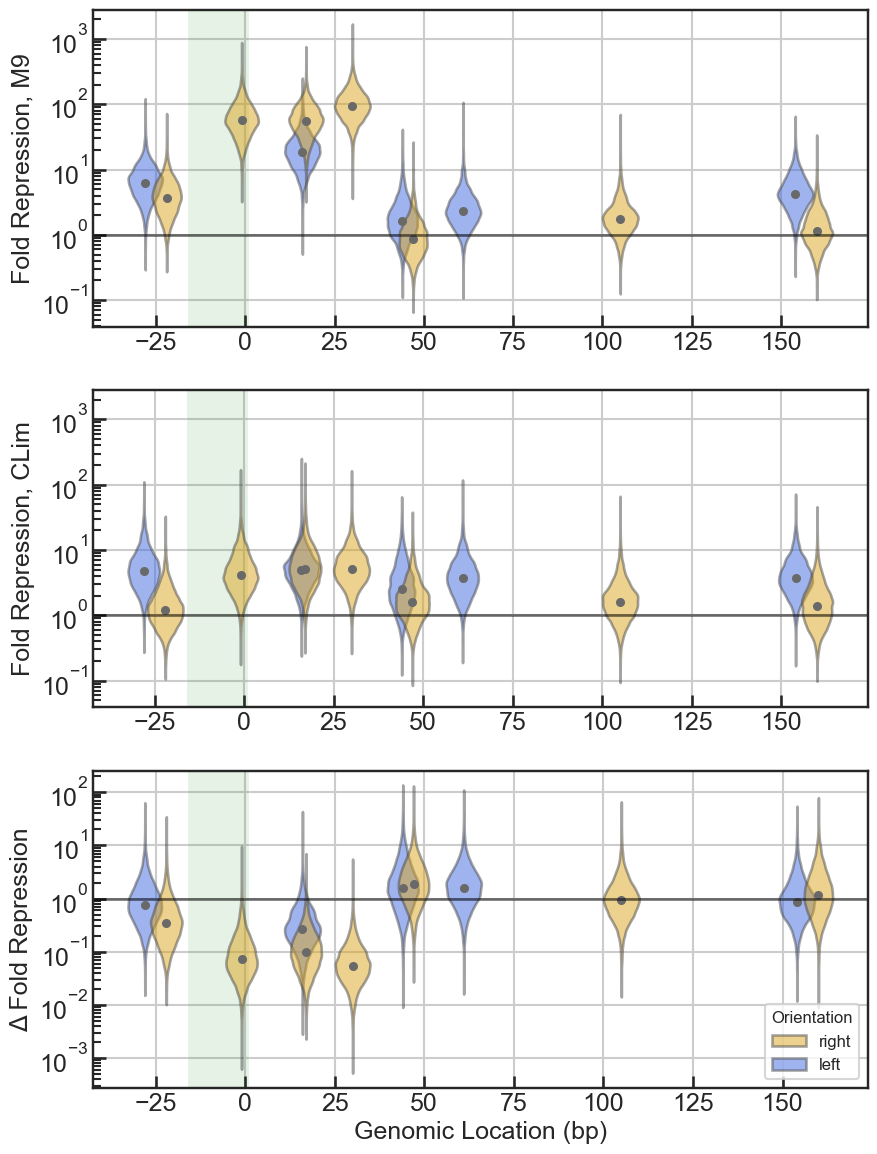

In [233]:
fig = plt.figure(figsize=(10,14))
ax1 = fig.add_subplot(3, 1, 1)
ax2 = fig.add_subplot(3, 1, 2, sharey=ax1)
ax3 = fig.add_subplot(3, 1, 3)
# Plot T7 promoter window
ax1.axvspan(-16,1, facecolor='g', alpha=0.1)
ax2.axvspan(-16,1, facecolor='g', alpha=0.1)
ax3.axvspan(-16,1, facecolor='g', alpha=0.1)

sns.violinplot(data=df[df.Media == 'M9'],
               x='Location', y='Fold Repression', hue='Orientation',
               palette=['goldenrod','royalblue'],
               native_scale=True, ax=ax1,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=10,
               saturation=1,
               alpha=0.5,
               legend=False,
              )
sns.violinplot(data=df[df.Media == 'CLim'],
               x='Location', y='Fold Repression', hue='Orientation',
               palette=['goldenrod','royalblue'],
               # palette=['navajowhite','lavender'],
               native_scale=True, ax=ax2,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=10,
               saturation=1,
               alpha=0.5,
               legend=False,
              )
sns.violinplot(data=df[df.Media == 'Delta'],
               x='Location', y='Fold Repression', hue='Orientation',
               palette=['goldenrod','royalblue'],
               # palette=['navajowhite','lavender'],
               native_scale=True, ax=ax3,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=10,
               saturation=1,
               alpha=0.5,
               legend='brief',
               # inner_kws=dict(linestyle='-',linewidth=1),
              )
# plot medians
m9_medians = df[df.Media=='M9'].groupby('Location')['Fold Repression'].median()
cl_medians = df[df.Media=='CLim'].groupby('Location')['Fold Repression'].median()
delta_medians = df[df.Media=='Delta'].groupby('Location')['Fold Repression'].median()
ax1.scatter(np.array(m9_medians.index), np.array(m9_medians), c='dimgrey')
ax2.scatter(np.array(cl_medians.index), np.array(cl_medians), c='dimgrey')
ax3.scatter(np.array(delta_medians.index), np.array(delta_medians), c='dimgrey')


ax1.axhline(1, c='k', linestyle='-', alpha=0.5)
ax2.axhline(1, c='k', linestyle='-', alpha=0.5)
ax3.axhline(1, c='k', linestyle='-', alpha=0.5)
ax1.set_ylabel('Fold Repression, M9')
ax2.set_ylabel('Fold Repression, CLim')
ax3.set_ylabel('Δ Fold Repression')
ax1.set_xlabel('')
ax2.set_xlabel('')
ax3.set_xlabel('Genomic Location (bp)')
ax3.legend(loc='lower right', title='Orientation', fontsize=12, title_fontsize=12)
ax1.grid()
ax2.grid()
ax3.grid()
plt.show()

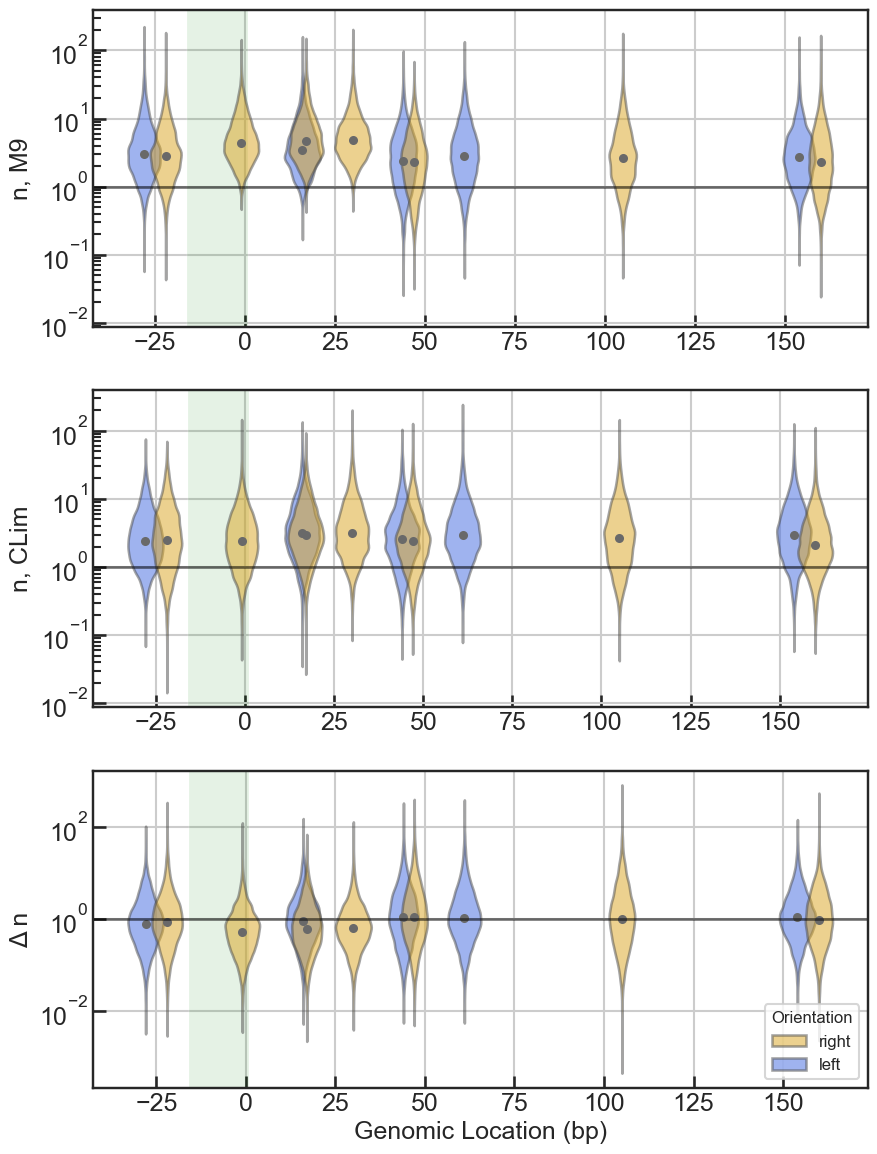

In [235]:
fig = plt.figure(figsize=(10,14))
ax1 = fig.add_subplot(3, 1, 1)
ax2 = fig.add_subplot(3, 1, 2, sharey=ax1)
ax3 = fig.add_subplot(3, 1, 3)
# Plot T7 promoter window
ax1.axvspan(-16,1, facecolor='g', alpha=0.1)
ax2.axvspan(-16,1, facecolor='g', alpha=0.1)
ax3.axvspan(-16,1, facecolor='g', alpha=0.1)

sns.violinplot(data=df[df.Media == 'M9'],
               x='Location', y='n', hue='Orientation',
               palette=['goldenrod','royalblue'],
               native_scale=True, ax=ax1,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=10,
               saturation=1,
               alpha=0.5,
               legend=False,
              )
sns.violinplot(data=df[df.Media == 'CLim'],
               x='Location', y='n', hue='Orientation',
               palette=['goldenrod','royalblue'],
               # palette=['navajowhite','lavender'],
               native_scale=True, ax=ax2,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=10,
               saturation=1,
               alpha=0.5,
               legend=False,
              )
sns.violinplot(data=df[df.Media == 'Delta'],
               x='Location', y='n', hue='Orientation',
               palette=['goldenrod','royalblue'],
               # palette=['navajowhite','lavender'],
               native_scale=True, ax=ax3,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=10,
               saturation=1,
               alpha=0.5,
               legend='brief',
               # inner_kws=dict(linestyle='-',linewidth=1),
              )
# plot medians
m9_medians = df[df.Media=='M9'].groupby('Location')['n'].median()
cl_medians = df[df.Media=='CLim'].groupby('Location')['n'].median()
delta_medians = df[df.Media=='Delta'].groupby('Location')['n'].median()
ax1.scatter(np.array(m9_medians.index), np.array(m9_medians), c='dimgrey')
ax2.scatter(np.array(cl_medians.index), np.array(cl_medians), c='dimgrey')
ax3.scatter(np.array(delta_medians.index), np.array(delta_medians), c='dimgrey')


ax1.axhline(1, c='k', linestyle='-', alpha=0.5)
ax2.axhline(1, c='k', linestyle='-', alpha=0.5)
ax3.axhline(1, c='k', linestyle='-', alpha=0.5)
ax1.set_ylabel('n, M9')
ax2.set_ylabel('n, CLim')
ax3.set_ylabel('Δ n')
ax1.set_xlabel('')
ax2.set_xlabel('')
ax3.set_xlabel('Genomic Location (bp)')
ax3.legend(loc='lower right', title='Orientation', fontsize=12, title_fontsize=12)
ax1.grid()
ax2.grid()
ax3.grid()
plt.show()

Some conclusions to draw from the above data:

- In both M9 and CLim, $\beta$ is very similar across gRNAs as expected, meaning that $\alpha$ drives the extent of fold repression.
- Absolute expression levels ($\beta$) drop ~100X between M9 and CLim, consistent with expectations.
- As a consequence, the repression curves move from a repression-limited regime in M9 to a leak-limited regime in CLim. This means that the CLim repression curves are much more homogeneous across binding positions than in M9.
- Both M9 and CLim repression curves have complicated relationships between repressor binding position and curve sensitivity $K$. However, $K$ tends to increase from M9 to CLim (i.e. the curve becomes less sensitive) for repressors that bind close to the promoter, while represosrs that bind far from the promoter tend to have similar $K$ levels between environments.
- Observed levels of $n$ did not vary much with repressor binding position, tending to hover around 2~3. $n$ values tended not to change much between environments. These results are consistent with $n$ being derived from properties of the repressor itself, which is consistent across medias and across binding locations.
- In general, the conclusion from all of the above is that repression curves were most similar when dCas9 was blocking transcriptional elongation downstream of the promoter.

Some of the above points should be analyzed more rigorously than looking by eye, but in general it seems like this is what we can say about the data.

The next question would be to see whether similar conclusions can be drawn from the dCas9:PhlF and PhlF repression data.

### GFP, RFP together

First we will find the geometric mean of the off-target gRNA's GFP values for all conditions

In [ ]:
g14_gmeans = np.empty((len(reps), len(medias)))

for i in range(len(reps)):
    for j in range(len(medias)):
        plot_inds = plot_inds_ls[i][j]
        atcs = atcs_ls[i][j]
    
        fcs_gated_dict = fcs_dict_ls[i]

        # # take the geometric mean of all points on the g14 induction course...
        # median_gfps_ls = []
        # for n in range(len(plot_inds)):
        #     fcs = fcs_gated_dict[medias[j]+'-'+'g14'+'-'+atcs[n+1]]
        #     gfps = np.array(fcs[:,5]) # FL5-A channel
        #     median_gfps_ls.append(np.median(gfps))
        # g14_gmeans[i,j] = np.exp(np.mean(np.log(median_gfps_ls))) # geometric mean

        # OR, just take the first IPTG-induced value (because CLim rep 1 weirdly goes upwards)
        fcs = fcs_gated_dict[medias[j]+'-'+'g14'+'-'+atcs[1]]
        gfps = np.array(fcs[:,5])
        g14_gmeans[i,j] = np.median(gfps)

First we will plot it without Hill function fit.

In [ ]:
for z in range(len(grnas)):
    fig, ax = plt.subplots(len(reps), len(medias), figsize=(9,9), sharey='col', sharex='col')
    for i in range(len(reps)):
        for j in range(len(medias)):
            plot_inds = plot_inds_ls[i][j]
            atcs = atcs_ls[i][j]
        
            plt.sca(ax[i,j])
            fcs_gated_dict = fcs_dict_ls[i]

            gfps_ls = []
            rfps_ls = []
            for n in range(len(plot_inds)):
                fcs = fcs_gated_dict[medias[j]+'-'+grnas[z]+'-'+atcs[n+1]]
                gfps = np.array(fcs[:,5])
                rfps = np.array(fcs[:,7])
                gfps_ls.append(np.median(gfps))
                rfps_ls.append(np.median(rfps))

            # Plot GFP/RFP repression curve
            ax[i,j].scatter(rfps_ls, gfps_ls, c='r')
            ax[i,j].plot(rfps_ls, gfps_ls, c='r', linewidth=2)

            # get 0 atc 0 iptg fluorescence level
            fcs0 = fcs_gated_dict[medias[j]+'-'+grnas[z]+'-'+'Blank']
            gfps0 = np.array(fcs0[:,5])
            rfps0 = np.array(fcs0[:,7])
            
            # Plot 0/0 condition
            ax[i,j].scatter(np.median(rfps0), np.median(gfps0), c='r', marker='*', s=100)
            ax[i,j].axhline(np.median(gfps0), c='g', linestyle='--')
            
            # nown plot the geometric mean of off-target guide's GFP value
            ax[i,j].axhline(g14_gmeans[i,j], c='g', linestyle='--')
            
            # Plotting params
            ax[i,j].set_xscale('symlog',linthresh=1e-2)
            ax[i,j].set_xlim((-3e-2,3e2))
            ax[i,j].axvspan(-3e-2,1e-2,facecolor='k',alpha=0.1) # linear region
            ax[i,j].set_yscale('log')
            ax[i,j].tick_params(labelbottom=True)
            ax[i,1].tick_params(labelleft=True)
            ax[i,j].set_xlabel('RFP')
            ax[i,j].set_ylabel('GFP')
            ax[i,j].set_title('Rep '+str(reps[i]) + ', '+medias[j])
                
            

    plt.suptitle('gRNA '+grnas[z])
    plt.tight_layout()
    
    plt.show()

Let's see what happens if we try to put all these curves on the same plot.

In [ ]:
for z in range(len(grnas)):
    fig, ax = plt.subplots(1, len(medias), figsize=(9,6))
    for j in range(len(medias)):
        for i in range(len(reps)):
            plot_inds = plot_inds_ls[i][j]
            atcs = atcs_ls[i][j]
        
            plt.sca(ax[j])
            fcs_gated_dict = fcs_dict_ls[i]

            gfps_ls = []
            rfps_ls = []
            for n in range(len(plot_inds)):
                fcs = fcs_gated_dict[medias[j]+'-'+grnas[z]+'-'+atcs[n+1]]
                gfps = np.array(fcs[:,5])
                rfps = np.array(fcs[:,7])
                gfps_ls.append(np.median(gfps))
                rfps_ls.append(np.median(rfps))

            # Plot GFP/RFP repression curve
            ax[j].scatter(rfps_ls, gfps_ls, c='r', alpha=0.5, zorder=10)
            ax[j].plot(rfps_ls, gfps_ls, c='r', linewidth=2, alpha=0.5, zorder=10)

            # get 0 atc 0 iptg fluorescence level
            fcs0 = fcs_gated_dict[medias[j]+'-'+grnas[z]+'-'+'Blank']
            gfps0 = np.array(fcs0[:,5])
            rfps0 = np.array(fcs0[:,7])
            
            # Plot 0/0 condition
            ax[j].scatter(np.median(rfps0), np.median(gfps0), c='r', marker='*', s=100)
            ax[j].axhline(np.median(gfps0), c='g', linestyle='--', alpha=0.5, zorder=1)
            
            # nown plot the geometric mean of off-target guide's GFP value
            ax[j].axhline(g14_gmeans[i,j], c='b', linestyle='--', alpha=0.5, zorder=1)
            
        # Plotting params
        ax[j].set_xscale('symlog',linthresh=1e-2)
        ax[j].set_xlim((-3e-2,3e2)) # hard-coded
        ax[j].set_ylim((1e1,1e6)) # hard-coded
        ax[j].axvspan(-3e-2,1e-2,facecolor='k',alpha=0.1) # linear region
        ax[j].set_yscale('log')
        ax[j].tick_params(labelbottom=True)
        ax[1].tick_params(labelleft=True)
        ax[j].set_xlabel('RFP')
        ax[j].set_ylabel('GFP')
        ax[j].set_title(medias[j])
            

    plt.suptitle('gRNA '+grnas[z])
    plt.tight_layout()
    
    plt.show()

### Plotting leak values only

It is apparent that there is a decent amount of variation in the leaky GFP level across replicates and conditions. let's plot that specifically.

In [ ]:
leaks = np.empty((len(grnas), len(reps), len(medias)))

leaks_df = pd.DataFrame()

for i in range(len(reps)):
    fcs_gated_dict = fcs_dict_ls[i]
    for j in range(len(medias)):
        for z in range(len(grnas)):
            fcs = fcs_gated_dict[medias[j]+'-'+grnas[z]+'-'+'Blank']
            gfps = np.array(fcs[:,5])
            leak = np.median(gfps)

            tempdict = {'gRNA': grnas[z],
                        'Replicate': reps[i],
                        'Media': medias[j],
                        'Leak': leak,
                       }
            tempdict = pd.DataFrame(tempdict, index=[0])
            leaks_df = pd.concat([leaks_df, tempdict], ignore_index=True)

In [ ]:
# calculate geometric mean of leak across all values
gmean_clim_leak = np.exp(np.mean(np.log(leaks_df[leaks_df.Media == 'CLim']['Leak'].values)))
gmean_m9_leak = np.exp(np.mean(np.log(leaks_df[leaks_df.Media == 'M9']['Leak'].values)))

In [ ]:
plt.figure(figsize=(10,3))
sns.barplot(data=leaks_df, x='gRNA', y='Leak', hue='Media', dodge=True, errorbar=None, palette='viridis',saturation=0.5)
sns.swarmplot(data=leaks_df, x='gRNA', y='Leak', hue='Media',dodge=True, )
plt.axhline(gmean_clim_leak, c='k', linestyle='--', alpha=0.5)
plt.axhline(gmean_m9_leak, c='r', linestyle='--', alpha=0.5)
plt.gca().set_yscale('log')
plt.ylabel('GFP')
plt.title('Leaky GFP expression')
plt.gca().legend(bbox_to_anchor=(1.2, 1.05))
plt.show()

## Perform Hill Fits

### Initial fits and plots (no pruning)

In [ ]:
GR_params_df = pd.DataFrame()

for z in range(len(grnas)):
    fig, ax = plt.subplots(len(reps), len(medias), figsize=(9,9), sharey='col', sharex='col')
    for i in range(len(reps)):
        for j in range(len(medias)):
            plot_inds = plot_inds_ls[i][j]
            atcs = atcs_ls[i][j]
        
            plt.sca(ax[i,j])
            fcs_gated_dict = fcs_dict_ls[i]

            # extract GFP, RFP values
            gfps_ls = []
            rfps_ls = []
            for n in range(len(plot_inds)):
                fcs = fcs_gated_dict[medias[j]+'-'+grnas[z]+'-'+atcs[n+1]]
                gfps = np.array(fcs[:,5])
                rfps = np.array(fcs[:,7])
                gfps_ls.append(np.median(gfps))
                rfps_ls.append(np.median(rfps))

            # Plot GFP/RFP repression curve
            ax[i,j].scatter(rfps_ls, gfps_ls, c='r')
            # ax[i,j].plot(rfps_ls, gfps_ls, c='r', linewidth=2)

            # get 0 atc 0 iptg fluorescence level
            fcs0 = fcs_gated_dict[medias[j]+'-'+grnas[z]+'-'+'Blank']
            gfps0 = np.array(fcs0[:,5])
            rfps0 = np.array(fcs0[:,7])
            
            # Plot 0/0 condition
            ax[i,j].scatter(np.median(rfps0), np.median(gfps0), c='r', marker='*', s=100)
            ax[i,j].axhline(np.median(gfps0), c='g', linestyle='--')
            
            # now plot the geometric mean of off-target guide's GFP value
            ax[i,j].axhline(g14_gmeans[i,j], c='b', linestyle='--')

            # now perform Hill fit...

            # Set up Hill fit
            alpha_val = np.exp(np.mean(np.log(gfps_ls[-2]))) # geometric mean of last 2 points
            empirical_beta = np.exp(np.mean(np.log(gfps_ls[0:2]))) # geometric mean of first 2 points
            
            # initialize new model
            log_Hill_rep_model = Model(log_Hill_rep_fun) 
            # set constraints
            alpha_ui = np.median(gfps0)
            log_Hill_rep_model.set_param_hint('alpha', min=np.min([alpha_val-alpha_val/10, alpha_ui-alpha_ui/10])) # alpha shouldn't go below 10% of empirical alpha
            log_Hill_rep_model.set_param_hint('K', min=0)
            log_Hill_rep_model.set_param_hint('n', min=0)
            log_Hill_rep_model.set_param_hint('beta', min=empirical_beta-empirical_beta/10, max=empirical_beta+empirical_beta/10) # beta can vary wtihin 10%

            # set initial parameter guesses
            params = log_Hill_rep_model.make_params(alpha = alpha_val,
                                         beta = empirical_beta,
                                         K = 1,
                                         n = 1,
                                        )
            
            x = np.array(rfps_ls)
            y = np.array(gfps_ls)
            logy = np.log10(y)
            
            # shift all x vaules to become positive if needed
            shifted = False
            if np.min(x) < 0:
                x += -1*np.min(x) + 1e-12
                shifted = True
            
            # perform fit
            log_result = log_Hill_rep_model.fit(logy, params, x=x, nan_policy='raise')
            
            # generate a smooth model curve based on the fit
            params_fit = log_Hill_rep_model.make_params(alpha = log_result.params['alpha'],
                                                    beta = log_result.params['beta'],
                                                    K = log_result.params['K'],
                                                    n = log_result.params['n'],
                                                   )
    
            x_smooth = np.logspace(-2, 4, 100)
            smooth_eval = Hill_rep_fun(x_smooth, log_result.params['beta'],
                                             log_result.params['alpha'],
                                             log_result.params['K'],
                                             log_result.params['n'],
                                            )
    
            # store fit parameters in dictionary
            tempdict = {'Media': medias[j],
                       'gRNA': grnas[z],
                        'Replicate': reps[i],
                       'beta': log_result.params['beta'].value,
                       'alpha': log_result.params['alpha'].value,
                       'K': log_result.params['K'].value,
                       'n': log_result.params['n'].value,
                        'FC': log_result.params['beta'].value / log_result.params['alpha'].value
                      }
            GR_params_df = pd.concat([GR_params_df, pd.DataFrame(tempdict, index=[0])], ignore_index=True)
    
            # Plot Hill fit            
            # add a point at x value "-1" for plotting purposes to cross the symlog boundary
            x_smooth = np.insert(x_smooth, 0, -1)
            smooth_eval = np.insert(smooth_eval, 0, smooth_eval[0])
            plt.plot(x_smooth, smooth_eval, c='k')

            
            
            # Plotting params
            ax[i,j].set_xscale('symlog',linthresh=1e-2)
            ax[i,j].set_xlim((-3e-2,3e2))
            ax[i,j].axvspan(-3e-2,1e-2,facecolor='k',alpha=0.1) # linear region
            ax[i,j].set_yscale('log')
            ax[i,j].tick_params(labelbottom=True)
            ax[i,1].tick_params(labelleft=True)
            ax[i,j].set_xlabel('RFP')
            ax[i,j].set_ylabel('GFP')
            ax[i,j].set_title('Rep '+str(reps[i]) + ', '+medias[j])
                
            

    plt.suptitle('gRNA '+grnas[z])
    plt.tight_layout()
    
    plt.show()

By eye, we can look at the above plots and make a list of curves that definitely don't look like they're repression curves (and hence a Hill fit would return meaningless parameters):

|gRNA|Media|Replicate|Notes|
|---|---|---|---|
|g1|CLim|All Reps|Basically Flat, but kind of weird|
|g5|M9|Rep 2| Weird fit for n|
|g8|M9|All Reps| Flat Line|
|g8|CLim|Rep 3|Weird fit for n,K|
|g9|CLim|Rep 1| Weird data-- probably should exclude|
|g9|CLim|Rep 3| Weird fit|
|g10|CLim|Rep 2| Weird fits|
|g12|M9|All Reps| Flat Line|
|g12|CLim|Rep 1| Weird data-- probably should exclude|
|g13|CLim|Rep 1| One point is anomalous|
|g14| All | All | Flat Line|

We can see that g1, g8, and g12 are special, because g1 is repressing in M9 but basically flat in CLim, while g8 and g12 are flat in M9 but (slightly) repressing in CLim.



### Fits and Plots with Pruning

Let's do it again but remove some anomalous points from the fit. Removed points will be marked with an "x" on the scatterplot.

I will also set the initial guess of $K$ to be 0.1 instead of 1.

In [ ]:
GR_params_df = pd.DataFrame()

for z in range(len(grnas)):
    fig, ax = plt.subplots(len(reps), len(medias), figsize=(9,9), sharey='col', sharex='col')
    for i in range(len(reps)):
        for j in range(len(medias)):
            plot_inds = plot_inds_ls[i][j]
            atcs = atcs_ls[i][j]
        
            plt.sca(ax[i,j])
            fcs_gated_dict = fcs_dict_ls[i]

            # extract GFP, RFP values
            gfps_ls = []
            rfps_ls = []
            for n in range(len(plot_inds)):
                fcs = fcs_gated_dict[medias[j]+'-'+grnas[z]+'-'+atcs[n+1]]
                gfps = np.array(fcs[:,5])
                rfps = np.array(fcs[:,7])
                gfps_ls.append(np.median(gfps))
                rfps_ls.append(np.median(rfps))

            # Pop out anomalous points
            if (grnas[z] == 'g9') & (medias[j] == 'CLim') & (reps[i] == 3):
                rx1 = rfps_ls.pop(-11)
                gx1 = gfps_ls.pop(-11)
                rx2 = rfps_ls.pop(-6)
                gx2 = gfps_ls.pop(-6)
                rx3 = rfps_ls.pop(-2)
                gx3 = gfps_ls.pop(-2)
                ax[i,j].scatter([rx1, rx2, rx3], [gx1, gx2, gx3], c='r', marker='x')
            elif (grnas[z] == 'g10') & (medias[j] == 'CLim') & (reps[i] == 2):
                rx = rfps_ls.pop(-2)
                gx = gfps_ls.pop(-2)
                ax[i,j].scatter(rx, gx, c='r', marker='x')
            elif (grnas[z] == 'g12') & (medias[j] == 'CLim') & (reps[i] == 2):
                rx = rfps_ls.pop(-2)
                gx = gfps_ls.pop(-2)
                ax[i,j].scatter(rx, gx, c='r', marker='x')
            elif (grnas[z] == 'g13') & (medias[j] == 'CLim') & (reps[i] == 1):
                rx = rfps_ls.pop(-2)
                gx = gfps_ls.pop(-2)
                ax[i,j].scatter(rx, gx, c='r', marker='x')
                
            # Plot GFP/RFP repression curve
            ax[i,j].scatter(rfps_ls, gfps_ls, c='r')

            # get 0 atc 0 iptg fluorescence level
            fcs0 = fcs_gated_dict[medias[j]+'-'+grnas[z]+'-'+'Blank']
            gfps0 = np.array(fcs0[:,5])
            rfps0 = np.array(fcs0[:,7])
            
            # Plot 0/0 condition
            ax[i,j].scatter(np.median(rfps0), np.median(gfps0), c='r', marker='*', s=100)
            ax[i,j].axhline(np.median(gfps0), c='g', linestyle='--')
            
            # now plot the geometric mean of off-target guide's GFP value
            ax[i,j].axhline(g14_gmeans[i,j], c='b', linestyle='--')

            # now perform Hill fit...

            if grnas[z] != 'g14':
                # Set up Hill fit
                alpha_val = np.exp(np.mean(np.log(gfps_ls[-2]))) # geometric mean of last 2 points
                empirical_beta = np.exp(np.mean(np.log(gfps_ls[0:2]))) # geometric mean of first 2 points
                
                # initialize new model
                log_Hill_rep_model = Model(log_Hill_rep_fun) 
                # set constraints
                alpha_ui = np.median(gfps0)
                log_Hill_rep_model.set_param_hint('alpha', min=np.min([alpha_val-alpha_val/10, alpha_ui-alpha_ui/10])) # alpha shouldn't go below 10% of empirical alpha
                log_Hill_rep_model.set_param_hint('K', min=0)
                log_Hill_rep_model.set_param_hint('n', min=0)
                log_Hill_rep_model.set_param_hint('beta', min=empirical_beta-empirical_beta/10, max=empirical_beta+empirical_beta/10) # beta can vary wtihin 10%
    
                # set initial parameter guesses
                params = log_Hill_rep_model.make_params(alpha = alpha_val,
                                             beta = empirical_beta,
                                             K = 0.1,
                                             n = 1,
                                            )
                
                x = np.array(rfps_ls)
                y = np.array(gfps_ls)
                logy = np.log10(y)
                
                # shift all x vaules to become positive if needed
                shifted = False
                if np.min(x) < 0:
                    x += -1*np.min(x) + 1e-12
                    shifted = True
                
                # perform fit
                log_result = log_Hill_rep_model.fit(logy, params, x=x, nan_policy='raise')
                
                # generate a smooth model curve based on the fit
                params_fit = log_Hill_rep_model.make_params(alpha = log_result.params['alpha'],
                                                        beta = log_result.params['beta'],
                                                        K = log_result.params['K'],
                                                        n = log_result.params['n'],
                                                       )
        
                x_smooth = np.logspace(-2, 4, 100)
                smooth_eval = Hill_rep_fun(x_smooth, log_result.params['beta'],
                                                 log_result.params['alpha'],
                                                 log_result.params['K'],
                                                 log_result.params['n'],
                                                )
        
                # store fit parameters in dictionary
                tempdict = {'Media': medias[j],
                           'gRNA': grnas[z],
                            'Replicate': reps[i],
                           'beta': log_result.params['beta'].value,
                           'alpha': log_result.params['alpha'].value,
                           'K': log_result.params['K'].value,
                           'n': log_result.params['n'].value,
                            'FC': log_result.params['beta'].value / log_result.params['alpha'].value
                          }
                GR_params_df = pd.concat([GR_params_df, pd.DataFrame(tempdict, index=[0])], ignore_index=True)
        
                # Plot Hill fit            
                # add a point at x value "-1" for plotting purposes to cross the symlog boundary
                x_smooth = np.insert(x_smooth, 0, -1)
                smooth_eval = np.insert(smooth_eval, 0, smooth_eval[0])
                plt.plot(x_smooth, smooth_eval, c='k')

            
            
            # Plotting params
            ax[i,j].set_xscale('symlog',linthresh=1e-2)
            ax[i,j].set_xlim((-3e-2,3e2))
            ax[i,j].axvspan(-3e-2,1e-2,facecolor='k',alpha=0.1) # linear region
            ax[i,j].set_yscale('log')
            ax[i,j].tick_params(labelbottom=True)
            ax[i,1].tick_params(labelleft=True)
            ax[i,j].set_xlabel('RFP')
            ax[i,j].set_ylabel('GFP')
            ax[i,j].set_title('Rep '+str(reps[i]) + ', '+medias[j])
                
            

    plt.suptitle('gRNA '+grnas[z])
    plt.tight_layout()
    
    plt.show()

These fits look like they match the data a little better.

## Plot Hill Fit Parameters

*(Make sure that you run the correct (with pruning) code blocks above so the params df is the right one.)*

We will throw out Rep 1 of gRNA 9, 12 in CLim because the data looks very anomalous.

In [ ]:
GR_params_df.head()

In [ ]:
# throw out data

GR_params_df = GR_params_df.drop(GR_params_df.index[(GR_params_df.Media=='CLim') & 
                                (GR_params_df.gRNA=='g9') &
                                (GR_params_df.Replicate==1)][0])
GR_params_df = GR_params_df.drop(GR_params_df.index[(GR_params_df.Media=='CLim') & 
                                (GR_params_df.gRNA=='g12') &
                                (GR_params_df.Replicate==1)][0])

In [ ]:
grnas_to_plot = ['g1','g2','g3','g4','g5','g6',
                 'g8','g9','g10','g11','g12','g13']

PAMs_to_plot = []
LIs_to_plot = []
RIs_to_plot = []
colors_to_plot = []
for g in range(len(grnas_to_plot)):
    gi = grnas_to_plot[g]
    pi = PAM_dict[gi]
    si = strand_dict[gi]
    li, ri = strand_to_footprint(pi, si)

    PAMs_to_plot.append(pi)
    LIs_to_plot.append(li)
    RIs_to_plot.append(ri)
    if si=='right':
        colors_to_plot.append('b')
    elif si=='left':
        colors_to_plot.append('r')
    else:
        print('issue')
            
fig, ax = plt.subplots(5,3,figsize=(14,16))
for m in range(len(medias)):
    for g in range(len(grnas_to_plot)):
        
        reps = [1,2,3]
        if (grnas_to_plot[g] == 'g9') & (medias[m] == 'CLim'):
            reps = [2,3]
        elif (grnas_to_plot[g] == 'g12') & (medias[m] == 'CLim'):
            reps = [2,3]
            
        for z in range(len(reps)):
            dfslice = GR_params_df[(GR_params_df['gRNA'] == grnas_to_plot[g]) &
                                   (GR_params_df['Media'] == medias[m]) &
                                    (GR_params_df['Replicate'] == reps[z])]
    
            ax[0,m].scatter(PAMs_to_plot[g],dfslice['beta'].values,c=colors_to_plot[g],marker='o')
            ax[1,m].scatter(PAMs_to_plot[g],dfslice['alpha'].values,c=colors_to_plot[g],marker='o')
            ax[2,m].scatter(PAMs_to_plot[g],dfslice['FC'].values,c=colors_to_plot[g])
            if (grnas_to_plot[g] != 'g8') | (medias[m] != 'M9'):
                ax[3,m].scatter(PAMs_to_plot[g],dfslice['K'].values,c=colors_to_plot[g])
                ax[4,m].scatter(PAMs_to_plot[g],dfslice['n'].values,c=colors_to_plot[g])
    
            # ax[0,m].plot([LIs_to_plot[g],RIs_to_plot[g]], [dfslice['beta'].values]*2, c=colors_to_plot[g])
            # ax[1,m].plot([LIs_to_plot[g],RIs_to_plot[g]], [dfslice['alpha'].values]*2, c=colors_to_plot[g])
            # ax[2,m].plot([LIs_to_plot[g],RIs_to_plot[g]], [dfslice['FC'].values]*2, c=colors_to_plot[g])
            # if (grnas_to_plot[g] != 'g8') | (medias[m] != 'M9'):
            #     ax[3,m].plot([LIs_to_plot[g],RIs_to_plot[g]], [dfslice['K'].values]*2, c=colors_to_plot[g])
            #     ax[4,m].plot([LIs_to_plot[g],RIs_to_plot[g]], [dfslice['n'].values]*2, c=colors_to_plot[g])

    for i in range(5):
        ax[i,m].axvspan(-16,1, facecolor='g', alpha=0.3) # T7 promoter window
        ax[i,m].set_yscale('log')
        ax[i,m].set_xlabel('Genomic Location (bp)')
        ax[i,0].set_title('M9')
        ax[i,1].set_title('CLim')
        
    # ax[4,m].set_yscale('linear')
    ax[0,m].set_ylabel('Beta')
    ax[1,m].set_ylabel('Alpha')
    ax[2,m].set_ylabel('Fold Repression')
    ax[3,m].set_ylabel('K')
    ax[4,m].set_ylabel('n')

# manual "share y axis" for first two columns only 
for i in range(5):
    ymin0, ymax0 = ax[i,0].get_ylim()
    ymin1, ymax1 = ax[i,1].get_ylim()
    
    ax[i,0].set_ylim((min([ymin0, ymin1]), max([ymax0, ymax1])))
    ax[i,1].set_ylim((min([ymin0, ymin1]), max([ymax0, ymax1])))
    
for g in range(len(grnas_to_plot)):
    
    reps = [1,2,3]
    if (grnas_to_plot[g] == 'g9'):
        dfm9 = dfm9[dfm9.Replicate != 1]
        reps = [2,3]
    elif (grnas_to_plot[g] == 'g12'):
        dfm9 = dfm9[dfm9.Replicate != 1]
        reps = [2,3]

    for z in range(len(reps)):
    
        dfm9 = GR_params_df[(GR_params_df['gRNA'] == grnas_to_plot[g]) &
                                   (GR_params_df['Media'] == 'M9') &
                            (GR_params_df['Replicate'] == reps[z])]
        dfcl = GR_params_df[(GR_params_df['gRNA'] == grnas_to_plot[g]) &
                                   (GR_params_df['Media'] == 'CLim') &
                            (GR_params_df['Replicate'] == reps[z])]
    
            
        delta_beta = dfcl['beta'].values/dfm9['beta'].values
        delta_alpha = dfcl['alpha'].values/dfm9['alpha'].values
        delta_FC = dfcl['FC'].values/dfm9['FC'].values
        delta_K = dfcl['K'].values/dfm9['K'].values
        delta_n = dfcl['n'].values/dfm9['n'].values
        
        ax[0,2].scatter(PAMs_to_plot[g], delta_beta, c=colors_to_plot[g], marker='o')
        ax[1,2].scatter(PAMs_to_plot[g], delta_alpha, c=colors_to_plot[g], marker='o')
        ax[2,2].scatter(PAMs_to_plot[g], delta_FC, c=colors_to_plot[g], marker='o')
        if (grnas_to_plot[g] != 'g8'):
            ax[3,2].scatter(PAMs_to_plot[g], delta_K, c=colors_to_plot[g], marker='o')
            ax[4,2].scatter(PAMs_to_plot[g], delta_n, c=colors_to_plot[g], marker='o')
    
        # ax[0,2].plot([LIs_to_plot[g],RIs_to_plot[g]], [delta_beta]*2, c=colors_to_plot[g])
        # ax[1,2].plot([LIs_to_plot[g],RIs_to_plot[g]], [delta_alpha]*2, c=colors_to_plot[g])
        # ax[2,2].plot([LIs_to_plot[g],RIs_to_plot[g]], [delta_FC]*2, c=colors_to_plot[g])
        # if (grnas_to_plot[g] != 'g8'):
        #     ax[3,2].plot([LIs_to_plot[g],RIs_to_plot[g]], [delta_K]*2, c=colors_to_plot[g])
        #     ax[4,2].plot([LIs_to_plot[g],RIs_to_plot[g]], [delta_n]*2, c=colors_to_plot[g])
        

for i in range(5):
    ax[i,2].axvspan(-16,1, facecolor='g', alpha=0.3) # T7 promoter window
    ax[i,2].set_yscale('log')
    ax[i,2].set_xlabel('Genomic Location (bp)')
    ax[i,2].set_title('M9 -> CLim change')
    
    ax[i,2].axhline(1, c='k',linestyle='dotted', alpha=0.5)

ax[0,2].set_ylabel('Beta')
ax[1,2].set_ylabel('Alpha')
ax[2,2].set_ylabel('Fold Repression')
ax[3,2].set_ylabel('K')
ax[4,2].set_ylabel('n')
    
plt.tight_layout()
plt.show()
    

In the above plot, gRNA 8 is removed from the M9 $n,K$ plots because it is a flat line, and removed from the $\Delta n,K$ plots.

Replicate 1 from CLim condition for gRNA 9 and 12 are removed because the data looked totally anomalous.

Otherwise everything is there.

## 2025 10 21 - Plots for RSI Presentation

In this section I'll pull out a subset of the plots for use in the RSI presentation on 24 Oct.

I want to showcase two curves, one with transcriptional activation blocker (that works well in active growth but not in CLim) and another with elongation blocker (that works poorly but consistently)

In [ ]:
grnas

In [ ]:
# activation blocker: g3 rep 1?

# let's start by plotting just this.

GR_params_df = pd.DataFrame()

# activation blocker
rep0 = 0 #<- index of chosen replicate
grna0 = 2 #<- index of chosen gRNA. 2 is gRNA3
fig, ax = plt.subplots(2, 1, figsize=(5,6))
for j in range(len(medias)):
    plt.sca(ax[j])
    plot_inds = plot_inds_ls[rep0][j]
    atcs = atcs_ls[rep0][j]

    fcs_gated_dict = fcs_dict_ls[rep0]
    
    # extract GFP, RFP values
    gfps_ls = []
    rfps_ls = []
    for n in range(len(plot_inds)):
        fcs = fcs_gated_dict[medias[j]+'-'+grnas[grna0]+'-'+atcs[n+1]]
        gfps = np.array(fcs[:,5])
        rfps = np.array(fcs[:,7])
        gfps_ls.append(np.median(gfps))
        rfps_ls.append(np.median(rfps))
                
    # Plot GFP/RFP repression curve
    ax[j].scatter(rfps_ls, gfps_ls, c='r')

    # Set up Hill fit
    alpha_val = np.exp(np.mean(np.log(gfps_ls[-2]))) # geometric mean of last 2 points
    empirical_beta = np.exp(np.mean(np.log(gfps_ls[0:2]))) # geometric mean of first 2 points
    
    # initialize new model
    log_Hill_rep_model = Model(log_Hill_rep_fun) 
    # set constraints
    alpha_ui = np.median(gfps0)
    log_Hill_rep_model.set_param_hint('alpha', min=np.min([alpha_val-alpha_val/10, alpha_ui-alpha_ui/10])) # alpha shouldn't go below 10% of empirical alpha
    log_Hill_rep_model.set_param_hint('K', min=0)
    log_Hill_rep_model.set_param_hint('n', min=0)
    log_Hill_rep_model.set_param_hint('beta', min=empirical_beta-empirical_beta/10, max=empirical_beta+empirical_beta/10) # beta can vary wtihin 10%

    # set initial parameter guesses
    params = log_Hill_rep_model.make_params(alpha = alpha_val,
                                 beta = empirical_beta,
                                 K = 0.1,
                                 n = 1,
                                )
    
    x = np.array(rfps_ls)
    y = np.array(gfps_ls)
    logy = np.log10(y)
    
    # shift all x vaules to become positive if needed
    shifted = False
    if np.min(x) < 0:
        x += -1*np.min(x) + 1e-12
        shifted = True
    
    # perform fit
    log_result = log_Hill_rep_model.fit(logy, params, x=x, nan_policy='raise')
    
    # generate a smooth model curve based on the fit
    params_fit = log_Hill_rep_model.make_params(alpha = log_result.params['alpha'],
                                            beta = log_result.params['beta'],
                                            K = log_result.params['K'],
                                            n = log_result.params['n'],
                                           )

    x_smooth = np.logspace(-2, 4, 100)
    smooth_eval = Hill_rep_fun(x_smooth, log_result.params['beta'],
                                     log_result.params['alpha'],
                                     log_result.params['K'],
                                     log_result.params['n'],
                                    )

    # store fit parameters in dictionary
    tempdict = {'Media': medias[j],
               'gRNA': grnas[grna0],
                'Replicate': reps[rep0],
               'beta': log_result.params['beta'].value,
               'alpha': log_result.params['alpha'].value,
               'K': log_result.params['K'].value,
               'n': log_result.params['n'].value,
                'FC': log_result.params['beta'].value / log_result.params['alpha'].value
              }
    GR_params_df = pd.concat([GR_params_df, pd.DataFrame(tempdict, index=[0])], ignore_index=True)

    # Plot Hill fit            
    # add a point at x value "-1" for plotting purposes to cross the symlog boundary
    x_smooth = np.insert(x_smooth, 0, -1)
    smooth_eval = np.insert(smooth_eval, 0, smooth_eval[0])
    plt.plot(x_smooth, smooth_eval, c='k')


            
    # Plotting params
    ax[j].set_xscale('symlog',linthresh=1e-2)
    ax[j].set_xlim((-3e-2,3e2))
    ax[j].axvspan(-3e-2,1e-2,facecolor='k',alpha=0.1) # linear region
    ax[j].set_yscale('log')
    ax[j].tick_params(labelbottom=True)
    ax[1].tick_params(labelleft=True)
    ax[j].set_xlabel('RFP')
    ax[j].set_ylabel('GFP')
    # ax[j].set_title('Rep '+str(reps[rep0]) + ', '+medias[j])
        
            
ax[0].set_title('gRNA 3, Active Growth')
ax[1].set_title('gRNA 3, Growth Arrest')
ax[0].set_ylim((3e3,5e5))
ax[1].set_ylim((8e1,2e3))
# plt.suptitle('gRNA '+grnas[grna0])
plt.tight_layout()

plt.show()

In [ ]:
# elongation blocker: g9 rep 2?

# let's now plot just this.

# activation blocker
rep0 = 1 #<- index of chosen replicate
grna0 = 7 #<- index of chosen gRNA. 7 is gRNA9
fig, ax = plt.subplots(2, 1, figsize=(5,6))
for j in range(len(medias)):
    plt.sca(ax[j])
    plot_inds = plot_inds_ls[rep0][j]
    atcs = atcs_ls[rep0][j]

    fcs_gated_dict = fcs_dict_ls[rep0]
    
    # extract GFP, RFP values
    gfps_ls = []
    rfps_ls = []
    for n in range(len(plot_inds)):
        fcs = fcs_gated_dict[medias[j]+'-'+grnas[grna0]+'-'+atcs[n+1]]
        gfps = np.array(fcs[:,5])
        rfps = np.array(fcs[:,7])
        gfps_ls.append(np.median(gfps))
        rfps_ls.append(np.median(rfps))
                
    # Plot GFP/RFP repression curve
    ax[j].scatter(rfps_ls, gfps_ls, c='r')

    # Set up Hill fit
    alpha_val = np.exp(np.mean(np.log(gfps_ls[-2]))) # geometric mean of last 2 points
    empirical_beta = np.exp(np.mean(np.log(gfps_ls[0:2]))) # geometric mean of first 2 points
    
    # initialize new model
    log_Hill_rep_model = Model(log_Hill_rep_fun) 
    # set constraints
    alpha_ui = np.median(gfps0)
    log_Hill_rep_model.set_param_hint('alpha', min=np.min([alpha_val-alpha_val/10, alpha_ui-alpha_ui/10])) # alpha shouldn't go below 10% of empirical alpha
    log_Hill_rep_model.set_param_hint('K', min=0)
    log_Hill_rep_model.set_param_hint('n', min=0)
    log_Hill_rep_model.set_param_hint('beta', min=empirical_beta-empirical_beta/10, max=empirical_beta+empirical_beta/10) # beta can vary wtihin 10%

    # set initial parameter guesses
    params = log_Hill_rep_model.make_params(alpha = alpha_val,
                                 beta = empirical_beta,
                                 K = 0.1,
                                 n = 1,
                                )
    
    x = np.array(rfps_ls)
    y = np.array(gfps_ls)
    logy = np.log10(y)
    
    # shift all x vaules to become positive if needed
    shifted = False
    if np.min(x) < 0:
        x += -1*np.min(x) + 1e-12
        shifted = True
    
    # perform fit
    log_result = log_Hill_rep_model.fit(logy, params, x=x, nan_policy='raise')
    
    # generate a smooth model curve based on the fit
    params_fit = log_Hill_rep_model.make_params(alpha = log_result.params['alpha'],
                                            beta = log_result.params['beta'],
                                            K = log_result.params['K'],
                                            n = log_result.params['n'],
                                           )

    x_smooth = np.logspace(-2, 4, 100)
    smooth_eval = Hill_rep_fun(x_smooth, log_result.params['beta'],
                                     log_result.params['alpha'],
                                     log_result.params['K'],
                                     log_result.params['n'],
                                    )

    # store fit parameters in dictionary
    tempdict = {'Media': medias[j],
               'gRNA': grnas[grna0],
                'Replicate': reps[rep0],
               'beta': log_result.params['beta'].value,
               'alpha': log_result.params['alpha'].value,
               'K': log_result.params['K'].value,
               'n': log_result.params['n'].value,
                'FC': log_result.params['beta'].value / log_result.params['alpha'].value
              }
    GR_params_df = pd.concat([GR_params_df, pd.DataFrame(tempdict, index=[0])], ignore_index=True)

    # Plot Hill fit            
    # add a point at x value "-1" for plotting purposes to cross the symlog boundary
    x_smooth = np.insert(x_smooth, 0, -1)
    smooth_eval = np.insert(smooth_eval, 0, smooth_eval[0])
    plt.plot(x_smooth, smooth_eval, c='k')


            
    # Plotting params
    ax[j].set_xscale('symlog',linthresh=1e-2)
    ax[j].set_xlim((-3e-2,3e2))
    ax[j].axvspan(-3e-2,1e-2,facecolor='k',alpha=0.1) # linear region
    ax[j].set_yscale('log')
    ax[j].tick_params(labelbottom=True)
    ax[1].tick_params(labelleft=True)
    ax[j].set_xlabel('RFP')
    ax[j].set_ylabel('GFP')
    # ax[j].set_title('Rep '+str(reps[rep0]) + ', '+medias[j])
        
            
ax[0].set_title('gRNA 9, Active Growth')
ax[1].set_title('gRNA 9, Growth Arrest')
ax[0].set_ylim((3e3,5e5))
ax[1].set_ylim((8e1,2e3))
# plt.suptitle('gRNA '+grnas[grna0])
plt.tight_layout()

plt.show()

In [ ]:
GR_params_df

Some fits look good, but others look poor. I think a major contributing factor is the fact that the intermediate data points in the region where the curve is changing, which are the most important, are being deprioritized by the fact that there are more data points on the edges, and these are contributing more towards the cost.

Let's focus on one of these that is not so well fit and try to understand what's going on. Let's focus on gRNA5 for M9.

In [ ]:
trajectories_to_plot = 999

fig, ax = plt.subplots(1,1)
dfslice = df_medians[(df_medians['gRNA'] == 'g5') &
                     (df_medians['Media'] == 'M9')]
        
filename = './MCMC_outputs/'+'g5'+'_'+'M9'+'_32_10000.pkl'
with open(filename, 'rb') as f:
    sampler = pickle.load(f)
f.close()

flat_samples = sampler.get_chain(discard=9000, flat=True)

inds = np.random.randint(len(flat_samples), size=trajectories_to_plot)
for ind in inds:
    sample = flat_samples[ind]
    xsmooth = np.logspace(-3,3,100)
    ysmooth = np.log(Hill_rep_fun(xsmooth, sample))
    # append a negative point on the far left for plotting
    xsmooth = np.insert(xsmooth, 0, -10)
    ysmooth = np.insert(ysmooth, 0, np.log(Hill_rep_fun(0, sample)))
    
    ax.plot(xsmooth, ysmooth, c='k', alpha=0.1)

sns.scatterplot(data=dfslice, x='median RFP', y='ln median GFP',
                color='r', ax=ax, zorder=100)

ax.set_xscale('symlog', linthresh=.01)
ax.set_title('g5 M9')
ax.axvspan(-.01,.01, color='grey', alpha=0.1)
ax.set_xlim((-.13,1e3))

        
plt.show()

We see that most of the curves have a $K$ value that is too high for the data, but that a small number of them seem to fit a little better.

In [ ]:

fig = corner.corner(
    flat_samples,
    labels=['beta','alpha','K','n'],
    axes_scale='log',
    # truths=[np.log10(mub), np.log10(mua), np.log10(muK), np.log10(mun)] #<- initial guess parameters
);

If we plot a corner plot we can see that $K$ averages around a value of 1.

What happens if we explictly slice out the trajectories with smaller $K$?

In [ ]:

fig, ax = plt.subplots(1,1)

smallK_inds = np.where((flat_samples[:,2] < .1) & (flat_samples[:,3] > 1))[0]
print(len(smallK_inds))

for ind in smallK_inds:
    sample = flat_samples[ind]
    xsmooth = np.logspace(-3,3,100)
    ysmooth = np.log(Hill_rep_fun(xsmooth, sample))
    # append a negative point on the far left for plotting
    xsmooth = np.insert(xsmooth, 0, -10)
    ysmooth = np.insert(ysmooth, 0, np.log(Hill_rep_fun(0, sample)))
    
    ax.plot(xsmooth, ysmooth, c='k', alpha=0.1)

sns.scatterplot(data=dfslice, x='median RFP', y='ln median GFP',
                color='r', ax=ax, zorder=100)

ax.set_xscale('symlog', linthresh=.01)
ax.set_title('g5 M9')
ax.axvspan(-.01,.01, color='grey', alpha=0.1)
ax.set_xlim((-.13,1e3))
plt.show()




We see that only 198 of the 32,000 retained samples seem to be fitting 'properly', satisfying $K<.1$ and $n>1$.

In [ ]:
plt.figure(figsize=(4,2))
plt.scatter(flat_samples[smallK_inds][:,2], flat_samples[smallK_inds][:,3],c='k',alpha=0.2)
plt.xlabel('K')
plt.ylabel('n')
plt.gca().set_xscale('log')
plt.gca().set_yscale('log')
plt.show()

The issue is potentially the fact that the data density in the middle transition region of the curve is low, and so the cost is dominated by fits to the low and high repressor regions. Let's look more into that.

In [ ]:
fig, ax = plt.subplots(1,1, figsize=(6,2))
sns.scatterplot(data=dfslice, x='median RFP', y='ln median GFP',
                color='r', ax=ax, zorder=100)
ax.set_xscale('symlog', linthresh=.01)
ax.axvspan(-.01,.01, color='grey', alpha=0.1)
ax.axvspan(.01,.1, color='blue', alpha=0.1)
ax.axvspan(.1,1, color='green', alpha=0.1)
ax.axvspan(1,10, color='orange', alpha=0.1)
ax.axvspan(10,100, color='magenta', alpha=0.1)
ax.axvspan(100,1000, color='cyan', alpha=0.1)
ax.set_xlim((-.13,1e3))
plt.show()

We can clearly see that we have a large number of points in the blue region and few points in the green and orange regions. Let's try subsampling the data in the blue and pink region above so there are fewer of them.

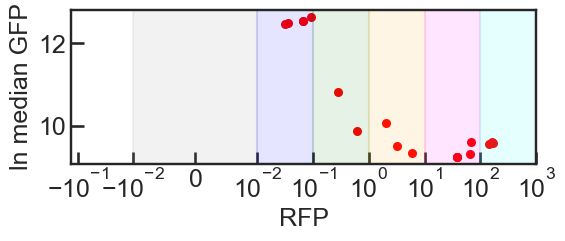

In [11]:

dfslice = df_medians[(df_medians['gRNA'] == 'g5') &
                     (df_medians['Media'] == 'M9')]
rfps = dfslice['median RFP'].values

rfpsQ1inds = np.where(rfps < 0.1)[0]
rfpsQ2inds = np.where((rfps >= 0.1) & (rfps < 1))[0]
rfpsQ3inds = np.where((rfps >= 1) & (rfps < 10))[0]
rfpsQ4inds = np.where((rfps >= 10) & (rfps < 100))[0]
rfpsQ5inds = np.where(rfps >= 100)[0]

rfps_Q_inds_ls = [rfpsQ1inds,
                  rfpsQ2inds,
                  rfpsQ3inds,
                  rfpsQ4inds,
                  rfpsQ5inds]

for n in range(len(rfps_Q_inds_ls)):
    rfpQinds = rfps_Q_inds_ls[n]
    if len(rfpQinds) > 5:
        subsample_inds = np.random.randint(len(rfpQinds), size=5) # subsample down to 5
        rfpQinds = rfpQinds[subsample_inds]
        rfps_Q_inds_ls[n] = rfpQinds

subsampled_rfp_inds = np.concatenate(rfps_Q_inds_ls)
subsampled_rfps = rfps[subsampled_rfp_inds]
gfps = dfslice['ln median GFP'].values
subsampled_gfps = gfps[subsampled_rfp_inds]



# Plot it out
fig, ax = plt.subplots(1,1, figsize=(6,2))
ax.scatter(subsampled_rfps, subsampled_gfps, color='r')
ax.set_xscale('symlog', linthresh=.01)
ax.axvspan(-.01,.01, color='grey', alpha=0.1)
ax.axvspan(.01,.1, color='blue', alpha=0.1)
ax.axvspan(.1,1, color='green', alpha=0.1)
ax.axvspan(1,10, color='orange', alpha=0.1)
ax.axvspan(10,100, color='magenta', alpha=0.1)
ax.axvspan(100,1000, color='cyan', alpha=0.1)
ax.set_xlim((-.13,1e3))
plt.ylabel('ln median GFP')
plt.xlabel('RFP')
plt.show()

Looks like the subsampling procedure worked. Let's rerun MCMC on the subsampled data.

In [12]:
nwalkers = 32
ndim = 4
chain_length = 10000

muB_M9 = 12.7
muB_CL = 6.9
muB_ls = [muB_M9, muB_CL]
sigmaB = 0.5
muA = 6.0
sigmaA = 1
muK = 2.0
sigmaK = 2
muN = 1.0
sigmaN = 1

# hard-code the individual condition of interest
grna = 'g5'
m = 0

media = medias[m]
muB = muB_ls[m]

theta0 = np.exp(np.array([muB, muA, muK, muN])) # <- initial parameter position is in standard scale
prior_params = np.array([np.array([muB, sigmaB]),
                         np.array([muA, sigmaA]),
                         np.array([muK, sigmaK]),
                         np.array([muN, sigmaN]),
                        ])


# random initialization of walkers
pos = 10**(np.log10(theta0) + np.random.randn(nwalkers, len(theta0))*1e-4) # <- not sure how to do this jiggling properly

not_long_enough = True
length_factor = 1        
while not_long_enough:        
    cost_progress = []
    print('Starting MCMC for '+grna+' , '+media+' for '+str(chain_length*length_factor)+' steps...')
    # explicitly run MCMC on subsampled x,y data
    sampler = emcee.EnsembleSampler(nwalkers, ndim, log_probability, args=(subsampled_rfps, subsampled_gfps, prior_params))
    sampler.run_mcmc(pos, chain_length*length_factor, progress=True);

    autocorr_vec = sampler.get_autocorr_time()
    max_tau = np.max(autocorr_vec)
    if max_tau*50 <= chain_length*length_factor:
        not_long_enough = False
    else:
        length_factor *= 10

    if length_factor >= 100:
        print('******* Chain length too long! aborting. ********')
        not_long_enough = False

# pickle the sampler output
filename = grna + '_' + media + '_' + str(nwalkers) + '_' + str(chain_length*length_factor) + '.pkl'
with open('./MCMC_outputs/'+filename, 'wb') as f:
    pickle.dump(sampler, f)
f.close()


Starting MCMC for g5 , M9 for 10000 steps...


100%|███████████████████████████████████| 10000/10000 [00:05<00:00, 1838.28it/s]


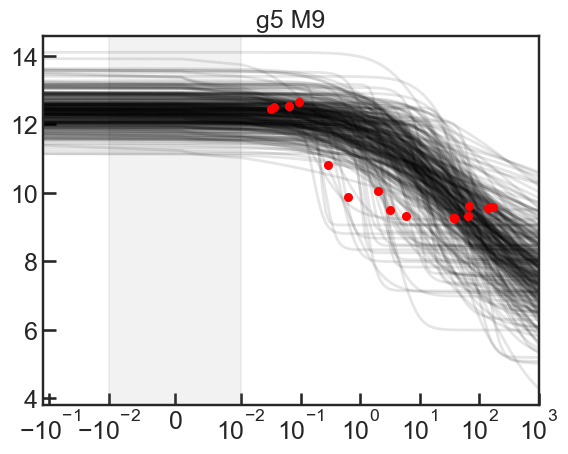

In [13]:
trajectories_to_plot = 300

fig, ax = plt.subplots(1,1)
dfslice = df_medians[(df_medians['gRNA'] == 'g5') &
                     (df_medians['Media'] == 'M9')]
        
filename = './MCMC_outputs/'+'g5'+'_'+'M9'+'_32_10000.pkl'
with open(filename, 'rb') as f:
    sampler = pickle.load(f)
f.close()

flat_samples = sampler.get_chain(discard=9000, flat=True)

inds = np.random.randint(len(flat_samples), size=trajectories_to_plot)
for ind in inds:
    sample = flat_samples[ind]
    xsmooth = np.logspace(-3,3,100)
    ysmooth = np.log(Hill_rep_fun(xsmooth, sample))
    # append a negative point on the far left for plotting
    xsmooth = np.insert(xsmooth, 0, -10)
    ysmooth = np.insert(ysmooth, 0, np.log(Hill_rep_fun(0, sample)))
    
    ax.plot(xsmooth, ysmooth, c='k', alpha=0.1)

ax.scatter(subsampled_rfps, subsampled_gfps, color='r',zorder=100)

ax.set_xscale('symlog', linthresh=.01)
ax.set_title('g5 M9')
ax.axvspan(-.01,.01, color='grey', alpha=0.1)
ax.set_xlim((-.13,1e3))

        
plt.show()

Surprisingly, the subsampling didn't help.

It looks like I may need to weight the data differentially within the cost function.

I can either do this so that data are weighted inversely proportionally to the sampling density, or I can weight the data based on their actual x values and prioritze points in the middle of the curve.

I'll start with sampling-based density weighting for now, but if that doesn't work, I'll try weighting points explicitly in the midrange of the x values.

In [ ]:
# this code block from chatGPT

from sklearn.neighbors import KernelDensity

def compute_x_weights(x, bandwidth=None, min_weight=0.1):
    x = np.asarray(x).reshape(-1, 1)
    if bandwidth is None:
        bandwidth = 0.3 * np.std(np.log1p(np.abs(x)))
    kde = KernelDensity(kernel='gaussian', bandwidth=bandwidth)
    kde.fit(x)    
    log_density = kde.score_samples(x)

    xsmooth = np.logspace(-3,3,1000).reshape(-1,1)
    
    plt.figure(figsize=(6,2))
    plt.scatter(x, log_density)
    plt.plot(xsmooth, kde.score_samples(xsmooth), c='k', lw=1)
    plt.ylabel('log density')
    plt.xlabel('RFP')
    plt.gca().set_xscale('symlog', linthresh=.01)
    plt.gca().axvspan(-.01,.01,color='grey',alpha=0.1)
    plt.gca().set_ylim((-10,0))
    plt.show()
    
    density = np.exp(log_density)
    weights = 1 / (density + 1e-9)
    weights /= np.mean(weights)  # normalize mean=1
    weights = np.clip(weights, min_weight, None)
    return weights



In [ ]:
rfps = dfslice['median RFP'].values
gfps = dfslice['ln median GFP'].values

weights = compute_x_weights(rfps,bandwidth=10)

fig, ax = plt.subplots(2,1,figsize=(6,4), sharex=True)
ax[0].scatter(rfps, gfps)
ax[1].scatter(rfps, weights, c='k')
ax[1].set_xscale('symlog', linthresh=.01)
ax[1].set_yscale('log')
ax[1].set_xlabel('RFP')
ax[0].set_ylabel('ln median GFP')
ax[1].set_ylabel('weight')
ax[0].axvspan(-.01,.01,color='grey',alpha=0.1)
ax[1].axvspan(-.01,.01,color='grey',alpha=0.1)
plt.show()



Something is weird about this weighting function because it is increasing. it should be peaked in the middle.

Since this approach doesn't seem to be working I will instead apply a weight function across the span of x data.

In [ ]:
sw = 1

xsmooth = np.logspace(-3,3,1000)
wsmooth = np.exp(log_lognormal(xsmooth, np.log(np.median(rfps)), sw))
w = np.exp(log_lognormal(rfps, np.log(np.median(rfps)), sw))

w = np.clip(w, a_min=.1, a_max=None)
w /= np.sum(w)

fig, ax = plt.subplots(2,1, figsize=(6,4), sharex=True)
# ax[0].plot(xsmooth, out, c='r')
ax[0].scatter(rfps, w, c='k')
ax[0].set_xscale('symlog',linthresh=.01)
ax[1].set_xlabel('RFP')
ax[0].set_ylabel('weight')
ax[1].scatter(rfps, gfps)
ax[1].set_ylabel('ln GFP')
ax[0].axvspan(-.01,.01,color='grey',alpha=0.1)
ax[1].axvspan(-.01,.01,color='grey',alpha=0.1)
plt.show()

print(sum(w))

This looks OK? Let's try it.

In [15]:
def get_x_weights_from_range(x, mu=None, sigma=1, min_weight=.01):
    '''
    Sets weights for data based on lognormal distribution
    cenetered around the median of x, with sigma=1 by default.
    '''
    if mu==None:
        mu = np.log(np.median(x))
    w = np.exp(log_lognormal(x, mu, sigma))
    w = np.clip(w, a_min=min_weight, a_max=None)
    w /= np.sum(w)
    return w

def weightedL2(a,b,w):
    '''
    Returns the weighted L2 norm between vectors a,b.
    Weighted by vector w.
    '''
    q = a-b
    return np.sqrt((w*q*q).sum())

def log_likelihood_weighted(theta, x, y, weights):
    b, a, K, n = theta
    model = np.log(b / (1 + np.exp(n*(np.log(x) - np.log(K)))) + a) # <- this is ln(Hill rep function), written in numerically stable form

    cost = -1 * weightedL2(y, model, weights)
    cost_progress.append(cost)
    return cost

def log_probability_weighted(theta, x, y, prior_params, weights):
    lp = log_prior(theta, prior_params)
    if not np.isfinite(lp):
        return -np.inf
    return lp + log_likelihood_weighted(theta, x, y, weights)

Re-run MCMC on the one condition using the weighted functions

In [16]:
nwalkers = 32
ndim = 4
chain_length = 10000

muB_M9 = 12.7
muB_CL = 6.9
muB_ls = [muB_M9, muB_CL]
sigmaB = 0.5
muA = 6.0
sigmaA = 1
muK = 2.0
sigmaK = 2
muN = 1.0
sigmaN = 1

# hard-code the individual condition of interest
grna = 'g5'
m = 0

media = medias[m]
muB = muB_ls[m]

theta0 = np.exp(np.array([muB, muA, muK, muN])) # <- initial parameter position is in standard scale
prior_params = np.array([np.array([muB, sigmaB]),
                         np.array([muA, sigmaA]),
                         np.array([muK, sigmaK]),
                         np.array([muN, sigmaN]),
                        ])

# compute weights
weights = get_x_weights_from_range(subsampled_rfps)

# random initialization of walkers
pos = 10**(np.log10(theta0) + np.random.randn(nwalkers, len(theta0))*1e-4) # <- not sure how to do this jiggling properly

not_long_enough = True
length_factor = 1        
while not_long_enough:        
    cost_progress = []
    print('Starting MCMC for '+grna+' , '+media+' for '+str(chain_length*length_factor)+' steps...')
    # explicitly run MCMC on subsampled x,y data
    sampler = emcee.EnsembleSampler(nwalkers, ndim, log_probability_weighted, args=(subsampled_rfps, subsampled_gfps, prior_params, weights))
    sampler.run_mcmc(pos, chain_length*length_factor, progress=True);

    autocorr_vec = sampler.get_autocorr_time()
    max_tau = np.max(autocorr_vec)
    if max_tau*50 <= chain_length*length_factor:
        not_long_enough = False
    else:
        length_factor *= 10

    if length_factor >= 100:
        print('******* Chain length too long! aborting. ********')
        not_long_enough = False

# pickle the sampler output
filename = grna + '_' + media + '_' + str(nwalkers) + '_' + str(chain_length*length_factor) + '.pkl'
with open('./MCMC_outputs/'+filename, 'wb') as f:
    pickle.dump(sampler, f)
f.close()


Starting MCMC for g5 , M9 for 10000 steps...


100%|███████████████████████████████████| 10000/10000 [00:05<00:00, 1721.05it/s]


Nice that introducing the weighted L2 norm function did not significantly speed up the computation.

Let's plot it...

In [17]:
print(weights)

[0.01738856 0.01738856 0.01738856 0.01738856 0.01738856 0.05266344
 0.15542857 0.24759272 0.2051268  0.11313725 0.01738856 0.01738856
 0.01738856 0.01738856 0.01738856 0.01738856 0.01738856 0.01738856]


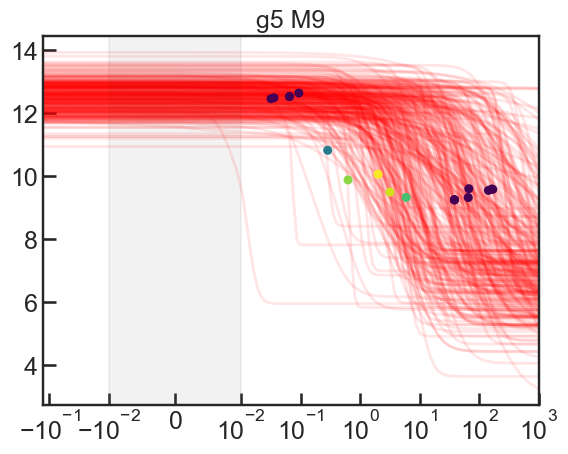

In [18]:
trajectories_to_plot = 300

fig, ax = plt.subplots(1,1)
dfslice = df_medians[(df_medians['gRNA'] == 'g5') &
                     (df_medians['Media'] == 'M9')]
        
filename = './MCMC_outputs/'+'g5'+'_'+'M9'+'_32_10000.pkl'
with open(filename, 'rb') as f:
    sampler = pickle.load(f)
f.close()

flat_samples = sampler.get_chain(discard=9000, flat=True)

inds = np.random.randint(len(flat_samples), size=trajectories_to_plot)
for ind in inds:
    sample = flat_samples[ind]
    xsmooth = np.logspace(-3,3,100)
    ysmooth = np.log(Hill_rep_fun(xsmooth, sample))
    # append a negative point on the far left for plotting
    xsmooth = np.insert(xsmooth, 0, -10)
    ysmooth = np.insert(ysmooth, 0, np.log(Hill_rep_fun(0, sample)))
    
    ax.plot(xsmooth, ysmooth, c='r', alpha=0.1)

ax.scatter(subsampled_rfps, subsampled_gfps, c=np.log10(weights), cmap='viridis', zorder=100)

ax.set_xscale('symlog', linthresh=.01)
ax.set_title('g5 M9')
ax.axvspan(-.01,.01, color='grey', alpha=0.1)
ax.set_xlim((-.13,1e3))
plt.show()

Points are colored by weight (logscale). Somehow it doesn't seem to make any difference, even on the subsampled data. 

There's a possibility that there's something happening where changes are not getting passed through...

What if we ran it again but just did an extreme situation where weights were set to zero?

In [21]:
nwalkers = 32
ndim = 4
chain_length = 10000

muB_M9 = 12.7
muB_CL = 6.9
muB_ls = [muB_M9, muB_CL]
sigmaB = 0.5
muA = 6.0
sigmaA = 1
muK = 2.0
sigmaK = 2
muN = 1.0
sigmaN = 1

# hard-code the individual condition of interest
grna = 'g5'
m = 0

media = medias[m]
muB = muB_ls[m]

theta0 = np.exp(np.array([muB, muA, muK, muN])) # <- initial parameter position is in standard scale
prior_params = np.array([np.array([muB, sigmaB]),
                         np.array([muA, sigmaA]),
                         np.array([muK, sigmaK]),
                         np.array([muN, sigmaN]),
                        ])

# compute weights
weights = get_x_weights_from_range(subsampled_rfps)
weights[weights < .1] = 0 #<- set a bunch of points to zero

# random initialization of walkers
pos = 10**(np.log10(theta0) + np.random.randn(nwalkers, len(theta0))*1e-4) # <- not sure how to do this jiggling properly

not_long_enough = True
length_factor = 1        
while not_long_enough:        
    cost_progress = []
    print('Starting MCMC for '+grna+' , '+media+' for '+str(chain_length*length_factor)+' steps...')
    # explicitly run MCMC on subsampled x,y data
    sampler = emcee.EnsembleSampler(nwalkers, ndim, log_probability_weighted, args=(subsampled_rfps, subsampled_gfps, prior_params, weights))
    sampler.run_mcmc(pos, chain_length*length_factor, progress=True);

    autocorr_vec = sampler.get_autocorr_time()
    max_tau = np.max(autocorr_vec)
    if max_tau*50 <= chain_length*length_factor:
        not_long_enough = False
    else:
        length_factor *= 10

    if length_factor >= 100:
        print('******* Chain length too long! aborting. ********')
        not_long_enough = False

# pickle the sampler output
filename = grna + '_' + media + '_' + str(nwalkers) + '_' + str(chain_length*length_factor) + '.pkl'
with open('./MCMC_outputs/'+filename, 'wb') as f:
    pickle.dump(sampler, f)
f.close()


Starting MCMC for g5 , M9 for 10000 steps...


100%|███████████████████████████████████| 10000/10000 [00:05<00:00, 1705.27it/s]


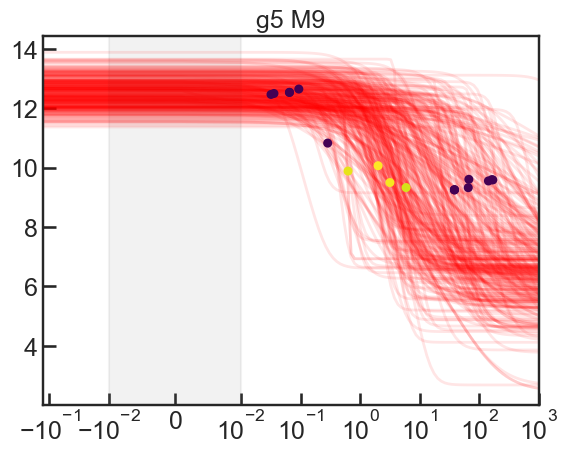

In [22]:
trajectories_to_plot = 300

fig, ax = plt.subplots(1,1)
dfslice = df_medians[(df_medians['gRNA'] == 'g5') &
                     (df_medians['Media'] == 'M9')]
        
filename = './MCMC_outputs/'+'g5'+'_'+'M9'+'_32_10000.pkl'
with open(filename, 'rb') as f:
    sampler = pickle.load(f)
f.close()

flat_samples = sampler.get_chain(discard=9000, flat=True)

inds = np.random.randint(len(flat_samples), size=trajectories_to_plot)
for ind in inds:
    sample = flat_samples[ind]
    xsmooth = np.logspace(-3,3,100)
    ysmooth = np.log(Hill_rep_fun(xsmooth, sample))
    # append a negative point on the far left for plotting
    xsmooth = np.insert(xsmooth, 0, -10)
    ysmooth = np.insert(ysmooth, 0, np.log(Hill_rep_fun(0, sample)))
    
    ax.plot(xsmooth, ysmooth, c='r', alpha=0.1)

ax.scatter(subsampled_rfps, subsampled_gfps, c=np.log10(weights+1e-6), cmap='viridis', zorder=100)

ax.set_xscale('symlog', linthresh=.01)
ax.set_title('g5 M9')
ax.axvspan(-.01,.01, color='grey', alpha=0.1)
ax.set_xlim((-.13,1e3))
plt.show()

 It didn't do anything?? Are the priors too strong? Perhaps the issue is with $\alpha$. It's probably constrained to be way too low.

 I need to reparametrize my $\alpha$ and $\beta$ priors for each condition, probably.

 **Yes, reparametrizing $\alpha$ each time is definitely the key. All this other stuff was the wrong direction to pursue. can do that tomorrow.**